# OG IDEA: Cross-sectional momentum (does not work at cost 0.02)

# Lynx momentum research | slow-trend extension executed

**Decision: Keep the flat-book recommendation: no new candidate passed the development rule.**

Implemented hysteresis, fixed units at entry, infrequent volatility resizing, multi-horizon agreement
and entry cost gates. The original study is retained below and in `lynx_momentum_research_original.ipynb`.
The extension and its exact settings, scorecards, figures and validation follow the original analysis.

| Locked candidate | Internal ordinary net Sharpe | Raw adjusted score | Gross P&L | Fees | Net P&L |
|---|---:|---:|---:|---:|---:|
| costgate2.0 | -0.345 | -0.350 | 0.46 | 3.24 | -2.78 |
| costgate4.0 | 0.166 | 0.163 | 9.47 | 7.56 | 1.91 |
| N03 | -1.234 | -0.960 | 7.37 | 30.47 | -23.10 |
| N00 | -1.979 | 1.814 | 15.62 | 79.80 | -64.18 |
| OLD exploratory | -1.277 | -1.227 | 10.09 | 33.96 | -23.87 |
| OLD baseline | -5.353 | 27.284 | 23.51 | 302.98 | -279.48 |

**Primary settings:** `{"agreement": false, "cost_gate": 2.0, "entry": 1.0, "exit": 0.25, "frequency": 21, "lookbacks": [252], "rank_vol": 63, "resize_band": 0.5, "size_vol": 63, "total_risk_budget": 1.0, "warmup": 1008}`

**Fallback settings:** `{"agreement": false, "cost_gate": 4.0, "entry": 1.0, "exit": 0.25, "frequency": 21, "lookbacks": [252], "rank_vol": 63, "resize_band": 0.5, "size_vol": 63, "total_risk_budget": 1.0, "warmup": 1008}`

The fee is **0.02 per absolute position unit changed**, with the specified two-row accounting lag.
17 new configurations were evaluated on 2001-2004, 2005-2008 and 2009-2012;
0 passed the original development criteria. The original study evaluated 153.

**Validation limitation:** 2013-2016 was already inspected before this extension was proposed. It is
reused internal validation from the supplied in-sample CSV, not fresh evidence. New finalists were
locked before their scores were computed; the actual competition holdout remains untouched.
The complete notebook was executed from a fresh kernel. This table is its delivered result snapshot.
The original study's earlier recommendation is historical; the extension's final decision is authoritative.
The N00 control's positive adjusted score is another score sign reversal: its ordinary net Sharpe and
mean P&L are negative, so that adjusted value does not indicate a successful strategy.


## 1. Central settings and reproducibility

Run all cells in order from a clean kernel, with the supplied files beside this notebook or in `upload/`.
There are no market-data downloads. The academic links are background reading only.
The delivered top summary is a snapshot of this execution; the final cells recompute it.

In [1]:
from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.mplconfig'))
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')

SET = {
    'cost': 0.02,  # per ABSOLUTE POSITION UNIT changed; overrides the PDF
    'cost_sensitivity': [0.0, 0.01, 0.02, 0.04],
    'development': [('2001-01-01','2004-12-31'),
                    ('2005-01-01','2008-12-31'),
                    ('2009-01-01','2012-12-31')],
    'internal_holdout': ('2013-01-01','2016-12-31'),
    'baseline': dict(signal='xs_risk', lookback=126, skip=21, frequency=5,
                     rank_vol=63, size_vol=63, fraction=0.30, weighting='simple',
                     covariance=126, penalty=0.05, overlay='none', risk_window=63,
                     threshold_history=252, threshold_quantile=0.90,
                     partial=1.0, band=0.0, warmup=1008),
    'signal_grid': ['xs_risk','xs_return','ts'],
    'lookbacks': [21,63,126,252], 'skips':[0,5,21], 'frequencies':[1,5,21],
    'rank_vol_grid':[21,63,126], 'size_vol_grid':[21,63,126],
    'covariance_grid':[63,126,252], 'threshold_grid':[0.75,0.90,0.95],
    'partial_grid':[0.25,0.50], 'band_grid':[0.10,0.25],
    'slower_frequencies':[10,42],
    'shortlist_size':2, 'near_tie':0.05,
    'rolling_windows':[63,126,252],
    'bootstrap_blocks':[10,20,40], 'bootstrap_repetitions':1500,
    'seed':20261114, 'n_jobs':4,
    'prefix_cutoffs':['2004-12-31','2008-12-31','2012-12-31','2015-06-30'],
}
assert SET['cost'] == 0.02
OUT = Path('research_output')
OUT.mkdir(exist_ok=True)

In [2]:
# Central settings for the slow-trend extension (fixed before its holdout evaluation).
SLOWSET = {'cost':0.02, 'entry_levels':[0.5,1.0,1.5], 'exit_levels':[0.0,0.25,0.5],
           'resize_bands':[0.25,0.5,1.0,1e9], 'cost_gates':[2.0,4.0],
           'agreement_lookbacks':(63,126,252), 'bootstrap_repetitions':1500,
           'seed':20261115, 'prefix_cutoffs':['2004-12-31','2008-12-31','2012-12-31','2015-06-30']}


In [3]:
import sys, json, hashlib, itertools, time, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
threadpool_limits(1)
pd.set_option('display.max_rows', 180)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi':115, 'savefig.dpi':150,
                     'axes.spines.top':False,'axes.spines.right':False})
VERSIONS = {name:importlib.metadata.version(name) for name in
            ['numpy','pandas','scipy','scikit-learn','matplotlib','seaborn',
             'joblib','nbformat','nbclient','ipykernel']}
print('Python', sys.version.split()[0], '|', platform.machine())
display(pd.Series(VERSIONS, name='executed_version').to_frame())

def find_input(name, alternatives=()):
    for folder in [Path.cwd(), Path.cwd()/'upload', Path('/upload')]:
        for candidate in (name, *alternatives):
            if (folder/candidate).exists():
                return folder/candidate
    raise FileNotFoundError(name)

PRICE_FILE = find_input('prices_insample.csv')
MACRO_FILE = find_input('macro_data_insample.csv')
RULES_FILE = find_input('lynx-hackathon-instructions-2-(2).pdf',
                        ('lynx-hackathon-instructions-2-.pdf',))
INPUT_HASHES = {p.name:hashlib.sha256(p.read_bytes()).hexdigest()
                for p in [PRICE_FILE,MACRO_FILE,RULES_FILE]}
display(pd.Series(INPUT_HASHES,name='SHA256').to_frame())

Python 3.13.5 | arm64


,executed_version
numpy,2.5.4
pandas,3.1.1
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
joblib,1.6.0
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


,SHA256
prices_insample.csv,aa318ebf79b62ad64261030fc3fb0b97ea91e7a46b388b...
macro_data_insample.csv,69106c0e15220e91a86972b158007af90338d25ba8cf60...
lynx-hackathon-instructions-2-.pdf,9e83b269628a8494f13b46f1183b9abe0f54c8d0437f60...


## 2. Rules, evidence and model motivation

The supplied PDF is named `lynx-hackathon-instructions-2-.pdf` in this delivery.
Pages 1 and 3-4 specify the two-row lag, inverse-volatility sizing, the score and holding period.
The organizer example/library is **absent** from the task directory; `upload/` is absent too.
The provided document promises such code but does not specify moment-estimator conventions.
We therefore use sample standard deviation (`ddof=1`), bias-corrected skewness and bias-corrected
**excess** kurtosis. Pearson kurtosis (excess + 3) is a disclosed sensitivity, not a selection switch.

With annualized ordinary Sharpe \(S=\sqrt{252}\bar r/s_r\), the working implementation of PDF (5) is
\[A=S\left(1+\frac{S\,\mathrm{skew}(r)}6-\frac{S^2\,\mathrm{excess}(r)}{24}\right).\]
Annualization occurs **before** the adjustment. Raw scores are never capped. The cubic expression can
reward a very negative Sharpe when its multiplier turns negative; such sign reversals cannot qualify.
Cash has an undefined Sharpe, not a score of zero.

**Why these choices?** These papers motivate mechanisms, not a claim that the synthetic Lynx prices
should reproduce historical equity results:

| Mechanism and study choice | Academic starting point |
|---|---|
| Buy recent winners, sell losers; compare one to twelve observation-month formation windows and skips | [Jegadeesh & Titman (1993), *Returns to Buying Winners and Selling Losers*](https://doi.org/10.1111/j.1540-6261.1993.tb04702.x) |
| Momentum across assets motivates price-change risk normalization and an absolute-trend comparator | [Asness, Moskowitz & Pedersen (2013), *Value and Momentum Everywhere*](https://doi.org/10.1111/jofi.12021) |
| Intermediate and recent performance need not carry equal information; separate lookback from skip | [Novy-Marx (2012), *Is momentum really momentum?*](https://doi.org/10.1016/j.jfineco.2011.05.003) |
| Shrink noisy covariances toward a scaled identity | [Ledoit & Wolf (2004), *A well-conditioned estimator for large-dimensional covariance matrices*](https://www.ledoit.net/Well-conditioned2004.pdf) |
| Estimation error can offset optimization gains; keep simple allocation, bounds and a target penalty | [DeMiguel, Garlappi & Uppal (2009), *Optimal Versus Naive Diversification*](https://doi.org/10.1093/rfs/hhm075) |
| Partial trades can reduce the cost of chasing a moving signal; our rule is a transparent heuristic | [Gârleanu & Pedersen (2013), *Dynamic Trading with Predictable Returns and Transaction Costs*](https://docs.lhpedersen.com/DynamicTrading.pdf) |
| Lower turnover and buy/hold regions can matter more than gross alpha | [Novy-Marx & Velikov (2016), *A Taxonomy of Anomalies and Their Trading Costs*](https://doi.org/10.1093/rfs/hhv063) |
| Time-varying momentum risk motivates a capped continuous exposure rule | [Barroso & Santa-Clara (2015), *Momentum has its moments*](https://doi.org/10.1016/j.jfineco.2014.11.010) |
| Loser rebounds and panic states motivate examining the short leg, tails and risk states | [Daniel & Moskowitz (2016), *Momentum crashes*](https://doi.org/10.1016/j.jfineco.2015.12.002) |
| Trade less in ordinary states: compare conditional high-volatility scaling | [Bongaerts, Kang & van Dijk (2020), *Conditional Volatility Targeting*](https://repub.eur.nl/pub/130215/Bongaerts-Kang-van-Dijk-Conditional-volatility-targeting-2020-FAJ.pdf) |
| Real-time gains are not automatic; avoid ex-post spanning-regression weights | [Cederburg et al. (2020), *On the performance of volatility-managed portfolios*](https://www.lehigh.edu/~xuy219/research/COWY.pdf) |
| Costs can erase volatility-management benefits; evaluate the extra trades at the actual fee | [Barroso & Detzel (2021), *Do limits to arbitrage explain the benefits of volatility-managed portfolios?*](https://doi.org/10.1016/j.jfineco.2021.02.009) |
| Dispersion may flag momentum reversals: an interesting future diagnostic, not an added fitted timer here | [Liu, Zhang, Zhang & Zhao (2025), *Dynamic Momentum Strategies: Return Dispersion and Predictability*](https://ssrn.com/abstract=5287301), **preliminary working paper**, February 17 draft / June 2025 posting |

Continuous and conditional volatility rules are matched experiments, not exact replications of those papers.
The corrected-cost Lynx evidence below determines the recommendation.

## 3. Shared engine (also exported as `lynx_engine.py`)

`xs_risk` ranks \((P_{t-s}-P_{t-s-L})/(\sigma_{t-s}\sqrt L)\);
`xs_return` ranks the corresponding percentage price change; `ts` uses the sign of the risk-normalized
price change. Cross-sectional strategies buy the top 30% and sell the bottom 30% (8 names per side
for 27 valid names). The time-series comparator spends 0.5 risk units on each available sign and leaves
an absent side in cash. Ties use the supplied column order.

The simple target has 0.5 long and 0.5 short allocation in volatility units, divided by current trailing
daily ΔP volatility to get position units. This is a risk-unit budget, not equal dollar notional or exact
equal marginal risk. Stage 1 fixes this sizing rule. Rebalances occur every 1, 5 or 21 **observations**,
anchored to row zero; these are observation intervals, not calendar weeks or months.

The shrinkage variant fits Ledoit-Wolf to selected names' trailing ΔP divided columnwise by their
**current** sizing volatility. It minimizes signed portfolio variance plus
\(0.05\|a-a_0\|^2\), subject to each leg summing to 0.5 and
\(0.5a_0\leq a\leq1.5a_0\). No expected-return estimates are optimized.
The penalty is small, fixed and not tuned. A failed solver falls back to the feasible simple target and
is counted in the audit. A common exposure multiplier preserves the raw target's side split.

The continuous overlay uses a trailing median reference risk divided by current estimated risk,
capped at 0.25-1.5. The conditional overlay scales down only above a trailing quantile threshold,
with a 0.25-1.0 cap. Risk is estimated from the **unscaled reference strategy's lagged gross P&L**,
so there is no recursion through the managed returns. Thresholds use earlier risk estimates only.
Both multipliers update on the same rebalance schedule. Partial rebalancing trades a fixed fraction
of the whole target difference. A portfolio no-trade band measures that difference in current risk units.
Smoothing, old names and volatility drift can change actual executed side exposures; these are measured later.

In [4]:
"""Readable, causal Lynx momentum engine. Also embedded in the research notebook."""
from dataclasses import dataclass, asdict, replace
from functools import lru_cache
import json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from joblib import Parallel, delayed


@dataclass(frozen=True)
class Config:
    signal: str = 'xs_risk'
    lookback: int = 126
    skip: int = 21
    frequency: int = 5
    rank_vol: int = 63
    size_vol: int = 63
    fraction: float = 0.30
    weighting: str = 'simple'
    covariance: int = 126
    penalty: float = 0.05
    overlay: str = 'none'
    risk_window: int = 63
    threshold_history: int = 252
    threshold_quantile: float = 0.90
    partial: float = 1.0
    band: float = 0.0
    warmup: int = 1008


def read_prices(path):
    """Keep the supplied observation calendar; never resample, fill, or backfill."""
    frame = pd.read_csv(path, index_col='AsOfDate', parse_dates=True)
    close = frame.loc[:, frame.columns.str.endswith('|Close')].copy()
    close.columns = close.columns.str.removesuffix('|Close')
    assert len(close.columns) and close.columns.is_unique
    assert close.index.is_unique and close.index.is_monotonic_increasing
    if close.isna().any().any() or not np.isfinite(close.to_numpy()).all():
        raise ValueError('Close data contain gaps: specify a causal missing-quote policy first.')
    return close


def score(pnl, pearson=False):
    """PDF equation (5), with annualized S INSIDE the adjustment. No clipping."""
    y = np.asarray(pnl, dtype=float)
    y = y[np.isfinite(y)]
    n = len(y)
    mean = y.mean() if n else np.nan
    sd = y.std(ddof=1) if n > 1 else np.nan
    empty = dict(adjusted=np.nan, sharpe=np.nan, mean=mean, sd=sd,
                 skew=np.nan, excess=np.nan, factor=np.nan)
    if n < 4 or not np.isfinite(sd) or sd <= 1e-14:
        return empty
    s = np.sqrt(252) * mean / sd
    sk = stats.skew(y, bias=False)
    ex = stats.kurtosis(y, fisher=True, bias=False)
    factor = 1 + s * sk / 6 - s**2 * (ex + (3 if pearson else 0)) / 24
    return dict(adjusted=s*factor, sharpe=s, mean=mean, sd=sd,
                skew=sk, excess=ex, factor=factor)


def backtest(prices, positions, cost=0.02):
    """Decide t, execute close t+1, book P&L AND the specified fee at t+2.

    Positions start at zero. A reversal +a -> -a trades 2a units.
    The final two desired rows have not yet generated P&L/fees in this sample.
    There is no artificial terminal liquidation.
    """
    x = positions.reindex_like(prices).fillna(0.0)
    delta = x.diff()
    delta.iloc[0] = x.iloc[0]  # entry relative to the zero position before the file
    held = x.shift(2).fillna(0.0)
    units = delta.shift(2).fillna(0.0).abs()
    asset_gross = held * prices.diff().fillna(0.0)
    asset_fees = cost * units
    asset_net = asset_gross - asset_fees
    daily = pd.DataFrame({'gross':asset_gross.sum(axis=1),
                          'fees':asset_fees.sum(axis=1),
                          'net':asset_net.sum(axis=1),
                          'traded_units':units.sum(axis=1),
                          'held_units':held.abs().sum(axis=1)}, index=prices.index)
    return dict(x=x, held=held, delta=delta, asset_gross=asset_gross,
                asset_fees=asset_fees, asset_net=asset_net, daily=daily)


class MomentumEngine:
    """One shared implementation; cached trailing inputs, independent configurations."""
    def __init__(self, prices):
        self.p = prices
        self.dp = prices.diff()
        self.values = prices.to_numpy()
        self.changes = self.dp.to_numpy()

    @lru_cache(maxsize=None)
    def volatility(self, window):
        # Sample standard deviation of price CHANGES, not percentage returns.
        return self.dp.rolling(window, min_periods=window).std(ddof=1).to_numpy()

    @lru_cache(maxsize=None)
    def signal(self, kind, lookback, skip, rank_vol):
        change = self.p.shift(skip) - self.p.shift(skip + lookback)
        if kind in ('xs_risk', 'ts'):
            denom = pd.DataFrame(self.volatility(rank_vol), index=self.p.index,
                                 columns=self.p.columns).shift(skip) * np.sqrt(lookback)
            return (change / denom.where(denom > 1e-10)).to_numpy()
        if kind == 'xs_return':
            # Relative-price momentum is a matched alternative, not external returns.
            return (self.p.shift(skip) / self.p.shift(skip+lookback) - 1).to_numpy()
        raise ValueError(kind)

    def _allocation(self, t, c, sig, vol):
        n = len(vol)
        valid = np.isfinite(sig) & np.isfinite(vol) & (vol > 1e-10)
        ids = np.flatnonzero(valid)
        w = np.zeros(n)
        if len(ids) < 6:
            return w, None
        ordered = ids[np.argsort(sig[ids], kind='stable')]
        if c.signal == 'ts':
            longs = ids[sig[ids] > 0]
            shorts = ids[sig[ids] < 0]
        else:
            k = max(1, int(len(ids)*c.fraction))
            shorts, longs = ordered[:k], ordered[-k:]
        selected = np.r_[longs, shorts]
        signs = np.r_[np.ones(len(longs)), -np.ones(len(shorts))]
        if not len(selected):
            return w, None
        a0 = np.r_[np.full(len(longs), 0.5/max(1,len(longs))),
                   np.full(len(shorts), 0.5/max(1,len(shorts)))]
        a = a0.copy()
        fit = None
        if c.weighting == 'tilt':
            for side in [np.arange(len(longs)), np.arange(len(longs),len(selected))]:
                if len(side):
                    strength = np.abs(sig[selected[side]])
                    order = stats.rankdata(strength, method='average')
                    tilts = 0.5 + order / len(side)
                    a[side] = 0.5 * tilts/tilts.sum()
        elif c.weighting == 'lw':
            # Every selected name's entire history is standardized by TODAY'S sigma.
            history = self.changes[t-c.covariance+1:t+1, selected] / vol[selected]
            if history.shape[0] != c.covariance or not np.isfinite(history).all():
                return w, None
            covariance = LedoitWolf().fit(history).covariance_
            signed_cov = covariance * np.outer(signs, signs)
            side_rows = []
            if len(longs):
                side_rows.append(np.r_[np.ones(len(longs)), np.zeros(len(shorts))])
            if len(shorts):
                side_rows.append(np.r_[np.zeros(len(longs)), np.ones(len(shorts))])
            A = np.asarray(side_rows)
            objective = lambda z: z@signed_cov@z + c.penalty*np.sum((z-a0)**2)
            gradient = lambda z: 2*signed_cov@z + 2*c.penalty*(z-a0)
            result = minimize(objective, a0, jac=gradient, method='SLSQP',
                              bounds=list(zip(0.5*a0,1.5*a0)),
                              constraints={'type':'eq','fun':lambda z:A@z-0.5,
                                           'jac':lambda z:A},
                              options={'ftol':1e-10, 'maxiter':100})
            ok = bool(result.success and np.max(np.abs(A@result.x-0.5)) < 1e-7)
            a = result.x if ok else a0
            # Audit is attached to the raw target, before exposure scaling/smoothing.
            fit = dict(date=self.p.index[t], success=ok,
                       minimum_ratio=float(np.min(a/a0)),
                       maximum_ratio=float(np.max(a/a0)),
                       long_sum=float(a[:len(longs)].sum()),
                       short_sum=float(a[len(longs):].sum()),
                       covariance_min_eigenvalue=float(np.linalg.eigvalsh(covariance)[0]))
        w[selected] = signs*a
        return w / vol, fit

    def positions(self, c):
        """No training labels: trailing covariance and risk fits end at decision t."""
        sig = self.signal(c.signal,c.lookback,c.skip,c.rank_vol)
        vols = self.volatility(c.size_vol)
        nrows, nassets = self.values.shape
        base = np.zeros((nrows,nassets))
        audit = []
        previous = np.zeros(nassets)
        for t in range(nrows):
            # Anchor schedule to the first supplied row, independent of file end.
            if t >= c.warmup and t % c.frequency == 0:
                previous, fit = self._allocation(t,c,sig[t],vols[t])
                if fit is not None:
                    audit.append(fit)
            base[t] = previous
        base_frame = pd.DataFrame(base,index=self.p.index,columns=self.p.columns)
        reference_gross = (base_frame.shift(2).fillna(0)*self.dp.fillna(0)).sum(axis=1)
        risk = reference_gross.rolling(c.risk_window,min_periods=c.risk_window).std(ddof=1)
        # Prior risk estimates set the threshold/reference; current risk includes t.
        past = risk.where(risk > 1e-10).shift(1).rolling(
            c.threshold_history,min_periods=c.threshold_history)
        threshold = past.quantile(c.threshold_quantile)
        target_risk = past.median()
        if c.overlay == 'continuous':
            multiplier = (target_risk/risk).clip(0.25,1.5).fillna(0.0)
        elif c.overlay == 'conditional':
            multiplier = pd.Series(1.0,index=self.p.index)
            high = risk > threshold
            multiplier.loc[high] = (threshold[high]/risk[high]).clip(0.25,1.0)
            multiplier.loc[threshold.isna()] = 0.0
        else:
            multiplier = pd.Series(1.0,index=self.p.index)
        x = np.zeros_like(base)
        pre_smoothing = np.zeros_like(base)
        applied_multiplier = np.zeros(nrows)
        previous = np.zeros(nassets)
        target = np.zeros(nassets)
        applied = 0.0
        for t in range(nrows):
            if t >= c.warmup and t % c.frequency == 0:
                applied = multiplier.iloc[t]
                target = base[t]*applied
                trade = target-previous
                # Portfolio-wide no-trade band in CURRENT risk units; then partial trade.
                risk_distance = np.nansum(np.abs(trade)*vols[t])
                if risk_distance >= c.band:
                    previous = previous + c.partial*trade
            x[t] = previous
            pre_smoothing[t] = target
            applied_multiplier[t] = applied
        frame = pd.DataFrame(x,index=self.p.index,columns=self.p.columns)
        diagnostics = pd.DataFrame({'reference_vol':risk, 'threshold':threshold,
                                    'reference_target':target_risk,
                                    'requested_multiplier':multiplier,
                                    'applied_multiplier':applied_multiplier},index=self.p.index)
        return dict(x=frame, base=base_frame,
                    target=pd.DataFrame(pre_smoothing,index=self.p.index,columns=self.p.columns),
                    diagnostic=diagnostics, audit=pd.DataFrame(audit))


def evaluate(engine, c, cost=0.02):
    generated = engine.positions(c)
    return {'config':c, **generated, **backtest(engine.p,generated['x'],cost)}


def evaluate_many(engine, configs, cost=0.02, n_jobs=4, compact=True):
    # Thread workers share cached arrays. Pre-warm caches before concurrent reads.
    for c in configs:
        engine.volatility(c.size_vol)
        engine.signal(c.signal,c.lookback,c.skip,c.rank_vol)
    def run(c):
        result = evaluate(engine,c,cost)
        return {k:result[k] for k in ['config','daily']} if compact else result
    return Parallel(n_jobs=n_jobs, prefer='threads')(delayed(run)(c) for c in configs)


def combine(engine, configs, cost=0.02):
    """Equal sleeves; net their trades BEFORE charging costs (not average sleeve fees)."""
    sleeves = [engine.positions(c)['x'] for c in configs]
    x = sum(sleeves)/len(sleeves)
    return dict(config=tuple(configs), **backtest(engine.p,x,cost))


def drawdown(pnl):
    curve = pnl.cumsum()
    return curve - curve.cummax().clip(lower=0)


def scorecard(result, dates):
    d = result['daily'].loc[dates]
    s = score(d.net)
    traded = d.traded_units.sum()
    return dict(adjusted=s['adjusted'], net_sharpe=s['sharpe'],
                gross_sharpe=score(d.gross)['sharpe'], mean_net=s['mean'],
                skew=s['skew'], excess=s['excess'], factor=s['factor'],
                pearson_adjusted=score(d.net,pearson=True)['adjusted'],
                holding_days=2*d.held_units.sum()/traded if traded > 0 else np.nan,
                turnover=traded/(2*d.held_units.sum()) if d.held_units.sum()>0 else 0,
                fees=d.fees.sum(), net_pnl=d.net.sum(), gross_pnl=d.gross.sum(),
                max_drawdown=-drawdown(d.net).min(), traded_units=traded,
                break_even_cost=d.gross.sum()/traded if traded>0 else np.nan,
                observations=len(d))


def config_to_dict(c):
    return {'sleeves':[asdict(x) for x in c]} if isinstance(c,tuple) else asdict(c)


def config_from_dict(d):
    return tuple(Config(**x) for x in d['sleeves']) if 'sleeves' in d else Config(**d)


def generate_daily_targets(price_file, configuration, output_file=None):
    """Replay the full available history (same origin) for a new organizer-format CSV.

    Return desired X[t], not lagged realized positions. Append new rows to the original
    history; replay preserves rolling fits, rebalance phase and partial-trade state.
    """
    flat = False
    if isinstance(configuration,(str,Path)):
        wrapper = json.loads(Path(configuration).read_text())
        flat = wrapper.get('submission_is_flat',False)
        configuration = wrapper['submission_config']
    c = config_from_dict(configuration) if isinstance(configuration,dict) else configuration
    p = read_prices(price_file)
    engine = MomentumEngine(p)
    x = combine(engine,c)['x'] if isinstance(c,tuple) else engine.positions(c)['x']
    if flat:
        x = x*0
    x.index.name = 'AsOfDate'
    if output_file:
        x.to_csv(output_file)
    return x

## 4. Input audit: actual calendar and unused macro information

In [5]:
P = read_prices(PRICE_FILE)
raw = pd.read_csv(PRICE_FILE, index_col='AsOfDate', parse_dates=True)
macro = pd.read_csv(MACRO_FILE, index_col='AsOfDate', parse_dates=True)
assert P.index.min().year == 1995 and P.index.max().year == 2016
assert macro.index.is_unique and macro.index.is_monotonic_increasing
audit_inputs = pd.DataFrame({
    'price_OHLC':[len(raw),len(raw.columns),raw.isna().sum().sum(),str(raw.index[0].date()),str(raw.index[-1].date())],
    'Close_used':[len(P),len(P.columns),P.isna().sum().sum(),str(P.index[0].date()),str(P.index[-1].date())],
    'macro_unused':[len(macro),len(macro.columns),macro.isna().sum().sum(),str(macro.index[0].date()),str(macro.index[-1].date())]},
    index=['rows','columns','missing_cells','first_date','last_date'])
display(audit_inputs)
display(P.describe().loc[['min','50%','max']].T)
display(pd.DataFrame({'rows':P.groupby(P.index.year).size(),
                      'nonzero_changes':P.diff().ne(0).sum(axis=1).groupby(P.index.year).mean()}))
display(macro.describe().loc[['min','50%','max']].T)
print('Macro nonzero-change fractions:')
display(macro.diff().ne(0).mean().rename('fraction').to_frame())
duplicates = [(a,b) for a,b in itertools.combinations(P.columns,2)
              if np.allclose(P[a],P[b],rtol=0,atol=1e-12)]
print('Whole-file identical Close pairs (audit only; no future-based removal):', duplicates)
print('Calendar gap counts, days:', P.index.to_series().diff().dt.days.value_counts().sort_index().to_dict())
print('Auxiliary source search:')
aux = []
for folder in [Path.cwd(),Path('upload'),Path('/upload')]:
    if folder.exists():
        aux += [str(p) for p in folder.glob('*') if p.suffix.lower() in ['.py','.ipynb','.zip','.whl']
                and p.name not in ['lynx_engine.py','build_notebook.py','execute_notebook.py',
                                   'lynx_momentum_research.ipynb','generate_targets.py']]
print(aux or 'No supplied organizer code or scoring library found.')

,price_OHLC,Close_used,macro_unused
rows,5702,5702,8036
columns,108,27,10
missing_cells,1067,0,0
first_date,1995-01-02,1995-01-02,1995-01-01
last_date,2016-12-30,2016-12-30,2016-12-31


,min,50%,max
ganymede_bonds,0.9754,1.6011,2.7103
ganymede_stocks,0.9518,1.9340,2.6562
ganymede_titan_fx,0.8498,1.1965,1.6172
io_bonds,0.9966,1.3819,2.1907
io_stocks,0.7536,1.4767,2.5835
io_titan_fx,0.6514,0.9557,1.2858
titan_bonds,0.9989,1.6399,2.7647
titan_stocks,0.8372,1.7385,3.3233
callisto_bonds,1.0011,1.6336,1.9827
callisto_stocks,0.4273,0.8128,1.5403


,rows,nonzero_changes
AsOfDate,,
1995,259,25.9459
1996,260,25.8077
1997,259,25.8456
1998,259,25.9035
1999,260,25.8885
2000,259,26.1274
2001,259,25.6911
2002,259,25.8687
2003,259,25.8224


,min,50%,max
gdp|ganymede,100.0000,124.1349,153.5193
gdp|io,100.0000,116.5436,136.9716
gdp|titan,100.0000,112.4764,127.4579
gdp|callisto,100.0000,117.1265,135.5519
gdp|europa,100.0000,118.5437,141.0922
cpi|ganymede,100.0000,124.6279,149.4226
cpi|io,99.9837,132.3742,182.2391
cpi|titan,99.9904,132.0917,161.5385
cpi|callisto,97.9441,99.8587,103.0894
cpi|europa,100.0000,116.3841,135.2843


Macro nonzero-change fractions:


,fraction
gdp|ganymede,1.0000
gdp|io,1.0000
gdp|titan,1.0000
gdp|callisto,1.0000
gdp|europa,1.0000
cpi|ganymede,1.0000
cpi|io,1.0000
cpi|titan,1.0000
cpi|callisto,1.0000
cpi|europa,1.0000


Whole-file identical Close pairs (audit only; no future-based removal): []
Calendar gap counts, days: {1.0: 4534, 2.0: 20, 3.0: 1131, 4.0: 14, 5.0: 2}
Auxiliary source search:
['/Users/eriksalumae/Downloads/untitled folder/generate_slow_targets.py', '/Users/eriksalumae/Downloads/untitled folder/lynx_momentum_research_original.ipynb', '/Users/eriksalumae/Downloads/untitled folder/slow_trend_engine.py', '/Users/eriksalumae/Downloads/untitled folder/extend_slow_study.py', '/Users/eriksalumae/Downloads/untitled folder/lynx_momentum_research_bundle.zip']


Only Close columns enter signals and P&L. All Close observations are complete, so the engine needs
no missing-data imputation and rejects a new file with Close gaps. Rows with exchange holidays remain
absent; the 252 factor is the organizer's convention, not a resampling instruction.

Macro data contain GDP and CPI levels for ganymede, io, titan, callisto and europa on a calendar-daily
index. Growth/inflation changes could motivate a later macro-regime study, aligned as-of to the decision
close. Without revision vintages or explicit release timestamps, this file does not establish that real-world
GDP/CPI surprises would have been tradable. We do not use macro variables in signals, fits or selection.
Names and prices are synthetic; asset classes below are inferred from names. Highly related materials
are retained rather than removed using knowledge from the entire period.

## 5. Hand timing and accounting checks

At row 1, desire +2; it executes at close row 2 and earns the row-3 price change.
At row 3, reverse +2 to -1: three position units trade, and the 0.06 fee is booked on row 5.
This follows the requested fee-booking convention even though execution is one row earlier.

In [6]:
toy_p = pd.DataFrame({'asset':[10,11,13,12,14,15,16,15]},
                     index=pd.date_range('2000-01-01',periods=8))
toy_x = pd.DataFrame({'asset':[0,2,2,-1,0,0,0,0]},index=toy_p.index)
toy = backtest(toy_p,toy_x,SET['cost'])
expected_gross = np.array([0,0,0,-2,4,-1,0,0],dtype=float)
expected_fees = np.array([0,0,0,.04,0,.06,.02,0])
np.testing.assert_allclose(toy['daily'].gross,expected_gross)
np.testing.assert_allclose(toy['daily'].fees,expected_fees)
assert toy['daily'].fees.iloc[5] == 3*SET['cost']
flat = backtest(toy_p,toy_x*0,SET['cost'])
assert (flat['daily'][['gross','net','fees']] == 0).all().all()
first_entry = backtest(toy_p,pd.DataFrame(1.0,index=toy_p.index,columns=toy_p.columns),SET['cost'])
assert first_entry['daily'].fees.iloc[2] == SET['cost']
# Opposing sleeves cancel: cost must be charged on combined position changes.
opposing = backtest(toy_p,(toy_x-toy_x)/2,SET['cost'])
assert opposing['daily'].fees.sum() == 0
assert score(np.zeros(20))['adjusted'] != score(np.zeros(20))['adjusted']
display(pd.DataFrame({'price':toy_p.asset,'desired':toy_x.asset,
                      'executed_at_close':toy_x.asset.shift(1).fillna(0),
                      'earning_position':toy['held'].asset,
                      'gross_hand':expected_gross,'fee_hand':expected_fees,
                      'net_engine':toy['daily'].net}))
print('PASS: lag, entry, reversal, exit, flat book, sleeve netting, undefined zero-variance Sharpe.')

,price,desired,executed_at_close,earning_position,gross_hand,fee_hand,net_engine
2000-01-01,10,0,0.0000,0.0000,0.0000,0.0000,0.0000
2000-01-02,11,2,0.0000,0.0000,0.0000,0.0000,0.0000
2000-01-03,13,2,2.0000,0.0000,0.0000,0.0000,0.0000
2000-01-04,12,-1,2.0000,2.0000,-2.0000,0.0400,-2.0400
2000-01-05,14,0,-1.0000,2.0000,4.0000,0.0000,4.0000
2000-01-06,15,0,0.0000,-1.0000,-1.0000,0.0600,-1.0600
2000-01-07,16,0,0.0000,0.0000,0.0000,0.0200,-0.0200
2000-01-08,15,0,0.0000,0.0000,0.0000,0.0000,0.0000


PASS: lag, entry, reversal, exit, flat book, sleeve netting, undefined zero-variance Sharpe.


## 6. Selection rule, written before any internal-holdout scoring

1. Use development blocks **2001-2004, 2005-2008, 2009-2012** with earlier rows for warm-up.
   All configurations begin decisions after row 1008; evaluation uses the same observed dates from
   2001 onward. Rolling inputs, covariance and overlay thresholds are then fully warmed up.
2. Stage 1 varies signal, formation, skip and rebalance interval with fixed inverse-63-day-ΔP-volatility
   sizing. Select a two-configuration development shortlist. Stage 2 changes weighting, ranking/sizing
   volatility, covariance history, overlays and cost controls **one at a time** on that shortlist. Then test
   a few specified combinations and one equal-sleeve blend, with fees charged after combining positions.
3. A configuration is eligible only if pooled development mean net P&L is positive, at least two blocks
   have positive ordinary and adjusted net Sharpe, all block adjusted scores are finite and every
   adjustment multiplier is positive. This rejects the adjustment's negative-Sharpe sign-reversal trick.
   A bad third block remains visible. All failed variants and raw block scores are exported.
4. Rank eligible strategies by median block net adjusted Sharpe. Treat scores within 0.05 of the best
   as near-ties; choose lower cross-block score standard deviation, then lower unit-based turnover,
   then the larger median score. Reapply this rule to choose a second name. If no strategy qualifies,
   exploratory shortlists use median **ordinary** net Sharpe and turnover; they are explicitly ineligible.
5. Freeze the submission candidate, a simpler Stage-1 fallback, and the best shrinkage-plus-partial and
   overlay diagnostics before holdout scoring. Diagnostic finalists may fail eligibility; this is disclosed.
   Evaluate only these plus the baseline and original shortlist on 2013-2016. Do not select a new winner
   from internal-holdout rankings. If no development candidate qualifies, the submission is a flat book;
   a trading fallback is a disclosed research candidate, not a validated profitable strategy.

**Contamination disclosure:** 2013-2016 is part of the supplied **in-sample** CSV and was previously
inspected under the old fee assumption. It is only a final internal check, not pristine out-of-sample
evidence. The actual competition holdout is not supplied, accessed or used. No supervised forecast
is fitted in this study; every covariance/risk fit ends at the decision close. A future predictive model
would need walk-forward labels whose payoff ends no later than that close (a feature at t needs its
t+2 label to have arrived before training).

In [7]:
BASE = Config(**SET['baseline'])
DEV_END = SET['development'][-1][1]
Pdev = P.loc[:DEV_END]
dev_engine = MomentumEngine(Pdev)  # no corrected-cost holdout P&L exists yet
DEV_DATES = Pdev.index[Pdev.index >= SET['development'][0][0]]
BLOCKS = {f'{a[:4]}-{b[:4]}':Pdev.loc[a:b].index for a,b in SET['development']}
assert len(DEV_DATES) == sum(map(len,BLOCKS.values()))
print('Common development observations:',len(DEV_DATES))
display(pd.Series({k:len(v) for k,v in BLOCKS.items()},name='common_rows').to_frame())

configs, results, stage = {}, {}, {}
def add_batch(proposals, stage_name):
    unique = []
    for label,c in proposals:
        if c not in configs.values() and c not in [v for _,v in unique]:
            unique.append((label,c))
    runs = evaluate_many(dev_engine,[c for _,c in unique],SET['cost'],SET['n_jobs'])
    for (label,c),r in zip(unique,runs):
        configs[label],results[label],stage[label] = c,r,stage_name
    print(stage_name, ':',len(unique),'new configurations; total',len(configs))

def development_tables():
    rows = []
    for name,r in results.items():
        for block,dates in BLOCKS.items():
            rows.append(dict(name=name,block=block,**scorecard(r,dates)))
    raw_scores = pd.DataFrame(rows)
    summaries = []
    for name,r in results.items():
        b = raw_scores[raw_scores.name == name]
        pooled = scorecard(r,DEV_DATES)
        finite = np.isfinite(b.adjusted).all()
        positive = int(((b.adjusted>0)&(b.net_sharpe>0)&(b.mean_net>0)).sum())
        factors_ok = bool((b.factor>0).all())
        qualified = bool(finite and positive>=2 and pooled['mean_net']>0 and factors_ok)
        reasons = []
        if not finite: reasons.append('undefined score')
        if positive<2: reasons.append('fewer than 2 positive blocks')
        if pooled['mean_net']<=0: reasons.append('nonpositive pooled mean')
        if not factors_ok: reasons.append('adjustment sign reversal')
        summaries.append(dict(name=name,stage=stage[name],median_adjusted=b.adjusted.median(),
                              worst_adjusted=b.adjusted.min(),block_sd=b.adjusted.std(ddof=1),
                              median_ordinary=b.net_sharpe.median(),positive_blocks=positive,
                              mean_net=pooled['mean_net'],turnover=pooled['turnover'],
                              eligible=qualified,failure='; '.join(reasons)))
    return raw_scores,pd.DataFrame(summaries).set_index('name')

def choose(table, count=1):
    pool = table[table.eligible].copy()
    if pool.empty:
        return table.sort_values(['median_ordinary','turnover'],ascending=[False,True]).head(count).index.tolist()
    chosen=[]
    while len(chosen)<count and len(pool):
        best=pool.median_adjusted.max()
        near=pool[pool.median_adjusted >= best-SET['near_tie']]
        pick=near.sort_values(['block_sd','turnover','median_adjusted'],ascending=[True,True,False]).index[0]
        chosen.append(pick)
        pool=pool.drop(pick)
    return chosen

proposals=[]
for i,(signal,L,skip,freq) in enumerate(itertools.product(
        SET['signal_grid'],SET['lookbacks'],SET['skips'],SET['frequencies'])):
    c=replace(BASE,signal=signal,lookback=L,skip=skip,frequency=freq)
    proposals.append(('BASE' if c==BASE else f'S{i:03d}',c))
started=time.perf_counter()
add_batch(proposals,'1_signal_frequency')
block_scores,development=development_tables()
shortlist=choose(development,SET['shortlist_size'])
print('Stage 1 shortlist:',shortlist,'| elapsed seconds:',round(time.perf_counter()-started,1))
display(development.sort_values('median_adjusted',ascending=False))

Common development observations: 3112


,common_rows
2001-2004,1038
2005-2008,1037
2009-2012,1037


1_signal_frequency : 108 new configurations; total 108


Stage 1 shortlist: ['S065', 'S101'] | elapsed seconds: 7.8


,stage,median_adjusted,worst_adjusted,block_sd,median_ordinary,positive_blocks,mean_net,turnover,eligible,failure
name,,,,,,,,,,
S078,1_signal_frequency,500.9090,139.1271,256.9958,-20.5108,0,-0.9582,0.1494,False,fewer than 2 positive blocks; nonpositive pool...
S075,1_signal_frequency,481.0136,56.9379,330.8323,-20.9357,0,-0.9542,0.1485,False,fewer than 2 positive blocks; nonpositive pool...
S072,1_signal_frequency,448.8386,171.3928,238.5561,-21.1672,0,-0.9462,0.1484,False,fewer than 2 positive blocks; nonpositive pool...
S036,1_signal_frequency,286.6855,107.3306,122.6964,-23.0113,0,-0.9924,0.1628,False,fewer than 2 positive blocks; nonpositive pool...
S042,1_signal_frequency,209.8753,36.3011,137.3402,-23.0368,0,-1.0065,0.1653,False,fewer than 2 positive blocks; nonpositive pool...
S039,1_signal_frequency,193.5265,-14.0690,248.1170,-22.6093,0,-0.9971,0.1634,False,fewer than 2 positive blocks; nonpositive pool...
S006,1_signal_frequency,138.2193,130.2338,23.9967,-23.2370,0,-1.0355,0.1608,False,fewer than 2 positive blocks; nonpositive pool...
S003,1_signal_frequency,128.7276,112.0014,29.2754,-23.3494,0,-1.0355,0.1592,False,fewer than 2 positive blocks; nonpositive pool...
S093,1_signal_frequency,118.4236,17.1968,100.8930,-12.9056,0,-0.4638,0.0721,False,fewer than 2 positive blocks; nonpositive pool...


## 7. Stage-1 parameter regions in development

Every annotated number below uses net P&L at cost 0.02, the common development dates, fixed sizing,
and the displayed signal and observation frequency. The panels report medians across blocks first;
the next plot separates the blocks. A broad plateau is more persuasive than one isolated cell.

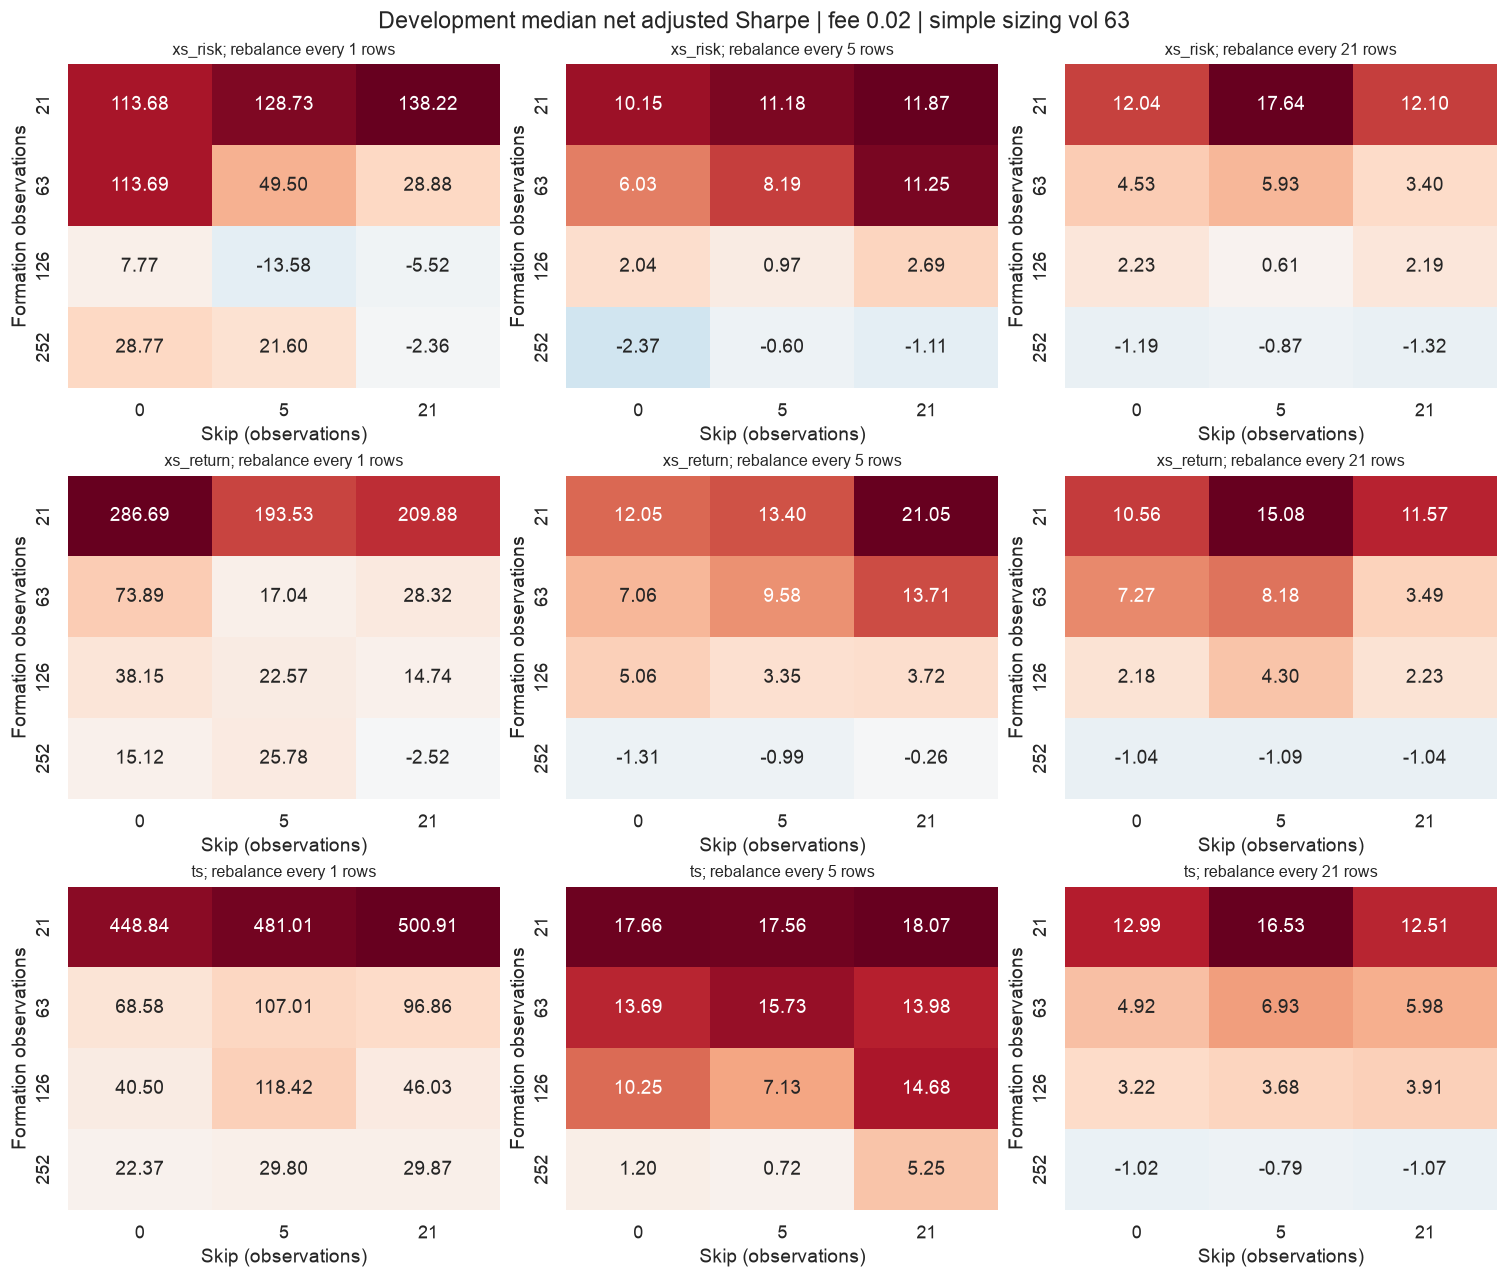

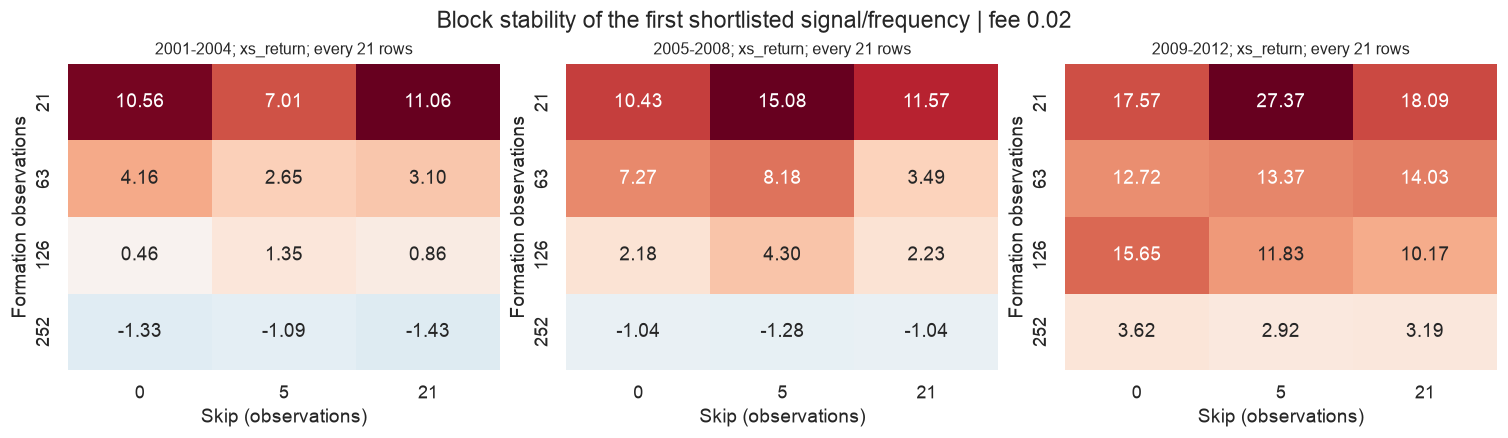

,name,signal,lookback,skip,frequency,median_adjusted,worst_adjusted,eligible
78,S078,ts,21,21,1,500.9090,139.1271,False


In [8]:
stage1_names = [n for n in configs if stage[n]=='1_signal_frequency']
stage1_frame = pd.DataFrame([dict(name=n,**asdict(configs[n]),**development.loc[n].to_dict())
                             for n in stage1_names])
def heat(ax,frame,value,title,limit=None):
    pivot=frame.pivot_table(index='lookback',columns='skip',values=value,aggfunc='mean')
    pivot=pivot.reindex(index=SET['lookbacks'],columns=SET['skips'])
    sns.heatmap(pivot,ax=ax,annot=True,fmt='.2f',center=0,cmap='RdBu_r',
                vmin=-limit if limit else None,vmax=limit,cbar=False)
    ax.set_title(title,fontsize=10)
    ax.set_xlabel('Skip (observations)'); ax.set_ylabel('Formation observations')

fig,axes=plt.subplots(3,3,figsize=(13,11),layout='constrained')
for i,signal in enumerate(SET['signal_grid']):
    for j,freq in enumerate(SET['frequencies']):
        f=stage1_frame[(stage1_frame.signal==signal)&(stage1_frame.frequency==freq)]
        heat(axes[i,j],f,'median_adjusted',f'{signal}; rebalance every {freq} rows')
fig.suptitle('Development median net adjusted Sharpe | fee 0.02 | simple sizing vol 63')
fig.savefig(OUT/'01_stage1_heatmaps.png',bbox_inches='tight'); plt.show()

anchor=configs[shortlist[0]]
fig,axes=plt.subplots(1,3,figsize=(13,3.7),layout='constrained')
for ax,(block,dates) in zip(axes,BLOCKS.items()):
    f=stage1_frame[(stage1_frame.signal==anchor.signal)&(stage1_frame.frequency==anchor.frequency)]
    f=f.merge(block_scores[block_scores.block==block][['name','adjusted']],on='name')
    heat(ax,f,'adjusted',f'{block}; {anchor.signal}; every {anchor.frequency} rows')
fig.suptitle('Block stability of the first shortlisted signal/frequency | fee 0.02')
fig.savefig(OUT/'02_block_heatmaps.png',bbox_inches='tight'); plt.show()
near=stage1_frame[stage1_frame.median_adjusted>=stage1_frame.median_adjusted.max()-0.10]
display(near[['name','signal','lookback','skip','frequency','median_adjusted','worst_adjusted','eligible']])

## 8. Stage 2: matched allocation, volatility and cost experiments

The shortlist is chosen using development data only. Each one-factor comparison below keeps its
parent's signal, formation, skip and other settings fixed. Covariance-history tests are matched to the
126-row shrinkage version. Threshold tests are matched to conditional scaling; the continuous overlay
is a separate mechanism. Cost controls compare partial fractions, a risk-unit no-trade band, and two
slower observation intervals. The specified combinations follow, rather than a Cartesian product.

In [9]:
matched=[]
for parent in shortlist:
    c=configs[parent]
    variants=[('weight_tilt',replace(c,weighting='tilt')),
              ('weight_lw',replace(c,weighting='lw')),
              ('continuous',replace(c,overlay='continuous'))]
    variants += [(f'rank{v}',replace(c,rank_vol=v)) for v in SET['rank_vol_grid'] if v!=c.rank_vol]
    variants += [(f'size{v}',replace(c,size_vol=v)) for v in SET['size_vol_grid'] if v!=c.size_vol]
    variants += [(f'cov{v}',replace(c,weighting='lw',covariance=v)) for v in SET['covariance_grid'] if v!=c.covariance]
    variants += [(f'conditional{q}',replace(c,overlay='conditional',threshold_quantile=q)) for q in SET['threshold_grid']]
    variants += [(f'partial{a}',replace(c,partial=a)) for a in SET['partial_grid']]
    variants += [(f'band{b}',replace(c,band=b)) for b in SET['band_grid']]
    variants += [(f'frequency{v}',replace(c,frequency=v)) for v in SET['slower_frequencies']]
    matched += [(f'{parent}:{label}',v) for label,v in variants]
add_batch(matched,'2_one_factor')

combos=[]
for parent in shortlist:
    c=configs[parent]
    combos += [(f'{parent}:lw_partial{a}',replace(c,weighting='lw',partial=a)) for a in SET['partial_grid']]
    combos += [(f'{parent}:conditional_partial',replace(c,overlay='conditional',partial=0.5)),
               (f'{parent}:lw_conditional_partial',replace(c,weighting='lw',overlay='conditional',partial=0.5))]
add_batch(combos,'3_motivated_combinations')
blend_config=tuple(configs[n] for n in shortlist)
blend=combine(dev_engine,blend_config,SET['cost'])
configs['BLEND']=blend_config
results['BLEND']={'config':blend_config,'daily':blend['daily']}
stage['BLEND']='3_motivated_combinations'
del blend
block_scores,development=development_tables()
display(development.sort_values('median_adjusted',ascending=False))
print('Eligibility counts by stage:')
display(development.groupby(['stage','eligible']).size().rename('configurations').to_frame())
print('Every failed variant is listed here and in development_selection.csv:')
display(development.loc[~development.eligible,['median_adjusted','median_ordinary','positive_blocks','mean_net','failure']])
block_scores.to_csv(OUT/'development_block_scores_all.csv',index=False)
development.to_csv(OUT/'development_selection.csv')
pd.DataFrame([dict(name=n,stage=stage[n],configuration=json.dumps(config_to_dict(c),sort_keys=True))
              for n,c in configs.items()]).to_csv(OUT/'configuration_registry.csv',index=False)

2_one_factor : 36 new configurations; total 144


3_motivated_combinations : 8 new configurations; total 152


,stage,median_adjusted,worst_adjusted,block_sd,median_ordinary,positive_blocks,mean_net,turnover,eligible,failure
name,,,,,,,,,,
S078,1_signal_frequency,500.9090,139.1271,256.9958,-20.5108,0,-0.9582,0.1494,False,fewer than 2 positive blocks; nonpositive pool...
S075,1_signal_frequency,481.0136,56.9379,330.8323,-20.9357,0,-0.9542,0.1485,False,fewer than 2 positive blocks; nonpositive pool...
S072,1_signal_frequency,448.8386,171.3928,238.5561,-21.1672,0,-0.9462,0.1484,False,fewer than 2 positive blocks; nonpositive pool...
S036,1_signal_frequency,286.6855,107.3306,122.6964,-23.0113,0,-0.9924,0.1628,False,fewer than 2 positive blocks; nonpositive pool...
S042,1_signal_frequency,209.8753,36.3011,137.3402,-23.0368,0,-1.0065,0.1653,False,fewer than 2 positive blocks; nonpositive pool...
S039,1_signal_frequency,193.5265,-14.0690,248.1170,-22.6093,0,-0.9971,0.1634,False,fewer than 2 positive blocks; nonpositive pool...
S006,1_signal_frequency,138.2193,130.2338,23.9967,-23.2370,0,-1.0355,0.1608,False,fewer than 2 positive blocks; nonpositive pool...
S003,1_signal_frequency,128.7276,112.0014,29.2754,-23.3494,0,-1.0355,0.1592,False,fewer than 2 positive blocks; nonpositive pool...
S093,1_signal_frequency,118.4236,17.1968,100.8930,-12.9056,0,-0.4638,0.0721,False,fewer than 2 positive blocks; nonpositive pool...


Eligibility counts by stage:


,,configurations
stage,eligible,
1_signal_frequency,False,108
2_one_factor,False,36
3_motivated_combinations,False,9


Every failed variant is listed here and in development_selection.csv:


,median_adjusted,median_ordinary,positive_blocks,mean_net,failure
name,,,,,
S000,113.6801,-23.4659,0,-1.0234,fewer than 2 positive blocks; nonpositive pool...
S001,10.1501,-6.6430,0,-0.4385,fewer than 2 positive blocks; nonpositive pool...
S002,12.0425,-3.2339,0,-0.2276,fewer than 2 positive blocks; nonpositive pool...
S003,128.7276,-23.3494,0,-1.0355,fewer than 2 positive blocks; nonpositive pool...
S004,11.1845,-6.6741,0,-0.4445,fewer than 2 positive blocks; nonpositive pool...
S005,17.6420,-3.3384,0,-0.2333,fewer than 2 positive blocks; nonpositive pool...
S006,138.2193,-23.2370,0,-1.0355,fewer than 2 positive blocks; nonpositive pool...
S007,11.8692,-6.7205,0,-0.4456,fewer than 2 positive blocks; nonpositive pool...
S008,12.1037,-3.1739,0,-0.2190,fewer than 2 positive blocks; nonpositive pool...


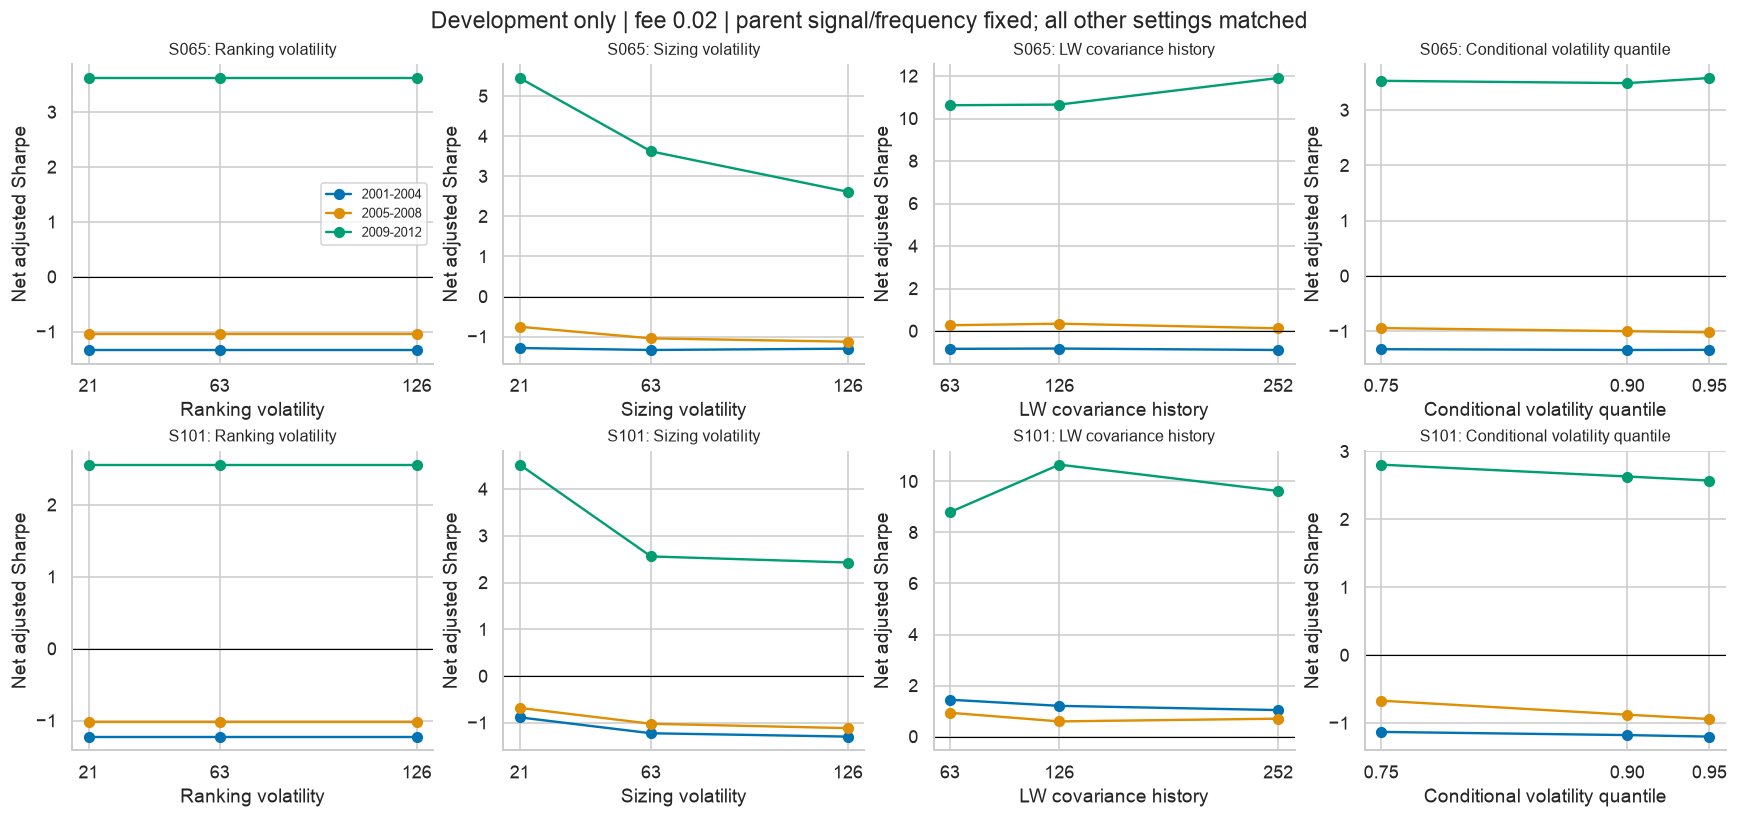

In [10]:
# Compact parameter sensitivity: one variable at a time, separately by block.
def config_name(c):
    return next(n for n,v in configs.items() if v==c)
fig,axes=plt.subplots(2,4,figsize=(15,7),layout='constrained')
for row,parent in enumerate(shortlist):
    c=configs[parent]
    specs=[('Ranking volatility',SET['rank_vol_grid'],lambda v:replace(c,rank_vol=v)),
           ('Sizing volatility',SET['size_vol_grid'],lambda v:replace(c,size_vol=v)),
           ('LW covariance history',SET['covariance_grid'],lambda v:replace(c,weighting='lw',covariance=v)),
           ('Conditional volatility quantile',SET['threshold_grid'],lambda v:replace(c,overlay='conditional',threshold_quantile=v))]
    for ax,(label,values,make) in zip(axes[row],specs):
        for block in BLOCKS:
            ys=[block_scores.query('name==@n and block==@block').adjusted.iloc[0]
                for n in [config_name(make(v)) for v in values]]
            ax.plot(values,ys,marker='o',label=block)
        ax.axhline(0,color='black',lw=.7)
        ax.set_title(f'{parent}: {label}',fontsize=10)
        ax.set_xlabel(label); ax.set_ylabel('Net adjusted Sharpe')
        ax.set_xticks(values)
axes[0,0].legend(fontsize=8)
fig.suptitle('Development only | fee 0.02 | parent signal/frequency fixed; all other settings matched')
fig.savefig(OUT/'03_risk_parameter_sensitivity.png',bbox_inches='tight'); plt.show()

## 9. Freeze finalists before corrected-cost internal-holdout results

The JSON lock below records all permitted internal-holdout evaluations and the development-selected
submission/fallback. The top decision snapshot is produced later; it is not an input to selection.
Development candidate selection is not the same as walk-forward out-of-sample validation.

In [11]:
primary=choose(development,1)[0]
eligible_development=bool(development.loc[primary,'eligible'])
fallback=choose(development.loc[stage1_names],1)[0]
lw_names=[n for n,c in configs.items() if isinstance(c,Config) and c.weighting=='lw' and c.partial<1]
overlay_names=[n for n,c in configs.items() if isinstance(c,Config) and c.overlay!='none']
allocation_final=choose(development.loc[lw_names],1)[0]
overlay_final=choose(development.loc[overlay_names],1)[0]
FINALISTS=list(dict.fromkeys([primary,fallback,allocation_final,overlay_final]))
MAIN=list(dict.fromkeys(['BASE']+FINALISTS))
LOCKED=list(dict.fromkeys(MAIN+shortlist))
lock={'cost':SET['cost'],'development_end':DEV_END,'prior_inspection_disclosed':True,
      'actual_competition_holdout_accessed':False,
      'primary':primary,'fallback':fallback,'submission_is_flat':not eligible_development,
      'finalists':FINALISTS,'locked_holdout_names':LOCKED,
      'configs':{n:config_to_dict(configs[n]) for n in LOCKED},
      'input_sha256':INPUT_HASHES,'selection_rule':'median adjusted; 0.05 near-tie -> block SD -> turnover; positive mean and 2/3 blocks; positive score multipliers'}
lock_text=json.dumps(lock,indent=2,sort_keys=True)
(OUT/'finalists_lock.json').write_text(lock_text)
LOCK_SHA=hashlib.sha256(lock_text.encode()).hexdigest()
print('FROZEN lock SHA256:',LOCK_SHA)
print('Primary:',primary,'| simpler fallback:',fallback,'| diagnostic finalists:',FINALISTS)
display(development.loc[MAIN])
display(pd.DataFrame([dict(name=n,**(asdict(configs[n]) if isinstance(configs[n],Config)
                                   else {'sleeves':str(config_to_dict(configs[n]))})) for n in MAIN]).set_index('name'))
assert 'holdout_results' not in globals()

FROZEN lock SHA256: b22b176975a1df70151704c57f1537c775b9f9fd7474234dc581d770ecbd3d11
Primary: S101:partial0.25 | simpler fallback: S065 | diagnostic finalists: ['S101:partial0.25', 'S065', 'S065:lw_partial0.25', 'S065:conditional_partial']


,stage,median_adjusted,worst_adjusted,block_sd,median_ordinary,positive_blocks,mean_net,turnover,eligible,failure
name,,,,,,,,,,
BASE,1_signal_frequency,2.6868,1.8717,9.2539,-5.3907,0,-0.2179,0.0333,False,fewer than 2 positive blocks; nonpositive pool...
S101:partial0.25,2_one_factor,-0.5501,-1.4715,0.6147,-0.5386,0,-0.0143,0.0045,False,fewer than 2 positive blocks; nonpositive pool...
S065,1_signal_frequency,-1.0421,-1.3321,2.7801,-1.5980,0,-0.0656,0.0120,False,fewer than 2 positive blocks; nonpositive pool...
S065:lw_partial0.25,3_motivated_combinations,-0.7203,-1.7752,0.6277,-0.6873,0,-0.0210,0.0053,False,fewer than 2 positive blocks; nonpositive pool...
S065:conditional_partial,3_motivated_combinations,-1.0763,-1.4068,0.2331,-1.0199,0,-0.0362,0.0075,False,fewer than 2 positive blocks; nonpositive pool...


,signal,lookback,skip,frequency,rank_vol,size_vol,fraction,weighting,covariance,penalty,overlay,risk_window,threshold_history,threshold_quantile,partial,band,warmup
name,,,,,,,,,,,,,,,,,
BASE,xs_risk,126,21,5,63,63,0.3000,simple,126,0.0500,none,63,252,0.9000,1.0000,0.0000,1008
S101:partial0.25,ts,252,0,21,63,63,0.3000,simple,126,0.0500,none,63,252,0.9000,0.2500,0.0000,1008
S065,xs_return,252,0,21,63,63,0.3000,simple,126,0.0500,none,63,252,0.9000,1.0000,0.0000,1008
S065:lw_partial0.25,xs_return,252,0,21,63,63,0.3000,lw,126,0.0500,none,63,252,0.9000,0.2500,0.0000,1008
S065:conditional_partial,xs_return,252,0,21,63,63,0.3000,simple,126,0.0500,conditional,63,252,0.9000,0.5000,0.0000,1008


## 10. Locked internal holdout: 2013-2016

Only locked configurations are run below. There is no holdout grid search or re-selection. Positions
carry across block boundaries; no synthetic reset, extra entry fee or liquidation is inserted.
The P&L accounting always starts from a zero position at the beginning of the full history.

adjusted  net_sharpe  \
name                     period                                     
BASE                     2001-2004             1.8717     -5.0854   
                         2005-2008             2.6868     -5.3907   
                         2009-2012            18.2919     -5.7125   
                         2013-2016 INTERNAL   27.2838     -5.3530   
S101:partial0.25         2001-2004            -0.3060     -0.3018   
                         2005-2008            -0.5501     -0.5386   
                         2009-2012            -1.4715     -1.5578   
                         2013-2016 INTERNAL   -1.2274     -1.2771   
S065                     2001-2004            -1.3321     -1.4909   
                         2005-2008            -1.0421     -1.5980   
                         2009-2012             3.6215     -2.7623   
                         2013-2016 INTERNAL    3.9372     -2.3880   
S065:lw_partial0.25      2001-2004            -0.6582     -0.6522   
                         2005-2008            -0.7203     -0.6873   
                         2009-2012            -1.7752     -2.0052   
                         2013-2016 INTERNAL   -1.4464     -1.7984   
S065:conditional_partial 2001-2004            -0.9569     -0.9326   
                         2005-2008            -1.0763     -1.0199   
                         2009-2012            -1.4068     -2.3085   
                         2013-2016 INTERNAL   -1.1335     -1.9459   

                                             gross_sharpe  mean_net    skew  \
name                     period                                               
BASE                     2001-2004                 0.1439   -0.1880 -1.1481   
                         2005-2008                -0.2139   -0.2156 -1.3590   
                         2009-2012                -0.6619   -0.2501 -1.7144   
                         2013-2016 INTERNAL        0.9569   -0.2703 -2.0971   
S101:partial0.25         2001-2004                 0.8748   -0.0053 -0.3482   
                         2005-2008                 0.6838   -0.0096 -0.4110   
                         2009-2012                -0.1597   -0.0280 -0.3895   
                         2013-2016 INTERNAL        0.6316   -0.0231 -0.7520   
S065                     2001-2004                 0.7464   -0.0451 -1.3079   
                         2005-2008                 0.6837   -0.0533 -1.9390   
                         2009-2012                -0.4881   -0.0982 -2.4101   
                         2013-2016 INTERNAL        0.5260   -0.0978 -3.3296   
S065:lw_partial0.25      2001-2004                 0.6194   -0.0123 -0.2796   
                         2005-2008                 0.6411   -0.0136 -0.6156   
                         2009-2012                -0.2985   -0.0371 -0.7292   
                         2013-2016 INTERNAL        0.3383   -0.0384 -1.2793   
S065:conditional_partial 2001-2004                 0.7084   -0.0221 -0.4220   
                         2005-2008                 0.6131   -0.0263 -0.8393   
                         2009-2012                -0.4374   -0.0602 -1.0810   
                         2013-2016 INTERNAL        0.4942   -0.0554 -1.7557   

                                             excess  holding_days     fees  \
name                     period                                              
BASE                     2001-2004           2.1726       31.2272 198.6947   
                         2005-2008           2.2459       29.6593 218.3621   
                         2009-2012           4.2909       29.3070 243.0846   
                         2013-2016 INTERNAL  6.6736       32.0142 302.9836   
S101:partial0.25         2001-2004           0.9449      231.7606  20.5261   
                         2005-2008           1.2855      235.6849  21.5619   
                         2009-2012           1.5485      202.3016  26.3741   
                         2013-2016 INTERNAL  2.9281      198.1594  33.9582   
S065   

Locked shortlist only (not a holdout parameter sweep):


,adjusted,net_sharpe,mean_net,fees,net_pnl,break_even_cost
BASE,27.2838,-5.3530,-0.2703,302.9836,-279.4766,0.0016
S101:partial0.25,-1.2274,-1.2771,-0.0231,33.9582,-23.8676,0.0059
S065,3.9372,-2.3880,-0.0978,113.6389,-101.1349,0.0022
S065:lw_partial0.25,-1.4464,-1.7984,-0.0384,45.6319,-39.6560,0.0026
S065:conditional_partial,-1.1335,-1.9459,-0.0554,68.1059,-57.3054,0.0032
S101,3.3267,-2.0331,-0.0709,92.5337,-73.2871,0.0042


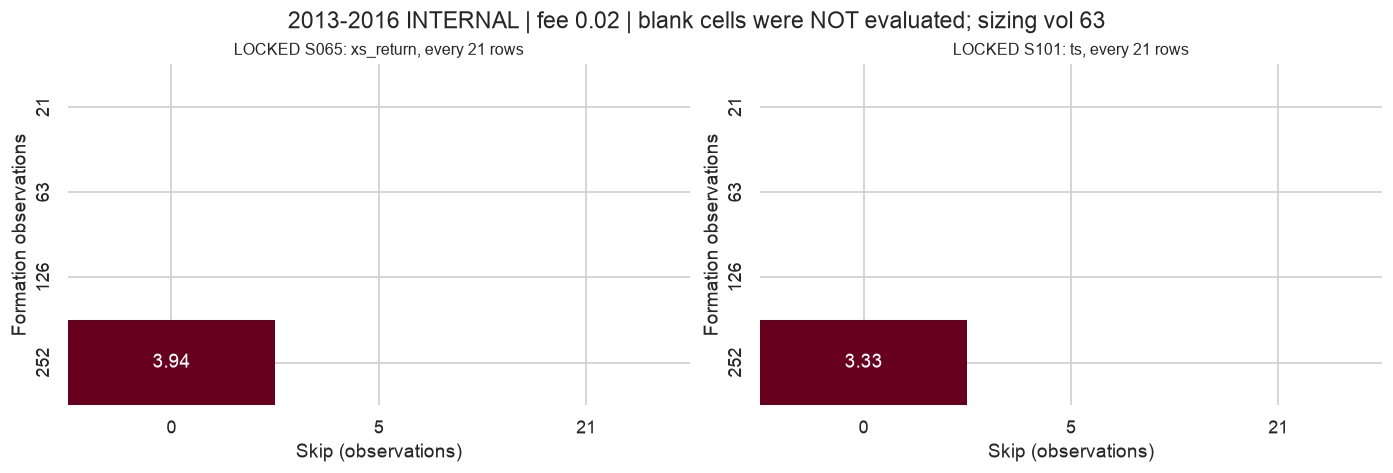

In [12]:
assert hashlib.sha256((OUT/'finalists_lock.json').read_bytes()).hexdigest()==LOCK_SHA
full_engine=MomentumEngine(P)
holdout_results={}
for n in LOCKED:
    c=configs[n]
    holdout_results[n]=(combine(full_engine,c,SET['cost']) if isinstance(c,tuple)
                        else evaluate(full_engine,c,SET['cost']))
HOLD_DATES=P.loc[slice(*SET['internal_holdout'])].index
ALL_DATES=P.loc['2001-01-01':].index
all_periods={**BLOCKS,'2013-2016 INTERNAL':HOLD_DATES}
cards=[]
for n in MAIN:
    for block,dates in all_periods.items():
        cards.append(dict(name=n,period=block,**scorecard(holdout_results[n],dates)))
scorecards=pd.DataFrame(cards).set_index(['name','period'])
display(scorecards[['adjusted','net_sharpe','gross_sharpe','mean_net','skew','excess',
                   'holding_days','fees','max_drawdown','pearson_adjusted','factor']])
scorecards.to_csv(OUT/'finalist_scorecards.csv')
hold_card=pd.DataFrame({n:scorecard(r,HOLD_DATES) for n,r in holdout_results.items()}).T
hold_card.to_csv(OUT/'locked_holdout_results.csv')
print('Locked shortlist only (not a holdout parameter sweep):')
display(hold_card[['adjusted','net_sharpe','mean_net','fees','net_pnl','break_even_cost']])

fig,axes=plt.subplots(1,len(shortlist),figsize=(6*len(shortlist),4),layout='constrained')
for ax,parent in zip(np.atleast_1d(axes),shortlist):
    c=configs[parent]
    # Only the preselected Stage-1 shortlist is admissible in this heatmap.
    f=pd.DataFrame([dict(lookback=configs[n].lookback,skip=configs[n].skip,
                        adjusted=hold_card.loc[n,'adjusted']) for n in shortlist
                    if configs[n].signal==c.signal and configs[n].frequency==c.frequency])
    heat(ax,f,'adjusted',f'LOCKED {parent}: {c.signal}, every {c.frequency} rows')
fig.suptitle('2013-2016 INTERNAL | fee 0.02 | blank cells were NOT evaluated; sizing vol 63')
fig.savefig(OUT/'04_locked_holdout_shortlist.png',bbox_inches='tight'); plt.show()

## 11. Rolling performance: adjusted versus ordinary net Sharpe

Each right-aligned estimate uses exactly 63, 126 or 252 trading observations and requires a full window.
The 63-observation panel is deliberately retained: estimates of skewness and kurtosis from three months
are unstable, and the cubic score adjustment amplifies that noise. Extreme adjusted readings are raw
formula outputs, not capped signals. The companion ordinary panels show when the adjustment drives
an apparent change. The vertical boundary is January 2013; every plot defaults to cost 0.02.

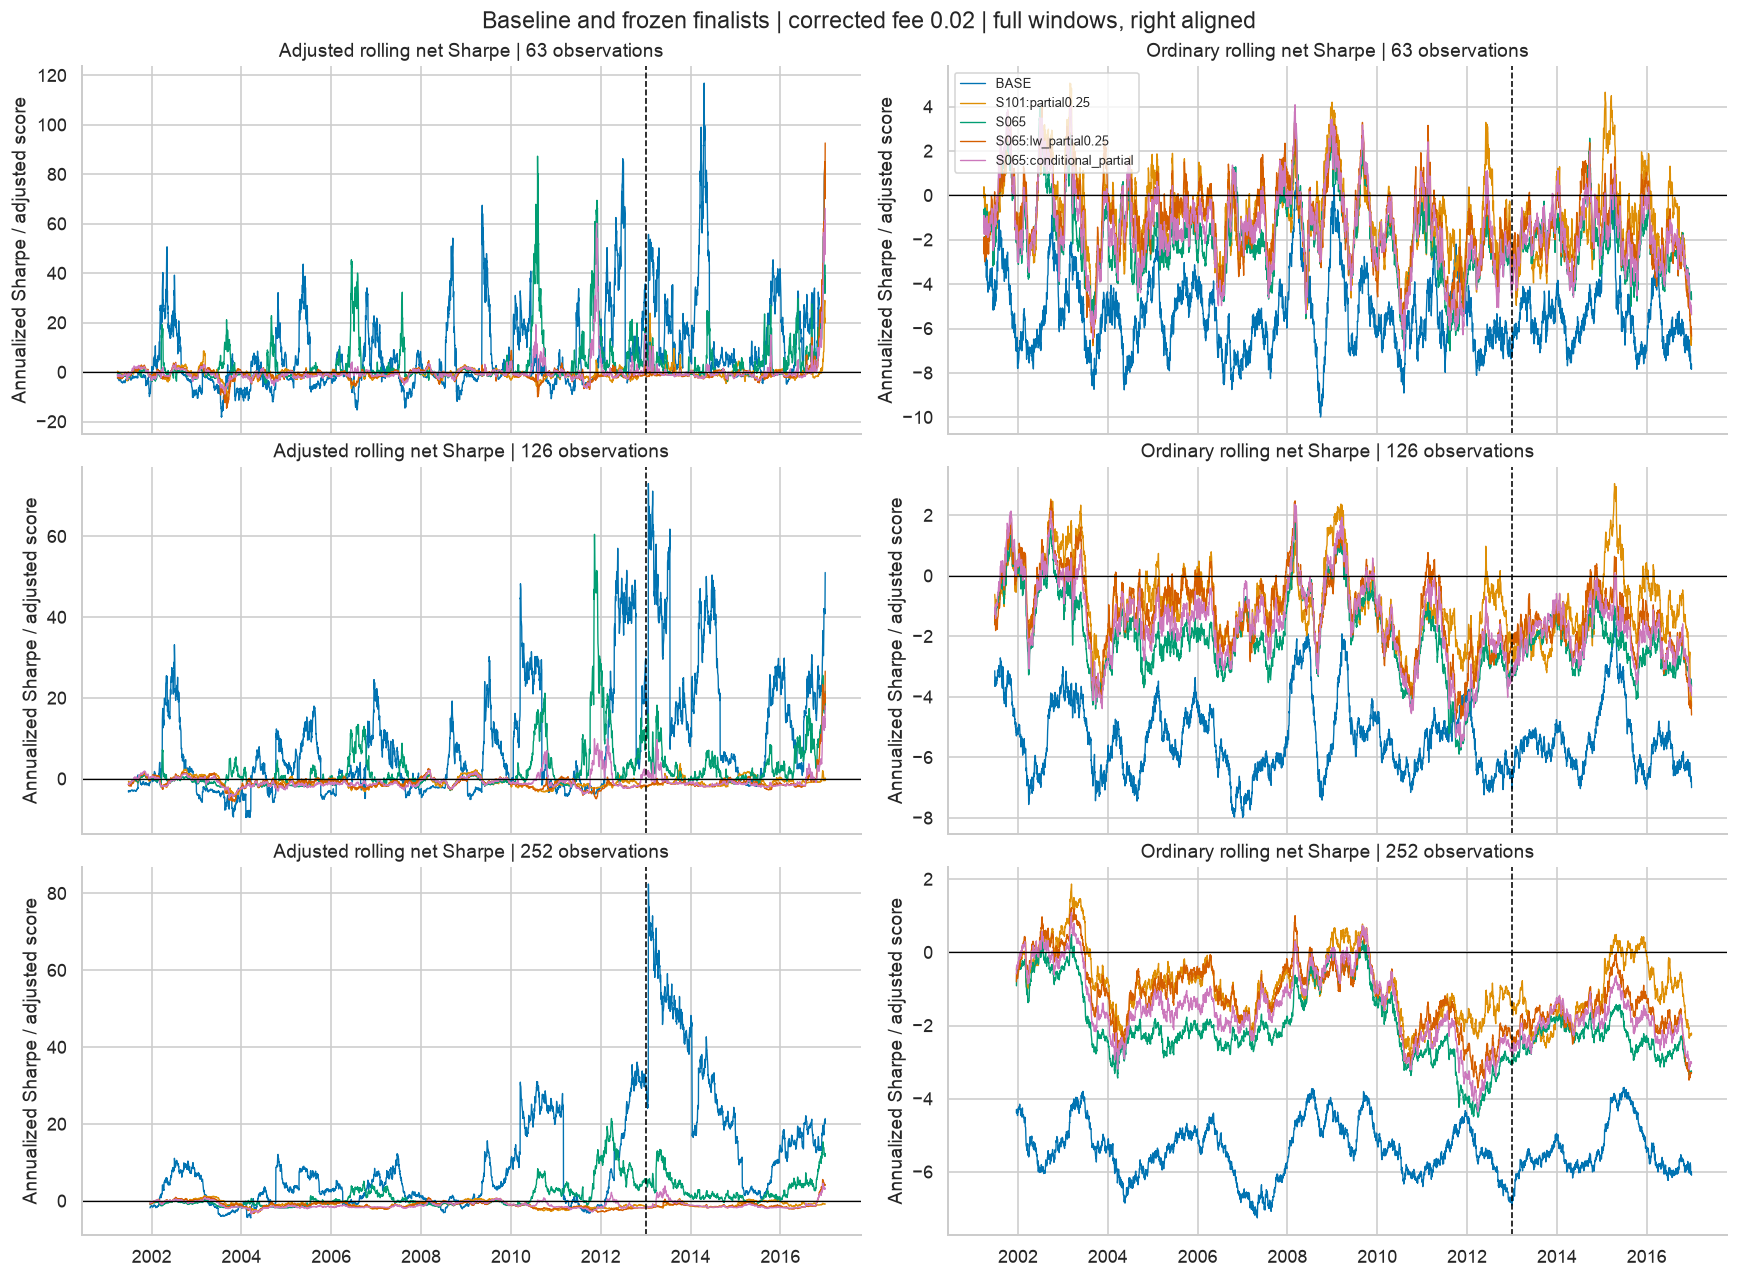

In [13]:
fig,axes=plt.subplots(3,2,figsize=(15,11),sharex=True,layout='constrained')
for row,window in enumerate(SET['rolling_windows']):
    for n in MAIN:
        net=holdout_results[n]['daily'].net.loc[ALL_DATES]
        ordinary=net.rolling(window,min_periods=window).mean()/net.rolling(window,min_periods=window).std(ddof=1)*np.sqrt(252)
        adjusted=net.rolling(window,min_periods=window).apply(lambda v:score(v)['adjusted'],raw=True)
        axes[row,0].plot(net.index,adjusted,lw=.85,label=n)
        axes[row,1].plot(net.index,ordinary,lw=.85,label=n)
    for ax,title in zip(axes[row],['Adjusted','Ordinary']):
        ax.axhline(0,color='black',lw=.8)
        ax.axvline(pd.Timestamp('2013-01-01'),color='black',ls='--',lw=1)
        ax.set_title(f'{title} rolling net Sharpe | {window} observations')
        ax.set_ylabel('Annualized Sharpe / adjusted score')
axes[0,1].legend(fontsize=8,loc='upper left')
fig.suptitle('Baseline and frozen finalists | corrected fee 0.02 | full windows, right aligned')
fig.savefig(OUT/'05_rolling_scores.png',bbox_inches='tight'); plt.show()

## 12. Cumulative P&L, drawdown and fees

Curves are additive P&L in position units, not compounded returns. Drawdown is peak-to-trough P&L,
including a zero initial peak. They share one exposure scale: no full-sample volatility matching is used.

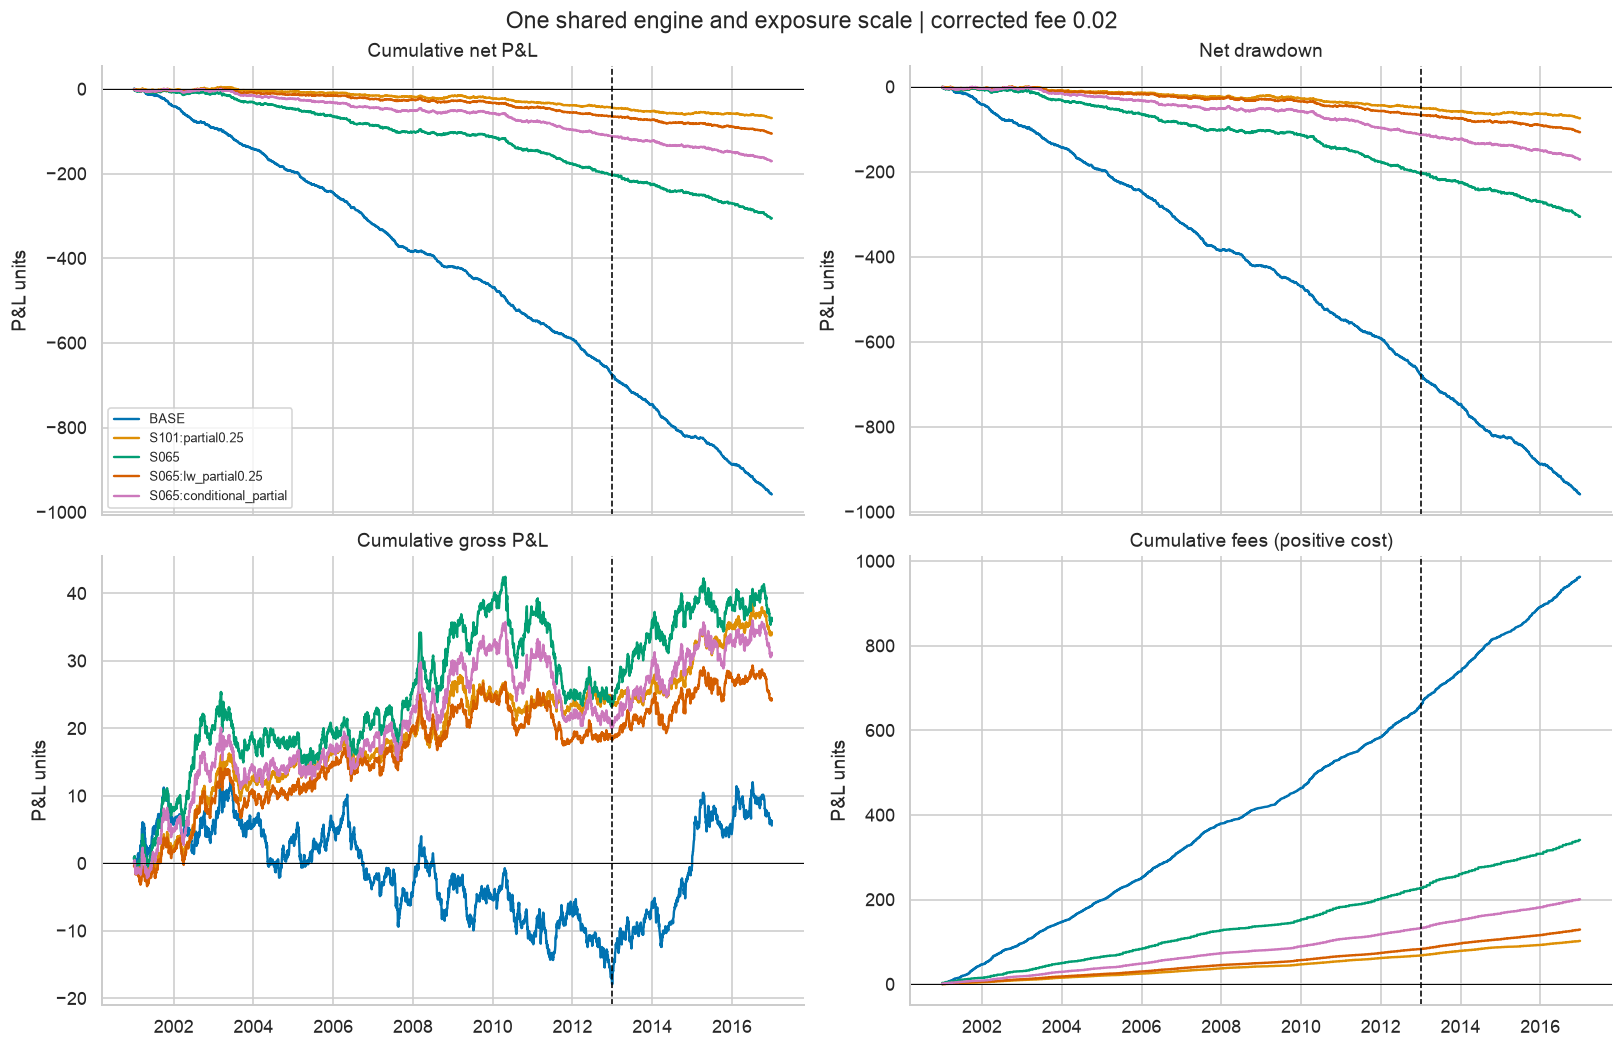

In [14]:
fig,axes=plt.subplots(2,2,figsize=(14,9),sharex=True,layout='constrained')
for n in MAIN:
    d=holdout_results[n]['daily'].loc[ALL_DATES]
    axes[0,0].plot(d.index,d.net.cumsum(),label=n)
    axes[0,1].plot(d.index,drawdown(d.net),label=n)
    axes[1,0].plot(d.index,d.gross.cumsum(),label=n)
    axes[1,1].plot(d.index,d.fees.cumsum(),label=n)
for ax,title in zip(axes.flat,['Cumulative net P&L','Net drawdown','Cumulative gross P&L','Cumulative fees (positive cost)']):
    ax.set_title(title); ax.set_ylabel('P&L units')
    ax.axhline(0,color='black',lw=.6)
    ax.axvline(pd.Timestamp('2013-01-01'),color='black',ls='--',lw=1)
axes[0,0].legend(fontsize=8)
fig.suptitle('One shared engine and exposure scale | corrected fee 0.02')
fig.savefig(OUT/'06_pnl_drawdown_fees.png',bbox_inches='tight'); plt.show()

## 13. Turnover and cost sensitivity, centered on 0.02

Only this section varies the fee: 0, 0.01 and 0.04 supplement the 0.02 default. Positions and the selected
configuration are held fixed, so this measures fee arithmetic, not how a different-cost search would trade.
Break-even fee is total gross P&L / absolute position units traded on the same dates. A negative value
means even a zero fee would not produce positive mean P&L. Holding period uses PDF equation (6)
on lag-aligned held positions and charged trades; its inverse is two-way turnover per observation.

,name,period,cost,adjusted,ordinary,mean,net_pnl
0,BASE,DEVELOPMENT,0.0000,-0.2461,-0.2447,-0.0058,-17.9035
1,BASE,DEVELOPMENT,0.0100,-2.8826,-3.8834,-0.1118,-347.9743
2,BASE,DEVELOPMENT,0.0200,9.2893,-5.3984,-0.2179,-678.0450
3,BASE,DEVELOPMENT,0.0400,40.9192,-6.2068,-0.4300,"-1,338.1864"
4,S101:partial0.25,DEVELOPMENT,0.0000,0.4591,0.4706,0.0077,23.9520
5,S101:partial0.25,DEVELOPMENT,0.0100,-0.1977,-0.1969,-0.0033,-10.2791
6,S101:partial0.25,DEVELOPMENT,0.0200,-0.8179,-0.8039,-0.0143,-44.5102
7,S101:partial0.25,DEVELOPMENT,0.0400,-1.4528,-1.7087,-0.0363,-112.9724
8,S065,DEVELOPMENT,0.0000,0.3145,0.3194,0.0076,23.4982
9,S065,DEVELOPMENT,0.0100,-1.0940,-1.1011,-0.0290,-90.2549


,name,period,holding_days,turnover,fees,gross_pnl,net_pnl,break_even_cost
0,BASE,DEVELOPMENT,30.0015,0.0333,660.1414,-17.9035,-678.0450,-0.0005
1,S101:partial0.25,DEVELOPMENT,221.6479,0.0045,68.4622,23.9520,-44.5102,0.0070
2,S065,DEVELOPMENT,83.2559,0.0120,227.5061,23.4982,-204.0079,0.0021
3,S065:lw_partial0.25,DEVELOPMENT,189.5642,0.0053,83.6492,18.2795,-65.3697,0.0044
4,S065:conditional_partial,DEVELOPMENT,134.1335,0.0075,132.8231,20.1242,-112.6989,0.0030
5,BASE,2013-2016 INTERNAL,32.0142,0.0312,302.9836,23.5069,-279.4766,0.0016
6,S101:partial0.25,2013-2016 INTERNAL,198.1594,0.0050,33.9582,10.0906,-23.8676,0.0059
7,S065,2013-2016 INTERNAL,85.8798,0.0116,113.6389,12.5040,-101.1349,0.0022
8,S065:lw_partial0.25,2013-2016 INTERNAL,171.4856,0.0058,45.6319,5.9758,-39.6560,0.0026
9,S065:conditional_partial,2013-2016 INTERNAL,131.7160,0.0076,68.1059,10.8005,-57.3054,0.0032


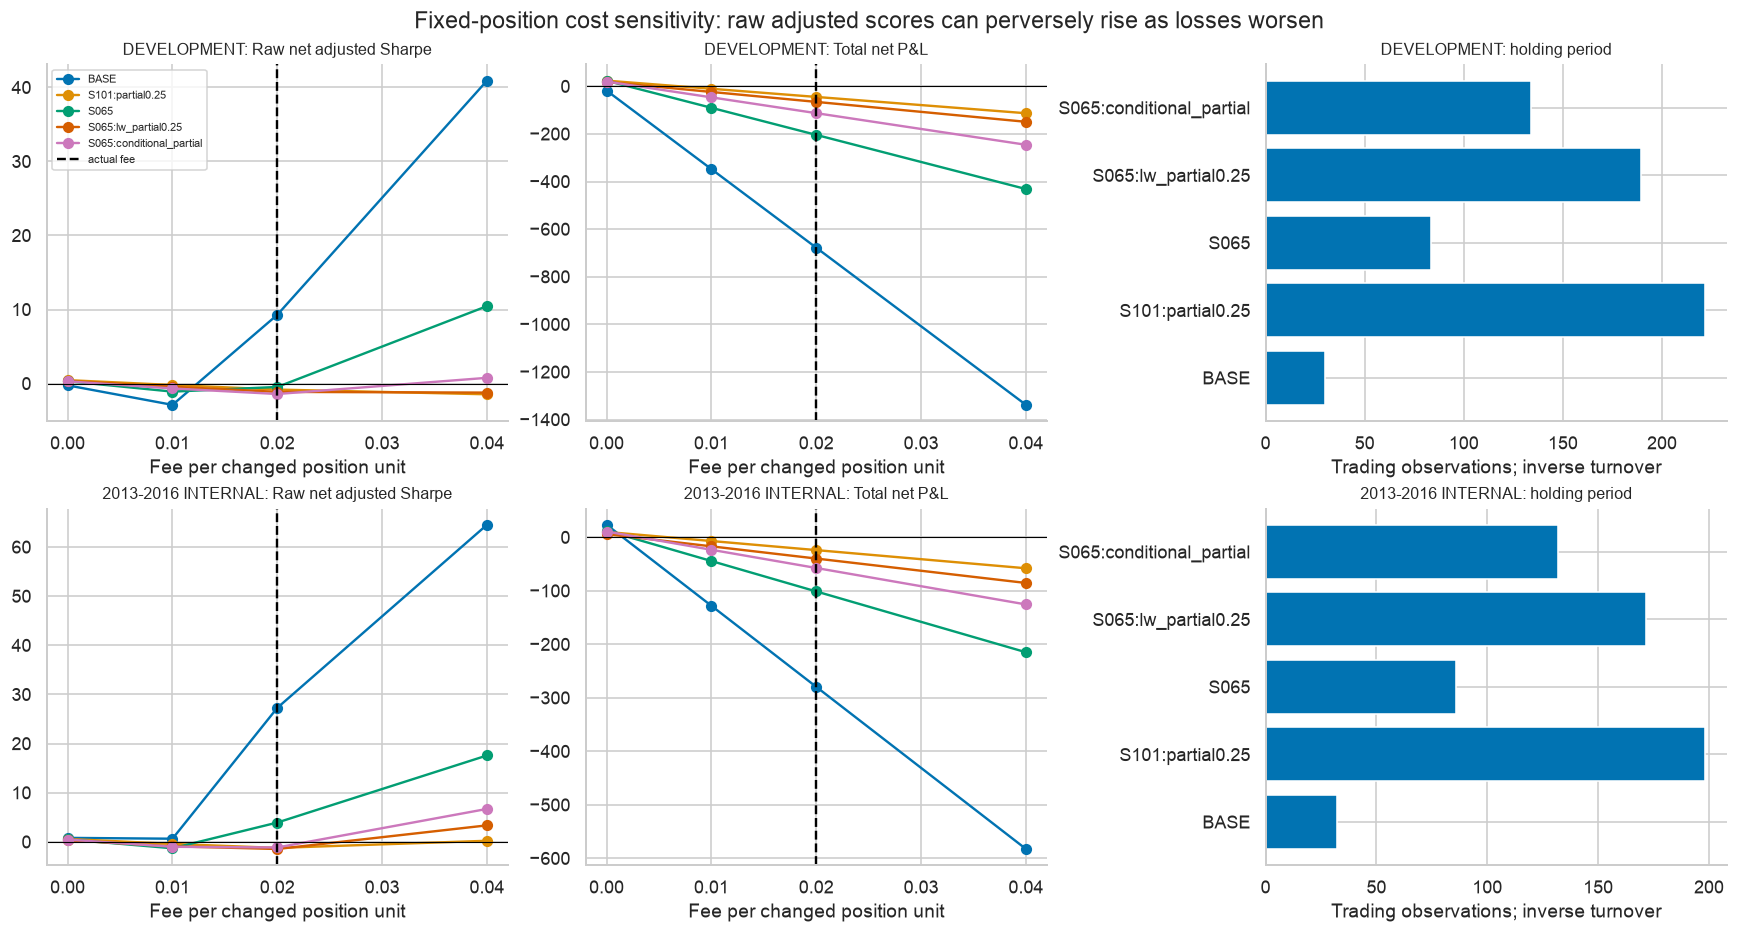

In [15]:
sensitivity=[]
for period,dates in [('DEVELOPMENT',DEV_DATES),('2013-2016 INTERNAL',HOLD_DATES)]:
    for n in MAIN:
        d=holdout_results[n]['daily'].loc[dates]
        for fee in SET['cost_sensitivity']:
            y=d.gross-fee*d.traded_units
            s=score(y)
            sensitivity.append(dict(name=n,period=period,cost=fee,adjusted=s['adjusted'],
                                    ordinary=s['sharpe'],mean=s['mean'],net_pnl=y.sum()))
cost_table=pd.DataFrame(sensitivity)
display(cost_table)
cost_table.to_csv(OUT/'cost_sensitivity.csv',index=False)
turnover_table=pd.DataFrame([dict(name=n,period=period,**scorecard(holdout_results[n],dates))
                             for period,dates in [('DEVELOPMENT',DEV_DATES),('2013-2016 INTERNAL',HOLD_DATES)] for n in MAIN])
display(turnover_table[['name','period','holding_days','turnover','fees','gross_pnl','net_pnl','break_even_cost']])
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for row,period in enumerate(['DEVELOPMENT','2013-2016 INTERNAL']):
    for n in MAIN:
        f=cost_table[(cost_table.name==n)&(cost_table.period==period)]
        axes[row,0].plot(f.cost,f.adjusted,marker='o',label=n)
        axes[row,1].plot(f.cost,f.net_pnl,marker='o',label=n)
    for ax,label in zip(axes[row,:2],['Raw net adjusted Sharpe','Total net P&L']):
        ax.axvline(.02,color='black',ls='--',label='actual fee' if row==0 else None)
        ax.axhline(0,color='black',lw=.7)
        ax.set_title(f'{period}: {label}',fontsize=10); ax.set_xlabel('Fee per changed position unit')
    t=turnover_table[turnover_table.period==period]
    axes[row,2].barh(t.name,t.holding_days)
    axes[row,2].set_title(f'{period}: holding period',fontsize=10)
    axes[row,2].set_xlabel('Trading observations; inverse turnover')
axes[0,0].legend(fontsize=7)
fig.suptitle('Fixed-position cost sensitivity: raw adjusted scores can perversely rise as losses worsen')
fig.savefig(OUT/'07_cost_turnover.png',bbox_inches='tight'); plt.show()

## 14. Executed exposures, leg P&L and portfolio concentration

End-of-close executed positions are `X.shift(1)`; positions earning today's P&L are `X.shift(2)`.
Risk-unit exposures use each day's current trailing ΔP volatility. They drift between rebalances and
after smoothing. The raw 50/50 risk-unit budget is not dollar neutrality. Net notional is the sum of
executed units times the current price; no initial-capital normalization is invented.

Long/short gross P&L is attributed by the sign of the earning position. Fees are allocated to entry
and exit legs separately, so a reversal pays both legs. The table reconciles exactly to portfolio net P&L.
Asset-class exposure shares and HHI use absolute current risk units, not dollar weights.

,name,period,long_gross,short_gross,long_fees,short_fees,long_net,short_net
0,BASE,DEVELOPMENT,2.2608,-20.1644,319.6066,340.5348,-317.3458,-360.6992
1,S101:partial0.25,DEVELOPMENT,28.3992,-4.4472,28.1357,40.3264,0.2635,-44.7737
2,S065,DEVELOPMENT,33.0461,-9.5480,113.2867,114.2194,-80.2406,-123.7673
3,S065:lw_partial0.25,DEVELOPMENT,22.7319,-4.4524,37.7763,45.8729,-15.0444,-50.3253
4,S065:conditional_partial,DEVELOPMENT,30.1197,-9.9955,62.8561,69.9670,-32.7364,-79.9626
5,BASE,2013-2016 INTERNAL,15.7749,7.7320,144.2020,158.7816,-128.4271,-151.0496
6,S101:partial0.25,2013-2016 INTERNAL,5.2249,4.8656,14.4783,19.4799,-9.2533,-14.6143
7,S065,2013-2016 INTERNAL,4.8775,7.6265,55.6318,58.0071,-50.7543,-50.3806
8,S065:lw_partial0.25,2013-2016 INTERNAL,4.0798,1.8960,19.7438,25.8880,-15.6640,-23.9920
9,S065:conditional_partial,2013-2016 INTERNAL,7.3301,3.4705,29.5494,38.5565,-22.2194,-35.0860


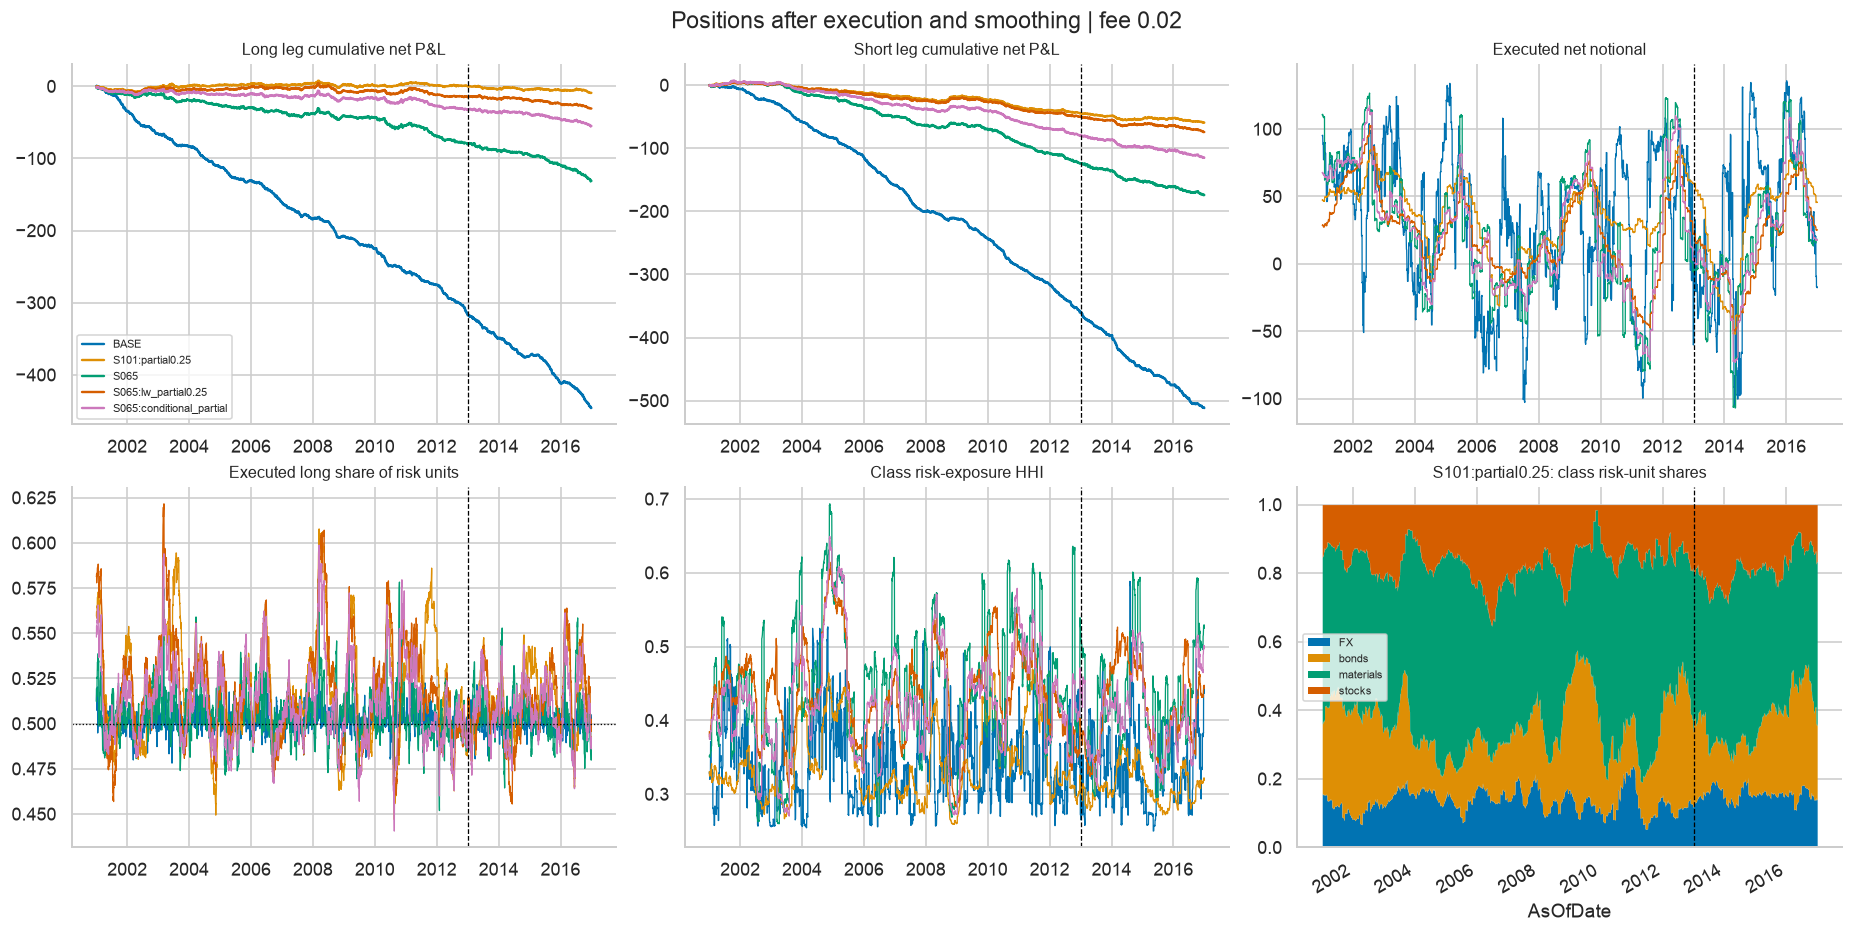

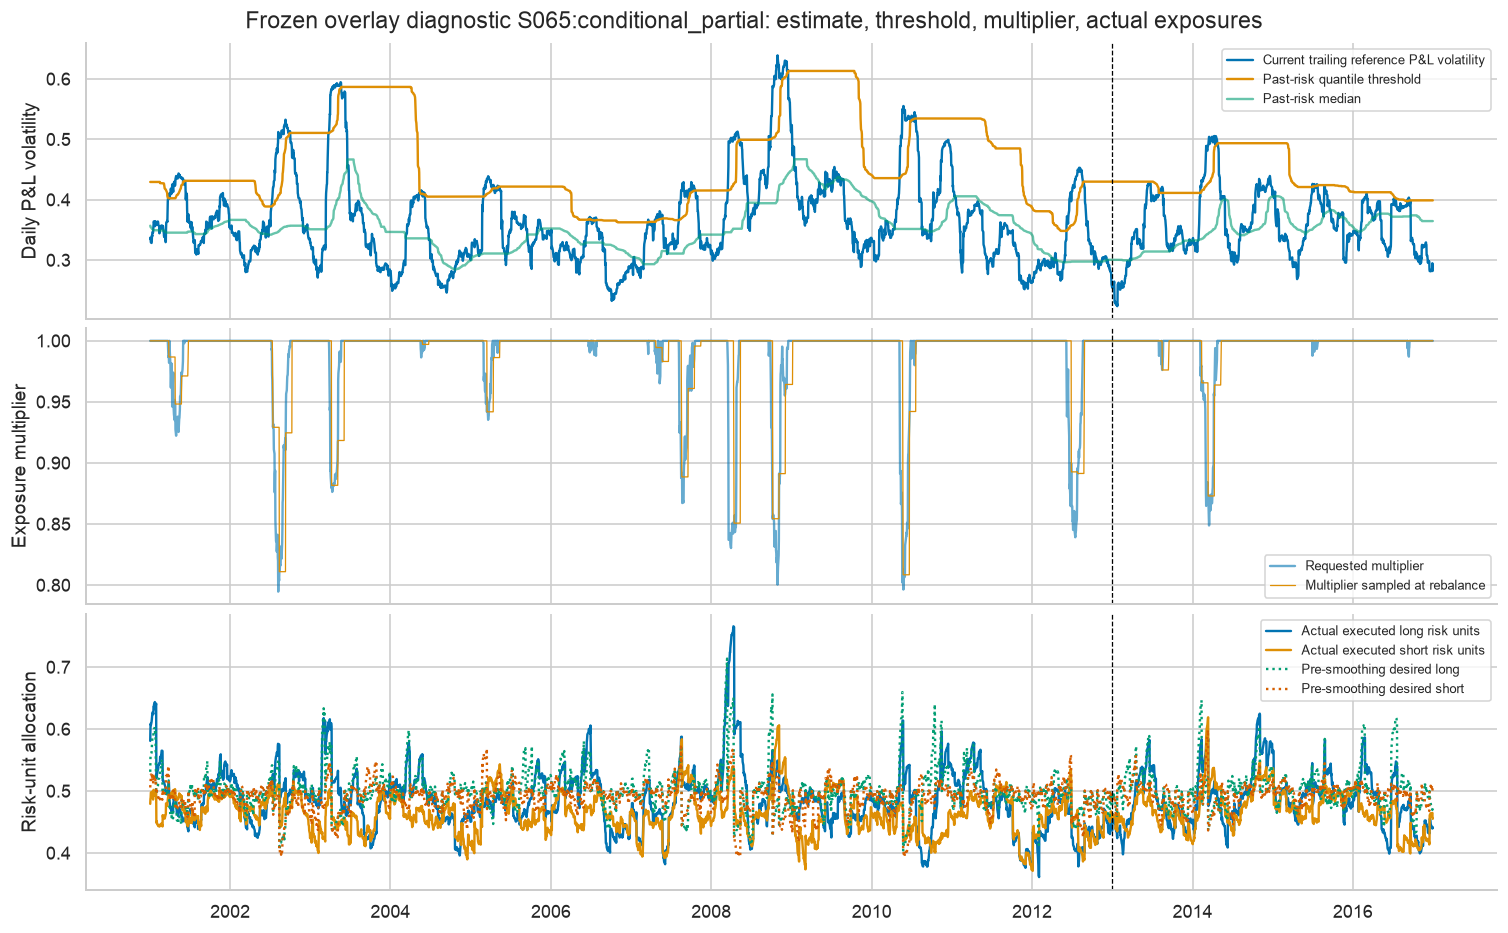

,name,period,long_risk,short_risk,long_share,net_notional,gross_notional,class_HHI
0,BASE,DEVELOPMENT,0.5026,0.4991,0.5017,32.6177,141.9929,0.3434
1,S101:partial0.25,DEVELOPMENT,0.3897,0.3608,0.5188,38.1872,104.7707,0.3415
2,S065,DEVELOPMENT,0.5072,0.4967,0.5050,24.2966,109.0027,0.4452
3,S065:lw_partial0.25,DEVELOPMENT,0.4484,0.4133,0.5190,23.8760,90.6520,0.4366
4,S065:conditional_partial,DEVELOPMENT,0.4862,0.4628,0.5117,24.0914,104.6103,0.4258
5,BASE,2013-2016 INTERNAL,0.5022,0.5001,0.5011,36.2080,164.2552,0.3358
6,S101:partial0.25,2013-2016 INTERNAL,0.3862,0.3634,0.5146,33.1311,124.3198,0.3116
7,S065,2013-2016 INTERNAL,0.5066,0.4969,0.5045,17.1257,119.6056,0.4287
8,S065:lw_partial0.25,2013-2016 INTERNAL,0.4467,0.4256,0.5121,13.4146,103.5805,0.4169
9,S065:conditional_partial,2013-2016 INTERNAL,0.4881,0.4703,0.5089,17.4401,115.9989,0.4055


In [16]:
def leg_pnl(r):
    h=r['held']; gross=r['asset_gross']
    x=r['x']; prev=x.shift(1).fillna(0)
    positive_change=(x.clip(lower=0)-prev.clip(lower=0)).abs().shift(2).fillna(0)
    negative_change=(x.clip(upper=0)-prev.clip(upper=0)).abs().shift(2).fillna(0)
    out=pd.DataFrame({'long_gross':gross.where(h>0,0).sum(axis=1),
                      'short_gross':gross.where(h<0,0).sum(axis=1),
                      'long_fees':SET['cost']*positive_change.sum(axis=1),
                      'short_fees':SET['cost']*negative_change.sum(axis=1)})
    out['long_net']=out.long_gross-out.long_fees
    out['short_net']=out.short_gross-out.short_fees
    np.testing.assert_allclose(out.long_net+out.short_net,r['daily'].net,atol=1e-10)
    return out

def asset_class(name):
    return 'bonds' if name.endswith('_bonds') else ('stocks' if name.endswith('_stocks')
           else ('FX' if name.endswith('_fx') else 'materials'))
classes=pd.Series({n:asset_class(n) for n in P.columns})
legs={n:leg_pnl(holdout_results[n]) for n in MAIN}
display(pd.DataFrame([dict(name=n,period=period,**legs[n].loc[dates].sum().to_dict())
                      for period,dates in [('DEVELOPMENT',DEV_DATES),('2013-2016 INTERNAL',HOLD_DATES)] for n in MAIN]))

def exposures(n):
    c=configs[n]
    window=c.size_vol if isinstance(c,Config) else BASE.size_vol
    vol=pd.DataFrame(full_engine.volatility(window),index=P.index,columns=P.columns)
    executed=holdout_results[n]['x'].shift(1).fillna(0)
    risk_units=executed*vol
    long=risk_units.clip(lower=0).sum(axis=1)
    short=-risk_units.clip(upper=0).sum(axis=1)
    absolute=risk_units.abs()
    shares=absolute.T.groupby(classes).sum().T.div(absolute.sum(axis=1).replace(0,np.nan),axis=0)
    summary=pd.DataFrame({'long_risk':long,'short_risk':short,
                          'long_share':long/(long+short).replace(0,np.nan),
                          'net_notional':(executed*P).sum(axis=1),
                          'gross_notional':(executed*P).abs().sum(axis=1),
                          'class_HHI':shares.pow(2).sum(axis=1)})
    return summary,shares

fig,axes=plt.subplots(2,3,figsize=(16,8),layout='constrained')
for n in MAIN:
    l=legs[n].loc[ALL_DATES]
    axes[0,0].plot(l.index,l.long_net.cumsum(),label=n)
    axes[0,1].plot(l.index,l.short_net.cumsum(),label=n)
    e,_=exposures(n); e=e.loc[ALL_DATES]
    axes[0,2].plot(e.index,e.net_notional,label=n,lw=.8)
    axes[1,0].plot(e.index,e.long_share,label=n,lw=.8)
    axes[1,1].plot(e.index,e.class_HHI,label=n,lw=.8)
_,shares=exposures(primary)
shares.loc[ALL_DATES].plot.area(ax=axes[1,2],stacked=True,linewidth=0,legend=True)
for ax,title in zip(axes.flat,['Long leg cumulative net P&L','Short leg cumulative net P&L',
                             'Executed net notional','Executed long share of risk units',
                             'Class risk-exposure HHI',f'{primary}: class risk-unit shares']):
    ax.set_title(title,fontsize=10)
    ax.axvline(pd.Timestamp('2013-01-01'),color='black',ls='--',lw=.8)
axes[0,0].legend(fontsize=7)
axes[1,0].axhline(.5,color='black',ls=':',lw=.8)
axes[1,2].legend(fontsize=7)
fig.suptitle('Positions after execution and smoothing | fee 0.02')
fig.savefig(OUT/'08_portfolio_diagnostics.png',bbox_inches='tight'); plt.show()

overlay=holdout_results[overlay_final]
dg=overlay['diagnostic'].loc[ALL_DATES]
e,_=exposures(overlay_final)
fig,axes=plt.subplots(3,1,figsize=(13,8),sharex=True,layout='constrained')
axes[0].plot(dg.index,dg.reference_vol,label='Current trailing reference P&L volatility')
axes[0].plot(dg.index,dg.threshold,label='Past-risk quantile threshold')
axes[0].plot(dg.index,dg.reference_target,label='Past-risk median',alpha=.6)
axes[0].legend(fontsize=8); axes[0].set_ylabel('Daily P&L volatility')
axes[1].plot(dg.index,dg.requested_multiplier,label='Requested multiplier',alpha=.6)
axes[1].plot(dg.index,dg.applied_multiplier,label='Multiplier sampled at rebalance',lw=.8)
axes[1].legend(fontsize=8); axes[1].set_ylabel('Exposure multiplier')
axes[2].plot(e.loc[ALL_DATES].index,e.loc[ALL_DATES].long_risk,label='Actual executed long risk units')
axes[2].plot(e.loc[ALL_DATES].index,e.loc[ALL_DATES].short_risk,label='Actual executed short risk units')
raw_target=overlay['target']
cfg=configs[overlay_final]
current_vol=pd.DataFrame(full_engine.volatility(cfg.size_vol),index=P.index,columns=P.columns)
desired_risk=raw_target*current_vol
axes[2].plot(ALL_DATES,desired_risk.clip(lower=0).sum(axis=1).loc[ALL_DATES],ls=':',label='Pre-smoothing desired long')
axes[2].plot(ALL_DATES,-desired_risk.clip(upper=0).sum(axis=1).loc[ALL_DATES],ls=':',label='Pre-smoothing desired short')
axes[2].legend(fontsize=8); axes[2].set_ylabel('Risk-unit allocation')
for ax in axes:
    ax.axvline(pd.Timestamp('2013-01-01'),color='black',ls='--',lw=.8)
fig.suptitle(f'Frozen overlay diagnostic {overlay_final}: estimate, threshold, multiplier, actual exposures')
fig.savefig(OUT/'09_overlay_exposures.png',bbox_inches='tight'); plt.show()
exposure_table=pd.DataFrame([dict(name=n,period=period,**exposures(n)[0].loc[dates].mean().to_dict())
                            for period,dates in [('DEVELOPMENT',DEV_DATES),('2013-2016 INTERNAL',HOLD_DATES)] for n in MAIN])
display(exposure_table)
exposure_table.to_csv(OUT/'executed_exposures.csv',index=False)

## 15. Paired uncertainty in score differences

The moving-block bootstrap resamples the same sequence of overlapping 20-observation blocks for
each strategy in a pair, preserving within-block serial dependence and pairing. Each bootstrap computes
both nonlinear adjusted scores afresh. Percentile intervals are descriptive after this search; they do
not correct for selection, structural change, multiple testing or the earlier inspection of the internal
period. Blocks of 10 and 40 observations check sensitivity for primary minus fallback. No position fitting
or parameter selection is rerun inside the bootstrap. The primary comparison is 2013-2016; pooled
development is shown separately and is inherently selected.

,period,pair,block,score_difference,low,high,fraction_above_zero,ordinary_difference,ordinary_low,ordinary_high,valid
0,DEVELOPMENT,S101:partial0.25 minus BASE,20,-10.1072,-16.6125,-3.3962,0.0000,4.5945,4.0962,5.0717,1500
1,DEVELOPMENT,S065 minus BASE,20,-9.7516,-16.1997,-3.5257,0.0000,3.4215,2.9913,3.8803,1500
2,DEVELOPMENT,S065:lw_partial0.25 minus BASE,20,-10.4165,-17.1624,-4.1188,0.0000,4.2979,3.7898,4.8258,1500
3,DEVELOPMENT,S065:conditional_partial minus BASE,20,-10.7030,-17.4590,-4.3081,0.0000,3.9637,3.4906,4.4660,1500
4,DEVELOPMENT,S101:partial0.25 minus S065,10,-0.3556,-2.1470,0.7408,0.3173,1.1730,0.8300,1.4878,1500
5,DEVELOPMENT,S101:partial0.25 minus S065,20,-0.3556,-2.1060,0.7786,0.3633,1.1730,0.8582,1.4672,1500
6,DEVELOPMENT,S101:partial0.25 minus S065,40,-0.3556,-2.2250,0.8553,0.3787,1.1730,0.8281,1.4749,1500
7,DEVELOPMENT,S101:partial0.25 minus S065:lw_partial0.25,20,0.3093,0.0092,0.5759,0.9807,0.2966,0.0058,0.5619,1500
8,DEVELOPMENT,S101:partial0.25 minus S065:conditional_partial,20,0.5958,0.2984,0.8461,0.9987,0.6309,0.3626,0.8906,1500
9,2013-2016 INTERNAL,S101:partial0.25 minus BASE,20,-28.5112,-47.2514,-9.8744,0.0000,4.0759,3.4437,4.8652,1500


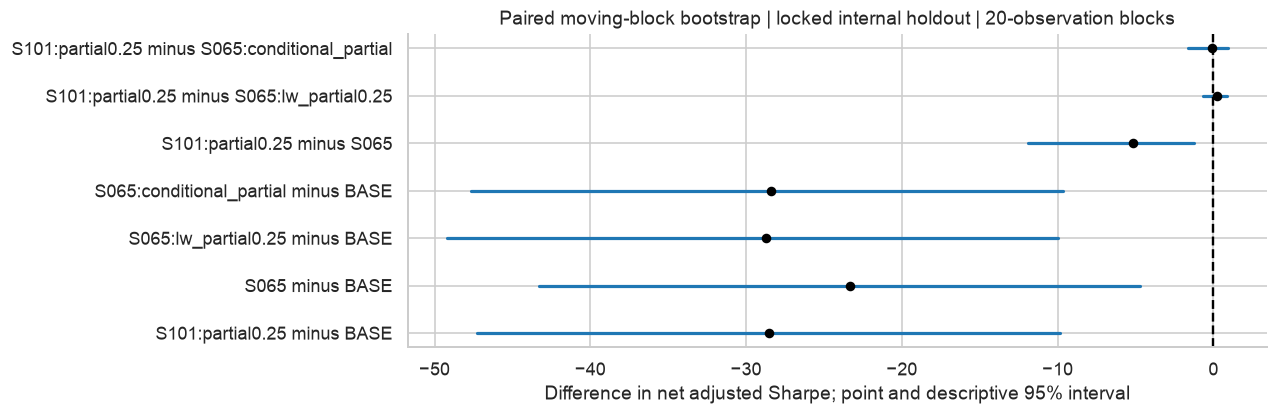

In [17]:
rng=np.random.default_rng(SET['seed'])
def paired_bootstrap(a,b,block_length,repetitions):
    a,b=np.asarray(a),np.asarray(b)
    n=len(a); draws=[]; ordinary=[]
    for _ in range(repetitions):
        starts=rng.integers(0,n-block_length+1,size=int(np.ceil(n/block_length)))
        ids=(starts[:,None]+np.arange(block_length)[None,:]).ravel()[:n]
        sa,sb=score(a[ids]),score(b[ids])
        draws.append(sa['adjusted']-sb['adjusted'])
        ordinary.append(sa['sharpe']-sb['sharpe'])
    draws=np.asarray(draws); ordinary=np.asarray(ordinary)
    return dict(score_difference=score(a)['adjusted']-score(b)['adjusted'],
                low=np.nanquantile(draws,.025),high=np.nanquantile(draws,.975),
                fraction_above_zero=np.nanmean(draws>0),
                ordinary_difference=score(a)['sharpe']-score(b)['sharpe'],
                ordinary_low=np.nanquantile(ordinary,.025),ordinary_high=np.nanquantile(ordinary,.975),
                valid=int(np.isfinite(draws).sum()))
pairs=list(dict.fromkeys([(n,'BASE') for n in FINALISTS if n!='BASE']+
                         [(primary,n) for n in FINALISTS if n!=primary]))
boot=[]
for period,dates in [('DEVELOPMENT',DEV_DATES),('2013-2016 INTERNAL',HOLD_DATES)]:
    for a,b in pairs:
        blocks=SET['bootstrap_blocks'] if (a,b)==(primary,fallback) else [20]
        for length in blocks:
            boot.append(dict(period=period,pair=f'{a} minus {b}',block=length,
                             **paired_bootstrap(holdout_results[a]['daily'].net.loc[dates],
                                                holdout_results[b]['daily'].net.loc[dates],
                                                length,SET['bootstrap_repetitions'])))
bootstrap=pd.DataFrame(boot)
display(bootstrap)
bootstrap.to_csv(OUT/'paired_bootstrap.csv',index=False)
f=bootstrap[(bootstrap.period=='2013-2016 INTERNAL')&(bootstrap.block==20)]
fig,ax=plt.subplots(figsize=(11,max(3,len(f)*.5)),layout='constrained')
for i,(_,r) in enumerate(f.iterrows()):
    ax.plot([r.low,r.high],[i,i],lw=2,color='tab:blue')
    ax.scatter(r.score_difference,i,color='black',s=25,zorder=3)
ax.set_yticks(range(len(f)),f.pair); ax.axvline(0,color='black',ls='--')
ax.set_xlabel('Difference in net adjusted Sharpe; point and descriptive 95% interval')
ax.set_title('Paired moving-block bootstrap | locked internal holdout | 20-observation blocks')
fig.savefig(OUT/'10_paired_uncertainty.png',bbox_inches='tight'); plt.show()

## 16. Where does the apparent edge come from?

These are post-lock descriptive diagnostics, not new selection variants. Asset net contributions
subtract their own actual fees; long/short attribution uses the earlier reconciliation. For each finalist
minus baseline, we show the best contributing asset, year, quarter, and five days. The score after
removing each is a diagnostic deletion, not a feasible reoptimized strategy. With a negative or near-zero
total difference, contribution shares can be unstable or exceed 100%; absolute P&L is also shown.

,name,period,deletion,edge_pnl,adjusted_difference,mean_net,best_asset,best_asset_edge,best_year,best_year_edge,best_quarter,best_quarter_edge,best5_edge,total_edge
0,S101:partial0.25,DEVELOPMENT,all,633.5348,-10.1072,-0.0143,callisto_bonds,51.5083,"2,012.0000",80.2323,2012Q4,23.8953,18.2059,633.5348
1,S101:partial0.25,DEVELOPMENT,drop_best_year,553.3025,-6.9547,-0.0134,callisto_bonds,51.5083,"2,012.0000",80.2323,2012Q4,23.8953,18.2059,633.5348
2,S101:partial0.25,DEVELOPMENT,drop_best_quarter,609.6395,-8.8126,-0.0137,callisto_bonds,51.5083,"2,012.0000",80.2323,2012Q4,23.8953,18.2059,633.5348
3,S101:partial0.25,DEVELOPMENT,drop_best_5_edge_days,615.3289,-5.0573,-0.0145,callisto_bonds,51.5083,"2,012.0000",80.2323,2012Q4,23.8953,18.2059,633.5348
4,S101:partial0.25,DEVELOPMENT,drop_best_asset_contribution,582.0265,-10.1681,-0.0139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,S101:partial0.25,2013-2016 INTERNAL,all,255.6090,-28.5112,-0.0231,ultrapure_silicon,41.7823,"2,014.0000",71.7304,2014Q1,26.8888,22.9543,255.6090
6,S101:partial0.25,2013-2016 INTERNAL,drop_best_year,183.8786,-30.3560,-0.0222,ultrapure_silicon,41.7823,"2,014.0000",71.7304,2014Q1,26.8888,22.9543,255.6090
7,S101:partial0.25,2013-2016 INTERNAL,drop_best_quarter,228.7202,-24.3398,-0.0216,ultrapure_silicon,41.7823,"2,014.0000",71.7304,2014Q1,26.8888,22.9543,255.6090
8,S101:partial0.25,2013-2016 INTERNAL,drop_best_5_edge_days,232.6547,-9.4464,-0.0237,ultrapure_silicon,41.7823,"2,014.0000",71.7304,2014Q1,26.8888,22.9543,255.6090
9,S101:partial0.25,2013-2016 INTERNAL,drop_best_asset_contribution,213.8267,-18.6976,-0.0179,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,name,period,year,net,fees,gross,ordinary
0,S101:partial0.25,DEVELOPMENT,2001,-2.4931,4.7408,2.2476,-0.5388
1,S101:partial0.25,DEVELOPMENT,2002,3.7725,5.1883,8.9608,0.7269
2,S101:partial0.25,DEVELOPMENT,2003,-3.9148,5.3173,1.4025,-0.8150
3,S101:partial0.25,DEVELOPMENT,2004,-2.8540,5.2798,2.4259,-0.8487
4,S101:partial0.25,DEVELOPMENT,2005,-2.9438,4.5282,1.5844,-0.6763
5,S101:partial0.25,DEVELOPMENT,2006,-7.2163,6.4816,-0.7347,-1.8543
6,S101:partial0.25,DEVELOPMENT,2007,-1.8499,5.9259,4.0760,-0.4102
7,S101:partial0.25,DEVELOPMENT,2008,2.0384,4.6262,6.6646,0.3638
8,S101:partial0.25,DEVELOPMENT,2009,-7.2017,5.1997,-2.0020,-1.1868
9,S101:partial0.25,DEVELOPMENT,2010,-7.9576,7.4373,-0.5203,-1.9507


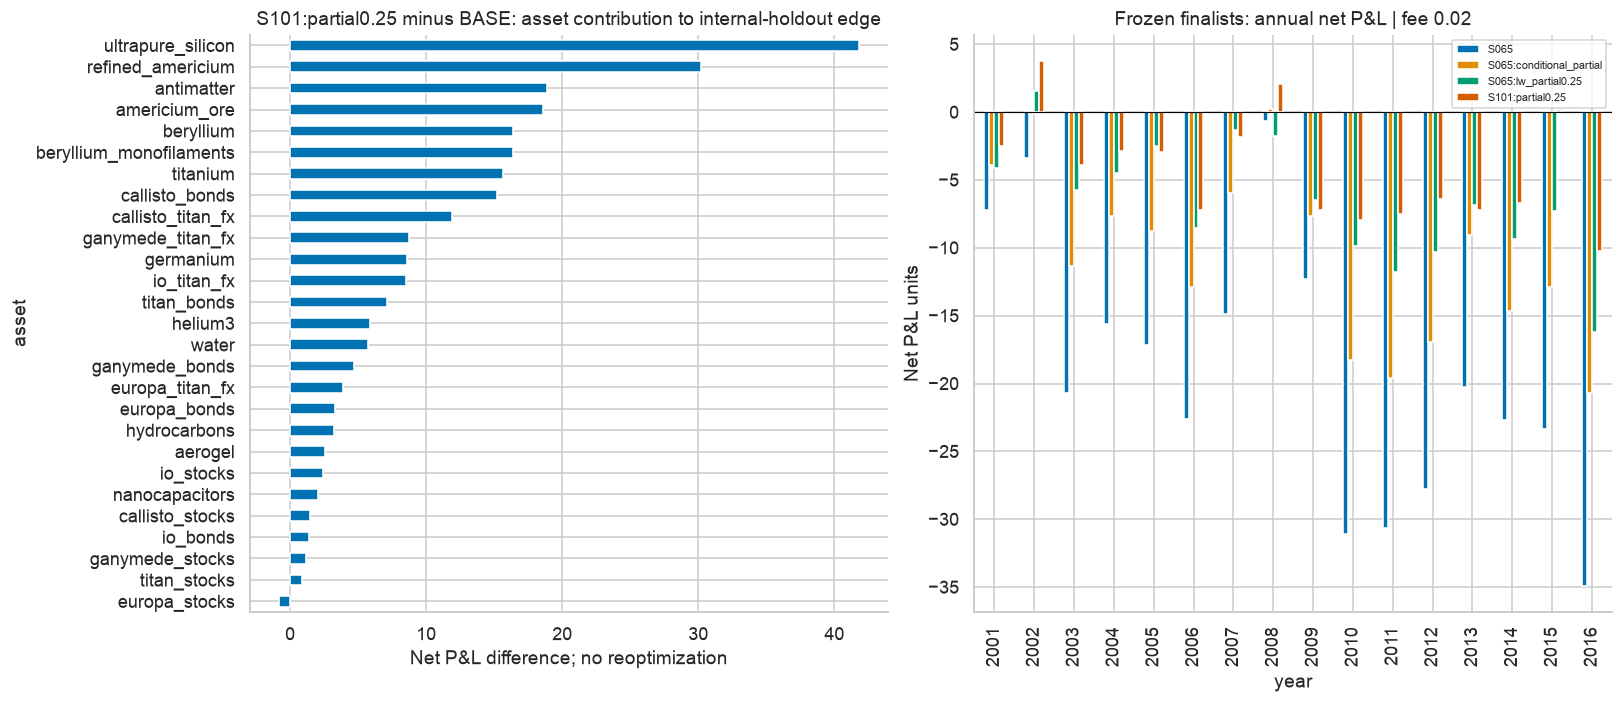

In [18]:
fragility=[]
annual=[]
asset_rows=[]
for n in FINALISTS:
    for period,dates in [('DEVELOPMENT',DEV_DATES),('2013-2016 INTERNAL',HOLD_DATES)]:
        r=holdout_results[n]; base=holdout_results['BASE']
        a=r['asset_net'].loc[dates]; ba=base['asset_net'].loc[dates]
        y=r['daily'].net.loc[dates]; by=base['daily'].net.loc[dates]
        difference=y-by
        asset_diff=(a-ba).sum().sort_values(ascending=False)
        top_asset=asset_diff.index[0]
        years=difference.groupby(difference.index.year).sum()
        quarters=difference.groupby(difference.index.to_period('Q')).sum()
        top_year=years.idxmax(); top_quarter=quarters.idxmax()
        top5=difference.nlargest(5).index
        exclusions={'all':np.ones(len(dates),dtype=bool),
                    'drop_best_year':dates.year!=top_year,
                    'drop_best_quarter':dates.to_period('Q')!=top_quarter,
                    'drop_best_5_edge_days':~dates.isin(top5)}
        for label,keep in exclusions.items():
            fragility.append(dict(name=n,period=period,deletion=label,
                                  edge_pnl=difference.loc[keep].sum(),
                                  adjusted_difference=score(y.loc[keep])['adjusted']-score(by.loc[keep])['adjusted'],
                                  mean_net=y.loc[keep].mean(),
                                  best_asset=top_asset,best_asset_edge=asset_diff.iloc[0],
                                  best_year=int(top_year),best_year_edge=years.max(),
                                  best_quarter=str(top_quarter),best_quarter_edge=quarters.max(),
                                  best5_edge=difference.loc[top5].sum(),total_edge=difference.sum()))
        fragility.append(dict(name=n,period=period,deletion='drop_best_asset_contribution',
                              edge_pnl=(difference-(a[top_asset]-ba[top_asset])).sum(),
                              adjusted_difference=score(y-a[top_asset])['adjusted']-score(by-ba[top_asset])['adjusted'],
                              mean_net=(y-a[top_asset]).mean()))
        for asset in a:
            asset_rows.append(dict(name=n,period=period,asset=asset,net_pnl=a[asset].sum(),
                                   edge_pnl=(a[asset]-ba[asset]).sum()))
        for year,g in r['daily'].loc[dates].groupby(dates.year):
            annual.append(dict(name=n,period=period,year=year,net=g.net.sum(),fees=g.fees.sum(),
                               gross=g.gross.sum(),ordinary=score(g.net)['sharpe']))
fragility=pd.DataFrame(fragility)
annual=pd.DataFrame(annual)
asset_contributions=pd.DataFrame(asset_rows)
display(fragility)
display(annual)
fragility.to_csv(OUT/'edge_fragility.csv',index=False)
annual.to_csv(OUT/'annual_pnl.csv',index=False)
asset_contributions.to_csv(OUT/'asset_contributions.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,6),layout='constrained')
f=asset_contributions[(asset_contributions.name==primary)&(asset_contributions.period=='2013-2016 INTERNAL')]
f.sort_values('edge_pnl').plot.barh(x='asset',y='edge_pnl',ax=axes[0],legend=False)
axes[0].set_title(f'{primary} minus BASE: asset contribution to internal-holdout edge')
axes[0].set_xlabel('Net P&L difference; no reoptimization')
a=annual.pivot_table(index='year',columns='name',values='net')
a.plot.bar(ax=axes[1]); axes[1].axhline(0,color='black',lw=.7)
axes[1].set_title('Frozen finalists: annual net P&L | fee 0.02'); axes[1].set_ylabel('Net P&L units')
axes[1].legend(fontsize=7)
fig.savefig(OUT/'11_edge_concentration.png',bbox_inches='tight'); plt.show()

## 17. No-lookahead, allocation and fee audits

Each baseline/finalist is independently regenerated from the original first row through four cutoffs.
We compare **every position through each cutoff**, not just the last row. This includes covariance
refits, overlay windows, a fixed rebalance phase, and the entire partial-trade state. The same test is
applied to each sleeve if the blend is a finalist. Fee identities use the combined positions. Raw shrinkage
bounds hold at target-formation dates; actual executed and smoothed exposures were reported above.
We also perturb future prices after one cutoff and require earlier desired positions to remain identical.

In [19]:
prefix_audit=[]
for n in MAIN:
    c=configs[n]
    for cutoff in SET['prefix_cutoffs']:
        sub=P.loc[:cutoff]
        e=MomentumEngine(sub)
        regenerated=(combine(e,c,SET['cost'])['x'] if isinstance(c,tuple) else e.positions(c)['x'])
        full=holdout_results[n]['x'].loc[sub.index]
        error=float(np.max(np.abs(full.to_numpy()-regenerated.to_numpy())))
        np.testing.assert_allclose(full,regenerated,rtol=1e-9,atol=1e-9)
        prefix_audit.append(dict(name=n,cutoff=cutoff,rows_compared=len(sub),max_abs_position_error=error))
    r=holdout_results[n]
    x=r['x']; delta=x.diff(); delta.iloc[0]=x.iloc[0]
    expected=SET['cost']*delta.shift(2).fillna(0).abs().sum(axis=1)
    np.testing.assert_allclose(r['daily'].fees,expected,atol=1e-10)
    np.testing.assert_allclose(r['asset_net'].sum(axis=1),r['daily'].net,atol=1e-10)
    assert np.isfinite(x.to_numpy()).all()
    if isinstance(c,Config) and c.weighting=='lw':
        a=r['audit']
        assert len(a)>0
        assert a.minimum_ratio.min()>=0.5-1e-7 and a.maximum_ratio.max()<=1.5+1e-7
        np.testing.assert_allclose(a.long_sum,0.5,atol=1e-7)
        np.testing.assert_allclose(a.short_sum,0.5,atol=1e-7)
        assert a.covariance_min_eigenvalue.min()>-1e-10
        print(n,'LW fits:',len(a),'solver fallbacks:',int((~a.success).sum()),
              'ratio range:',(a.minimum_ratio.min(),a.maximum_ratio.max()))
display(pd.DataFrame(prefix_audit))
pd.DataFrame(prefix_audit).to_csv(OUT/'prefix_invariance_tests.csv',index=False)
cutoff='2012-12-31'
altered=P.copy()
future=altered.index>cutoff
altered.loc[future]=altered.loc[future].to_numpy()*np.linspace(0.7,1.3,future.sum())[:,None]
for n in MAIN:
    e=MomentumEngine(altered); c=configs[n]
    x=(combine(e,c,SET['cost'])['x'] if isinstance(c,tuple) else e.positions(c)['x'])
    np.testing.assert_allclose(x.loc[:cutoff],holdout_results[n]['x'].loc[:cutoff],rtol=1e-9,atol=1e-9)
print('PASS: every prefix, future perturbation, netted fee identity, finite positions and LW target constraints.')

S065:lw_partial0.25 LW fits: 224 solver fallbacks: 0 ratio range: (np.float64(0.5), np.float64(1.5))


,name,cutoff,rows_compared,max_abs_position_error
0,BASE,2004-12-31,2594,0.0000
1,BASE,2008-12-31,3631,0.0000
2,BASE,2012-12-31,4668,0.0000
3,BASE,2015-06-30,5314,0.0000
4,S101:partial0.25,2004-12-31,2594,0.0000
5,S101:partial0.25,2008-12-31,3631,0.0000
6,S101:partial0.25,2012-12-31,4668,0.0000
7,S101:partial0.25,2015-06-30,5314,0.0000
8,S065,2004-12-31,2594,0.0000
9,S065,2008-12-31,3631,0.0000


PASS: every prefix, future perturbation, netted fee identity, finite positions and LW target constraints.


## 18. Adjusted-Sharpe pitfalls and Pearson-kurtosis sensitivity

The organizer's expansion is not globally monotone in ordinary Sharpe. At zero skewness and high
kurtosis, its multiplier can turn negative; a losing strategy can then receive a positive adjusted score.
Large positive ordinary Sharpe can also be penalized into a negative score. We keep these outputs visible
and do not rank a sign-reversed score as investable. Pearson kurtosis adds a fixed term
\(-S^3/8\), so it can also change rankings materially. Neither version rescues negative mean P&L.

In [20]:
moments=[]
for excess in [0,3,20,100]:
    for ordinary in [-8,-4,-1,1,4,8]:
        factor=1-ordinary**2*excess/24
        moments.append(dict(ordinary=ordinary,skew=0,excess=excess,
                            adjusted=ordinary*factor,factor=factor))
display(pd.DataFrame(moments).pivot(index='ordinary',columns='excess',values='adjusted'))
misleading=block_scores[(block_scores.mean_net<0)&(block_scores.adjusted>0)]
print('Observed losing development blocks with positive raw adjusted score:',len(misleading))
display(misleading[['name','block','adjusted','net_sharpe','mean_net','excess','factor']])
print('Locked holdout convention sensitivity (no re-selection):')
display(hold_card[['adjusted','pearson_adjusted','net_sharpe','mean_net','skew','excess','factor']])
print('Raw adjusted-score Stage-1 winner versus guarded selection:')
print('Raw winner:',development.loc[stage1_names].median_adjusted.idxmax(),'| guarded fallback:',fallback)

excess,0,3,20,100
ordinary,,,,
-8,-8.0000,56.0000,418.6667,"2,125.3333"
-4,-4.0000,4.0000,49.3333,262.6667
-1,-1.0000,-0.8750,-0.1667,3.1667
1,1.0000,0.8750,0.1667,-3.1667
4,4.0000,-4.0000,-49.3333,-262.6667
8,8.0000,-56.0000,-418.6667,"-2,125.3333"


Observed losing development blocks with positive raw adjusted score: 317


,name,block,adjusted,net_sharpe,mean_net,excess,factor
0,S000,2001-2004,139.9224,-24.5810,-0.9663,0.3117,-5.6923
1,S000,2005-2008,113.6801,-22.6799,-0.9729,0.3402,-5.0124
2,S000,2009-2012,55.3005,-23.4659,-1.1309,0.1981,-2.3566
3,S001,2001-2004,8.4578,-6.6430,-0.3964,2.1876,-1.2732
4,S001,2005-2008,10.1501,-6.2618,-0.4138,2.6775,-1.6210
...,...,...,...,...,...,...,...
425,S101:band0.25,2009-2012,2.5404,-2.6537,-0.0835,10.3979,-0.9573
427,S101:frequency10,2005-2008,0.4149,-2.6505,-0.0767,6.6123,-0.1565
428,S101:frequency10,2009-2012,3.2623,-3.1906,-0.0986,6.9494,-1.0225
431,S101:frequency42,2009-2012,2.4262,-1.9901,-0.0635,20.3809,-1.2191


Locked holdout convention sensitivity (no re-selection):


,adjusted,pearson_adjusted,net_sharpe,mean_net,skew,excess,factor
BASE,27.2838,46.4572,-5.3530,-0.2703,-2.0971,6.6736,-5.0969
S101:partial0.25,-1.2274,-0.9670,-1.2771,-0.0231,-0.7520,2.9281,0.9611
S065,3.9372,5.6394,-2.3880,-0.0978,-3.3296,16.7248,-1.6487
S065:lw_partial0.25,-1.4464,-0.7193,-1.7984,-0.0384,-1.2793,4.2978,0.8043
S065:conditional_partial,-1.1335,-0.2124,-1.9459,-0.0554,-1.7557,6.2554,0.5825
S101,3.3267,4.3772,-2.0331,-0.0709,-4.0086,23.1929,-1.6363


Raw adjusted-score Stage-1 winner versus guarded selection:
Raw winner: S078 | guarded fallback: S065


## 19. Decision, exact settings and reusable daily targets

The recommendation below follows the frozen development decision. The internal period is used to
describe its limitations, never to replace it with a better-looking holdout strategy. A positive result in
this selected synthetic sample does not establish live profitability. Capital, margin, borrowing costs,
market impact and fill uncertainty are not specified; the only charged friction is the requested unit fee.

In [21]:
def short_config(c):
    if isinstance(c,tuple):
        return 'Equal sleeves: '+'; '.join(short_config(s) for s in c)
    return (f'{c.signal}, formation {c.lookback}, skip {c.skip}, rebalance every {c.frequency} observations; '
            f'ranking vol {c.rank_vol}, sizing vol {c.size_vol}, fraction {c.fraction}; '
            f'{c.weighting} weights, covariance {c.covariance}, penalty {c.penalty}; '
            f'overlay {c.overlay}, risk window {c.risk_window}, threshold history {c.threshold_history}, '
            f'quantile {c.threshold_quantile}; partial {c.partial}, band {c.band}, warm-up {c.warmup}.')

primary_hold=hold_card.loc[primary]
fallback_hold=hold_card.loc[fallback]
submission_name=primary if eligible_development else 'FLAT'
short_rows=[]
for n in MAIN:
    short_rows.append(dict(strategy=n,dev_median_adjusted=development.loc[n,'median_adjusted'],
                           dev_eligible=bool(development.loc[n,'eligible']),
                           internal_adjusted=hold_card.loc[n,'adjusted'],
                           internal_net_sharpe=hold_card.loc[n,'net_sharpe'],
                           internal_mean_net=hold_card.loc[n,'mean_net'],
                           internal_net_pnl=hold_card.loc[n,'net_pnl'],
                           internal_fees=hold_card.loc[n,'fees']))
short_results=pd.DataFrame(short_rows).set_index('strategy')
display(short_results)
short_results.to_csv(OUT/'short_results.csv')

if eligible_development:
    verdict=f'Submit **{primary}**, the frozen development choice; use **{fallback}** as the simpler fallback.'
else:
    verdict=(f'**Do not claim a profitable momentum strategy at cost 0.02. Submit a flat book if permitted.** '
             f'No configuration passed the development rule. If a nonzero hackathon submission is required, '
             f'**{primary}** is the frozen exploratory trading choice; **{fallback}** is the simpler fallback. '
             f'Both are research candidates and may lose money.')
dev_card=scorecard(holdout_results[primary],DEV_DATES)
recommendation=f"""### Executed recommendation

{verdict}

The primary trading candidate has development median adjusted Sharpe **{development.loc[primary,'median_adjusted']:.3f}**,
with **{int(development.loc[primary,'positive_blocks'])}/3** positive blocks and pooled development
mean net P&L **{dev_card['mean_net']:.5f}** per observation. On the locked internal 2013-2016 period,
its raw adjusted Sharpe is **{primary_hold.adjusted:.3f}**, ordinary net Sharpe **{primary_hold.net_sharpe:.3f}**,
mean daily net P&L **{primary_hold.mean_net:.5f}**, total net P&L **{primary_hold.net_pnl:.2f}**,
and fees **{primary_hold.fees:.2f}**. Its break-even unit fee is **{primary_hold.break_even_cost:.5f}**.
The simpler fallback's internal adjusted Sharpe is **{fallback_hold.adjusted:.3f}** and net P&L **{fallback_hold.net_pnl:.2f}**.

**Primary trading settings:** {short_config(configs[primary])}

**Fallback settings:** {short_config(configs[fallback])}

All defaults use Close, the actual observation calendar, a 0.02 fee per absolute unit change,
two-row lag for P&L and fees, sample volatility, bias-corrected skewness and excess kurtosis.
The full configuration JSON supplies inactive settings too. Flat means X=0 for all dates and assets;
its P&L and fees are zero and its Sharpe is undefined.

The corrected fee makes turnover economically decisive. Scaling all positions down scales P&L and
fees together and does not repair a negative mean or improve Sharpe. Reduced trading can lower fees
but also delays signal response. The raw adjusted score must be read alongside ordinary Sharpe,
mean P&L, fees and its multiplier; a higher adjusted score under higher costs is not evidence of profit.
The bootstrap intervals are descriptive following a {len(configs)}-configuration development study.
The 2013-2016 internal period was previously inspected under the old fee; the actual competition
holdout remains untouched.
"""
display(Markdown(recommendation))
(OUT/'recommendation.md').write_text(recommendation)

# Write a concise executable configuration; the lock remains unchanged.
export={'submission_name':submission_name,'primary_trading_candidate':primary,'fallback':fallback,
        'submission_is_flat':not eligible_development,
        'submission_config':config_to_dict(configs[primary]),
        'fallback_config':config_to_dict(configs[fallback]),'settings':SET,
        'moment_convention':{'std_ddof':1,'skew_bias':False,'kurtosis_bias':False,'fisher':True},
        'versions':VERSIONS,'input_sha256':INPUT_HASHES,'finalists_lock_sha256':LOCK_SHA}
(OUT/'strategy_config.json').write_text(json.dumps(export,indent=2,sort_keys=True))
positions=generate_daily_targets(PRICE_FILE,configs[primary])
np.testing.assert_allclose(positions,holdout_results[primary]['x'],atol=1e-10)
if not eligible_development:
    positions=positions*0
positions.to_csv(OUT/'daily_target_positions.csv',index_label='AsOfDate')
generate_daily_targets(PRICE_FILE,configs[fallback],OUT/'fallback_target_positions.csv')
for n in MAIN:
    holdout_results[n]['daily'].to_csv(OUT/f'daily_pnl_{n.replace(":","_")}.csv')
assert hashlib.sha256((OUT/'finalists_lock.json').read_bytes()).hexdigest()==LOCK_SHA
print('All artifacts saved. Frozen selection hash unchanged:',LOCK_SHA)
print('Use generate_daily_targets(new_price_file, Config(...), output_file) with the complete original history plus new rows.')

,dev_median_adjusted,dev_eligible,internal_adjusted,internal_net_sharpe,internal_mean_net,internal_net_pnl,internal_fees
strategy,,,,,,,
BASE,2.6868,False,27.2838,-5.3530,-0.2703,-279.4766,302.9836
S101:partial0.25,-0.5501,False,-1.2274,-1.2771,-0.0231,-23.8676,33.9582
S065,-1.0421,False,3.9372,-2.3880,-0.0978,-101.1349,113.6389
S065:lw_partial0.25,-0.7203,False,-1.4464,-1.7984,-0.0384,-39.6560,45.6319
S065:conditional_partial,-1.0763,False,-1.1335,-1.9459,-0.0554,-57.3054,68.1059


### Executed recommendation

**Do not claim a profitable momentum strategy at cost 0.02. Submit a flat book if permitted.** No configuration passed the development rule. If a nonzero hackathon submission is required, **S101:partial0.25** is the frozen exploratory trading choice; **S065** is the simpler fallback. Both are research candidates and may lose money.

The primary trading candidate has development median adjusted Sharpe **-0.550**,
with **0/3** positive blocks and pooled development
mean net P&L **-0.01430** per observation. On the locked internal 2013-2016 period,
its raw adjusted Sharpe is **-1.227**, ordinary net Sharpe **-1.277**,
mean daily net P&L **-0.02308**, total net P&L **-23.87**,
and fees **33.96**. Its break-even unit fee is **0.00594**.
The simpler fallback's internal adjusted Sharpe is **3.937** and net P&L **-101.13**.

**Primary trading settings:** ts, formation 252, skip 0, rebalance every 21 observations; ranking vol 63, sizing vol 63, fraction 0.3; simple weights, covariance 126, penalty 0.05; overlay none, risk window 63, threshold history 252, quantile 0.9; partial 0.25, band 0.0, warm-up 1008.

**Fallback settings:** xs_return, formation 252, skip 0, rebalance every 21 observations; ranking vol 63, sizing vol 63, fraction 0.3; simple weights, covariance 126, penalty 0.05; overlay none, risk window 63, threshold history 252, quantile 0.9; partial 1.0, band 0.0, warm-up 1008.

All defaults use Close, the actual observation calendar, a 0.02 fee per absolute unit change,
two-row lag for P&L and fees, sample volatility, bias-corrected skewness and excess kurtosis.
The full configuration JSON supplies inactive settings too. Flat means X=0 for all dates and assets;
its P&L and fees are zero and its Sharpe is undefined.

The corrected fee makes turnover economically decisive. Scaling all positions down scales P&L and
fees together and does not repair a negative mean or improve Sharpe. Reduced trading can lower fees
but also delays signal response. The raw adjusted score must be read alongside ordinary Sharpe,
mean P&L, fees and its multiplier; a higher adjusted score under higher costs is not evidence of profit.
The bootstrap intervals are descriptive following a 153-configuration development study.
The 2013-2016 internal period was previously inspected under the old fee; the actual competition
holdout remains untouched.


All artifacts saved. Frozen selection hash unchanged: b22b176975a1df70151704c57f1537c775b9f9fd7474234dc581d770ecbd3d11
Use generate_daily_targets(new_price_file, Config(...), output_file) with the complete original history plus new rows.


### Reading the executed evidence

Costs dominate the primary trading candidate: in 2013-2016 its gross P&L was 10.09, versus fees of
33.96, leaving -23.87 net. Its break-even fee was 0.00594, well below 0.02. Partial rebalancing extended
its holding period to about 198 observations; lower turnover reduced losses but did not establish alpha.
Bounded shrinkage plus partial rebalancing lost 39.66, and the frozen conditional-overlay candidate lost
57.31 in the same internal period. These experiments do not support adding complexity at this fee.

Against the simpler fallback, the primary candidate's ordinary net Sharpe difference was +1.111,
with a paired 20-observation-block descriptive 95% interval [0.464, 1.843]. Its adjusted-score difference
was -5.165, interval [-11.878, -1.252], because the losing fallback receives an artificial positive adjusted
score. Against shrinkage plus partial rebalancing, the adjusted-score difference was +0.219 with interval
[-0.643, 0.851]; against the conditional overlay it was -0.094, interval [-1.623, 0.926]. These selected-sample
intervals do not justify a profitable-strategy claim.

The primary candidate lost 255.61 fewer P&L units than the baseline. The best asset contribution
(ultrapure_silicon) explained 41.78, about 16% of that loss reduction; the best year (2014) explained 71.73,
about 28%; the best quarter explained about 11%, and the five best difference days about 9%.
Removing each still left a positive P&L difference versus baseline, while the candidate itself remained
unprofitable. Thus the apparent edge is largely a broad reduction in turnover losses, not proof of a
profitable asset, leg or timing mechanism. The leg table and annual contribution chart provide the
remaining decomposition. Raw adjusted heatmap peaks should be interpreted together with failure
flags: none of the nearby parameter regions passed the economic selection rule.


### How to explain this at the hackathon

1. Rank price trends on comparable risk scales; buy winners and sell losers.
2. Divide risk-unit allocations by current ΔP volatility to obtain tradable units.
3. Compare simple allocation with bounded covariance shrinkage; reduce costly target chasing only if
   development evidence supports it.
4. Decide at close t, execute next close, and earn the following price change. Charge the corrected fee
   to absolute changed units, including reversals, after netting any sleeves.
5. Choose on chronological development blocks, lock the candidates, then report the internal check,
   tails, turnover, uncertainty and all losses honestly.

`generate_targets.py NEW_PRICE_FILE --config research_output/strategy_config.json --output targets.csv`
replays the original history plus new observations. It writes desired targets by asset name, without
an execution shift. The original first date and column order must be preserved. The organizer's example
output schema is absent, so this export uses `AsOfDate` plus the Close asset identifiers without `|Close`;
adapt that header only if the organizer requires another schema. Do not pass only the new rows:
the rolling fits, rebalance phase and stateful partial-trade path need the available history.

# Extension: slow trend, hysteresis and entry-based sizing

This extension was requested after the original results, including 2013-2016, had been seen.
The new mechanisms were proposed in response to those results. Consequently **2013-2016 is now
reused validation data**; locking new candidates before scoring them does not undo that contamination.
The actual competition holdout remains untouched. The original study and its lock are preserved.

The hypothesis is specific: avoid paying for small signal and volatility fluctuations. Each asset receives
a fixed 1/27 risk allotment when entering, divided by its current daily ΔP volatility. Unused allotments
stay in cash. Entry or exit in one name does not resize other names. This allows an unbalanced long/short
book, so matched controls isolate the change from the original side-balanced time-series strategy.

An asset enters above a strong signal threshold, exits when its signed signal falls below a weaker
threshold, and reverses only on a strong opposite signal. Its units otherwise remain fixed until volatility
leaves a ratio band around the volatility used at its last sizing. There is no daily resizing. Decisions
are reviewed every 21 observations, with one matched 42-observation comparator. The signal is the
price change divided by current trailing ΔP volatility and the square root of formation length.

The cost gate affects new entries/reversals only: fee divided by current daily ΔP volatility must be below
the specified ceiling. Existing positions are allowed to stay, avoiding forced exits when that ratio moves.
Signal agreement requires all 63-, 126- and 252-observation components to have the entry's sign.

In [22]:
"""Cost-conscious trend extension; all inputs are available at the decision close."""
from dataclasses import dataclass, asdict, replace
import numpy as np
import pandas as pd



@dataclass(frozen=True)
class SlowConfig:
    lookbacks: tuple = (252,)
    entry: float = 1.0
    exit: float = 0.25
    frequency: int = 21
    rank_vol: int = 63
    size_vol: int = 63
    resize_band: float = 0.50
    agreement: bool = False
    cost_gate: float = 0.0  # zero disables; maximum fee / daily price-change volatility
    warmup: int = 1008
    total_risk_budget: float = 1.0


def slow_positions(prices, config, cost=0.02):
    """Fixed risk allotment per name: new entries never resize unrelated positions.

    Unused allotments stay in cash. The portfolio is not forced to have a 50/50 side
    split. This intentional change is isolated by the matched N00/N01 controls.
    Entry/exit and volatility resizing are checked on the same fixed row schedule.
    """
    c = config
    assert c.entry >= c.exit >= 0
    vol = prices.diff().rolling(c.size_vol).std(ddof=1).to_numpy()
    rank_vol = prices.diff().rolling(c.rank_vol).std(ddof=1)
    component = np.stack([((prices-prices.shift(L))/(rank_vol*np.sqrt(L))).to_numpy()
                          for L in c.lookbacks])
    signal = np.mean(component, axis=0)
    count, names = prices.shape
    allotment = c.total_risk_budget/names
    current = np.zeros(names)
    anchor_vol = np.zeros(names)
    x = np.zeros((count,names))
    events = []
    anchors = np.zeros_like(x)
    for t in range(count):
        if t >= c.warmup and t % c.frequency == 0:
            for j in range(names):
                sigma, s = vol[t,j], signal[t,j]
                if not np.isfinite(sigma+s) or sigma <= 1e-10:
                    continue
                side = np.sign(current[j])
                desired_side = np.sign(s)
                agreement = (not c.agreement or
                             np.all(np.sign(component[:,t,j]) == desired_side))
                cheap = c.cost_gate <= 0 or cost/sigma <= c.cost_gate
                strong = abs(s) > c.entry and agreement and cheap
                target_side = side
                if side == 0:
                    if strong:
                        target_side = desired_side
                elif strong and desired_side != side:
                    target_side = desired_side
                elif side*s <= c.exit:
                    target_side = 0
                reason = None
                if target_side != side:
                    reason = 'entry' if side == 0 else ('exit' if target_side == 0 else 'reversal')
                    current[j] = target_side*allotment/sigma
                    anchor_vol[j] = sigma if target_side else 0
                elif side != 0:
                    # Symmetric ratio band around the volatility used for last sizing.
                    ratio = sigma/anchor_vol[j]
                    if ratio > 1+c.resize_band or ratio < 1/(1+c.resize_band):
                        reason = 'risk_resize'
                        current[j] = side*allotment/sigma
                        anchor_vol[j] = sigma
                if reason:
                    events.append((prices.index[t],prices.columns[j],reason))
        x[t] = current
        anchors[t] = anchor_vol
    return {'x':pd.DataFrame(x,index=prices.index,columns=prices.columns),
            'anchor_vol':pd.DataFrame(anchors,index=prices.index,columns=prices.columns),
            'signal':pd.DataFrame(signal,index=prices.index,columns=prices.columns),
            'vol':pd.DataFrame(vol,index=prices.index,columns=prices.columns),
            'events':pd.DataFrame(events,columns=['date','asset','reason'])}


def slow_evaluate(prices, config, cost=0.02):
    generated = slow_positions(prices,config,cost)
    return {'config':config, **generated, **backtest(prices,generated['x'],cost)}


def generate_slow_targets(price_file, config, output_file=None, flat=False):
    if isinstance(config,dict):
        config = SlowConfig(**{**config,'lookbacks':tuple(config['lookbacks'])})
    x = slow_positions(read_prices(price_file),config)['x']
    if flat:
        x = x*0
    if output_file:
        x.to_csv(output_file,index_label='AsOfDate')
    return x

## Extension selection rule and matched tests — before new holdout results

Use exactly the original three development blocks and common dates. Reuse the original eligibility
rule, median adjusted-score selection and consistency/turnover near-tie rule. If none qualifies, choose
an exploratory candidate by median ordinary net Sharpe, but retain a flat submission recommendation.

First compare no hysteresis with frequent/rare volatility resizing and then change entry, exit, resize
band, frequency, agreement and cost gates one at a time around N03. Only after this development stage,
test the best two configurations with a specified three-horizon agreement/cost-gate combination. This
is a small staged search, not a Cartesian search. Select a primary, a simpler one-factor fallback and
the canonical N03 diagnostic, then freeze them before the new 2013-2016 evaluation. No target score
of 1 or 2 is used as a selection rule. Every failure remains visible.

In [23]:
SLOW_OUT=Path('research_output/slow_trend'); SLOW_OUT.mkdir(exist_ok=True)
slow_base=SlowConfig()
slow_configs={
 'N00':replace(slow_base,entry=0,exit=0,resize_band=0),
 'N01':replace(slow_base,entry=0,exit=0),
 'N02':replace(slow_base,resize_band=0),
 'N03':slow_base}
for v in SLOWSET['entry_levels']:
    if v!=slow_base.entry: slow_configs[f'entry{v}']=replace(slow_base,entry=v)
for v in SLOWSET['exit_levels']:
    if v!=slow_base.exit: slow_configs[f'exit{v}']=replace(slow_base,exit=v)
for v in SLOWSET['resize_bands']:
    if v!=slow_base.resize_band: slow_configs[f'resize{v}']=replace(slow_base,resize_band=v)
slow_configs['frequency42']=replace(slow_base,frequency=42)
slow_configs['multihorizon']=replace(slow_base,lookbacks=SLOWSET['agreement_lookbacks'])
slow_configs['agreement']=replace(slow_base,lookbacks=SLOWSET['agreement_lookbacks'],agreement=True)
for v in SLOWSET['cost_gates']: slow_configs[f'costgate{v}']=replace(slow_base,cost_gate=v)

def slow_dev_run(c):
    r=slow_evaluate(Pdev,c,SLOWSET['cost'])
    return {'config':c,'daily':r['daily']}
slow_dev=dict(zip(slow_configs,Parallel(n_jobs=SET['n_jobs'],prefer='threads')(
              delayed(slow_dev_run)(c) for c in slow_configs.values())))
def slow_tables():
    blocks=[]; summaries=[]
    for n,r in slow_dev.items():
        b=pd.DataFrame([dict(name=n,period=period,**scorecard(r,dates)) for period,dates in BLOCKS.items()])
        blocks.append(b)
        pooled=scorecard(r,DEV_DATES)
        positive=int(((b.mean_net>0)&(b.net_sharpe>0)&(b.adjusted>0)).sum())
        eligible=bool(pooled['mean_net']>0 and positive>=2 and (b.factor>0).all() and np.isfinite(b.adjusted).all())
        summaries.append(dict(name=n,median_adjusted=b.adjusted.median(),median_ordinary=b.net_sharpe.median(),
                              block_sd=b.adjusted.std(),turnover=pooled['turnover'],mean_net=pooled['mean_net'],
                              positive_blocks=positive,eligible=eligible,
                              failure='' if eligible else 'fails positive mean, consistency or score-multiplier criteria'))
    return pd.concat(blocks,ignore_index=True),pd.DataFrame(summaries).set_index('name')
slow_blocks,slow_selection=slow_tables()
display(slow_selection.sort_values('median_ordinary',ascending=False))
slow_shortlist=choose(slow_selection,2)
slow_stage1=list(slow_configs)
print('Development shortlist:',slow_shortlist)
# Motivated combination only; thresholds inherited from selected development parents.
for parent in slow_shortlist:
    c=replace(slow_configs[parent],lookbacks=SLOWSET['agreement_lookbacks'],agreement=True,cost_gate=2.0)
    if c not in slow_configs.values():
        n=parent+':agreement_gate2'
        slow_configs[n]=c;slow_dev[n]=slow_dev_run(c)
slow_blocks,slow_selection=slow_tables()
slow_primary=choose(slow_selection,1)[0]
slow_fallback=choose(slow_selection.loc[slow_stage1],2)
slow_fallback=next((n for n in slow_fallback if n!=slow_primary),'N03')
slow_main=list(dict.fromkeys([slow_primary,slow_fallback,'N03','N00']))
slow_lock={'primary':slow_primary,'fallback':slow_fallback,'names':slow_main,
           'submission_is_flat':not bool(slow_selection.loc[slow_primary,'eligible']),
           'configurations':{n:asdict(slow_configs[n]) for n in slow_main},
           'cost':0.02,'development_end':'2012-12-31','reused_internal_holdout':True,
           'actual_competition_holdout_accessed':False}
slow_lock_text=json.dumps(slow_lock,indent=2,sort_keys=True)
(SLOW_OUT/'finalists_lock.json').write_text(slow_lock_text)
slow_lock_sha=hashlib.sha256(slow_lock_text.encode()).hexdigest()
slow_blocks.to_csv(SLOW_OUT/'development_block_scores.csv',index=False)
slow_selection.to_csv(SLOW_OUT/'development_selection.csv')
(SLOW_OUT/'configuration_registry.json').write_text(json.dumps({n:asdict(c) for n,c in slow_configs.items()},indent=2))
display(slow_selection)
print('FROZEN before new holdout P&L:',slow_lock_sha,slow_lock)

,median_adjusted,median_ordinary,block_sd,turnover,mean_net,positive_blocks,eligible,failure
name,,,,,,,,
costgate2.0,-0.1557,-0.1553,0.1251,0.0040,-0.0012,1,False,"fails positive mean, consistency or score-mult..."
costgate4.0,-0.2797,-0.2777,0.3508,0.0044,-0.0030,1,False,"fails positive mean, consistency or score-mult..."
entry1.5,-0.3982,-0.3885,0.2346,0.0044,-0.0058,0,False,"fails positive mean, consistency or score-mult..."
frequency42,-0.5312,-0.5150,0.4991,0.0041,-0.0063,1,False,"fails positive mean, consistency or score-mult..."
resize1000000000.0,-0.5755,-0.5767,0.4500,0.0040,-0.0076,1,False,"fails positive mean, consistency or score-mult..."
resize1.0,-0.6244,-0.6212,0.4562,0.0043,-0.0071,1,False,"fails positive mean, consistency or score-mult..."
exit0.0,-0.7471,-0.7306,0.6173,0.0040,-0.0085,1,False,"fails positive mean, consistency or score-mult..."
exit0.5,-0.7538,-0.7539,0.5455,0.0063,-0.0116,0,False,"fails positive mean, consistency or score-mult..."
N03,-0.8078,-0.8172,0.5111,0.0047,-0.0093,1,False,"fails positive mean, consistency or score-mult..."


Development shortlist: ['costgate2.0', 'costgate4.0']


,median_adjusted,median_ordinary,block_sd,turnover,mean_net,positive_blocks,eligible,failure
name,,,,,,,,
N00,-1.0995,-1.3400,0.2235,0.0076,-0.0381,0,False,"fails positive mean, consistency or score-mult..."
N01,-0.9173,-1.0036,0.3771,0.0063,-0.0295,0,False,"fails positive mean, consistency or score-mult..."
N02,-1.0437,-1.1296,0.5061,0.0062,-0.0148,0,False,"fails positive mean, consistency or score-mult..."
N03,-0.8078,-0.8172,0.5111,0.0047,-0.0093,1,False,"fails positive mean, consistency or score-mult..."
entry0.5,-0.9707,-1.0024,0.5755,0.0058,-0.0155,0,False,"fails positive mean, consistency or score-mult..."
entry1.5,-0.3982,-0.3885,0.2346,0.0044,-0.0058,0,False,"fails positive mean, consistency or score-mult..."
exit0.0,-0.7471,-0.7306,0.6173,0.0040,-0.0085,1,False,"fails positive mean, consistency or score-mult..."
exit0.5,-0.7538,-0.7539,0.5455,0.0063,-0.0116,0,False,"fails positive mean, consistency or score-mult..."
resize0.25,-0.9013,-0.9356,0.5118,0.0053,-0.0116,0,False,"fails positive mean, consistency or score-mult..."


FROZEN before new holdout P&L: ddff4e1c5814b8f411420b5145328e77793eea2b1044b574f87c70612959b89a {'primary': 'costgate2.0', 'fallback': 'costgate4.0', 'names': ['costgate2.0', 'costgate4.0', 'N03', 'N00'], 'submission_is_flat': True, 'configurations': {'costgate2.0': {'lookbacks': (252,), 'entry': 1.0, 'exit': 0.25, 'frequency': 21, 'rank_vol': 63, 'size_vol': 63, 'resize_band': 0.5, 'agreement': False, 'cost_gate': 2.0, 'warmup': 1008, 'total_risk_budget': 1.0}, 'costgate4.0': {'lookbacks': (252,), 'entry': 1.0, 'exit': 0.25, 'frequency': 21, 'rank_vol': 63, 'size_vol': 63, 'resize_band': 0.5, 'agreement': False, 'cost_gate': 4.0, 'warmup': 1008, 'total_risk_budget': 1.0}, 'N03': {'lookbacks': (252,), 'entry': 1.0, 'exit': 0.25, 'frequency': 21, 'rank_vol': 63, 'size_vol': 63, 'resize_band': 0.5, 'agreement': False, 'cost_gate': 0.0, 'warmup': 1008, 'total_risk_budget': 1.0}, 'N00': {'lookbacks': (252,), 'entry': 0, 'exit': 0, 'frequency': 21, 'rank_vol': 63, 'size_vol': 63, 'resize_ba

## New locked evaluation and matched cost accounting

The following results do not change the frozen primary/fallback. Positive gross Sharpe with negative
mean net P&L is a failed economic result. The scorecard uses exactly the original timing and fee engine.

In [24]:
assert hashlib.sha256((SLOW_OUT/'finalists_lock.json').read_bytes()).hexdigest()==slow_lock_sha
slow_full={n:slow_evaluate(P,slow_configs[n],0.02) for n in slow_main}
slow_cards=pd.DataFrame([dict(name=n,period=period,**scorecard(r,dates))
                         for n,r in slow_full.items() for period,dates in all_periods.items()])
display(slow_cards[['name','period','adjusted','net_sharpe','gross_sharpe','mean_net','skew','excess',
                    'holding_days','fees','max_drawdown','factor','pearson_adjusted']])
slow_cards.to_csv(SLOW_OUT/'scorecards.csv',index=False)
comparison=pd.DataFrame([dict(name=n,**scorecard(r,HOLD_DATES)) for n,r in slow_full.items()]+
                        [dict(name='OLD exploratory',**scorecard(holdout_results[primary],HOLD_DATES)),
                         dict(name='OLD baseline',**scorecard(holdout_results['BASE'],HOLD_DATES))]).set_index('name')
display(comparison[['adjusted','net_sharpe','gross_sharpe','mean_net','gross_pnl','fees','net_pnl','holding_days','break_even_cost']])
comparison.to_csv(SLOW_OUT/'internal_comparison.csv')
event_counts=[]
for n,r in slow_full.items():
    ev=r['events']; ev=ev[ev.date.isin(HOLD_DATES)]
    event_counts.append(dict(name=n,**ev.reason.value_counts().to_dict()))
display(pd.DataFrame(event_counts).fillna(0).set_index('name'))

,name,period,adjusted,net_sharpe,gross_sharpe,mean_net,skew,excess,holding_days,fees,max_drawdown,factor,pearson_adjusted
0,costgate2.0,2001-2004,-0.2125,-0.2143,0.1710,-0.0019,0.1260,1.9635,196.2332,3.5821,6.5135,0.9917,-0.2113
1,costgate2.0,2005-2008,0.0268,0.0268,0.3684,0.0003,0.0470,6.2417,192.8800,3.2932,5.5422,1.0000,0.0268
2,costgate2.0,2009-2012,-0.1557,-0.1553,0.2012,-0.0019,-0.2170,2.5979,336.9655,4.3669,7.2021,1.0030,-0.1553
3,costgate2.0,2013-2016 INTERNAL,-0.3504,-0.3452,0.0593,-0.0027,-0.6295,4.2794,195.2598,3.2401,5.2101,1.0150,-0.3452
4,costgate4.0,2001-2004,0.1911,0.1921,0.8823,0.0026,-0.1414,0.5134,234.5696,9.3708,6.8236,0.9947,0.1902
5,costgate4.0,2005-2008,-0.2797,-0.2777,0.3939,-0.0039,-0.3271,2.5037,181.5135,9.5050,8.8009,1.0071,-0.2770
6,costgate4.0,2009-2012,-0.4949,-0.4998,0.0892,-0.0077,-0.2399,2.8743,267.2421,9.3699,11.8021,0.9901,-0.4793
7,costgate4.0,2013-2016 INTERNAL,0.1634,0.1662,0.8524,0.0018,-0.5147,2.5042,236.3215,7.5585,4.5418,0.9829,0.1628
8,N03,2001-2004,0.0698,0.0701,1.0457,0.0012,-0.3208,1.5260,223.1483,16.1780,8.5688,0.9959,0.0697
9,N03,2005-2008,-0.8228,-0.8172,0.2179,-0.0137,-0.5381,2.3882,193.4932,17.7373,19.4085,1.0068,-0.7546


,adjusted,net_sharpe,gross_sharpe,mean_net,gross_pnl,fees,net_pnl,holding_days,break_even_cost
name,,,,,,,,,
costgate2.0,-0.3504,-0.3452,0.0593,-0.0027,0.4635,3.2401,-2.7766,195.2598,0.0029
costgate4.0,0.1634,0.1662,0.8524,0.0018,9.4673,7.5585,1.9087,236.3215,0.0251
N03,-0.9597,-1.2340,0.4781,-0.0223,7.3669,30.4685,-23.1016,187.0954,0.0048
N00,1.8139,-1.9794,0.8139,-0.0621,15.6173,79.7964,-64.1791,120.5782,0.0039
OLD exploratory,-1.2274,-1.2771,0.6316,-0.0231,10.0906,33.9582,-23.8676,198.1594,0.0059
OLD baseline,27.2838,-5.3530,0.9569,-0.2703,23.5069,302.9836,-279.4766,32.0142,0.0016


,exit,entry,risk_resize,reversal
name,,,,
costgate2.0,23.0000,20.0000,17,0.0000
costgate4.0,38.0000,33.0000,35,0.0000
N03,66.0000,64.0000,49,1.0000
N00,0.0000,0.0000,1171,152.0000


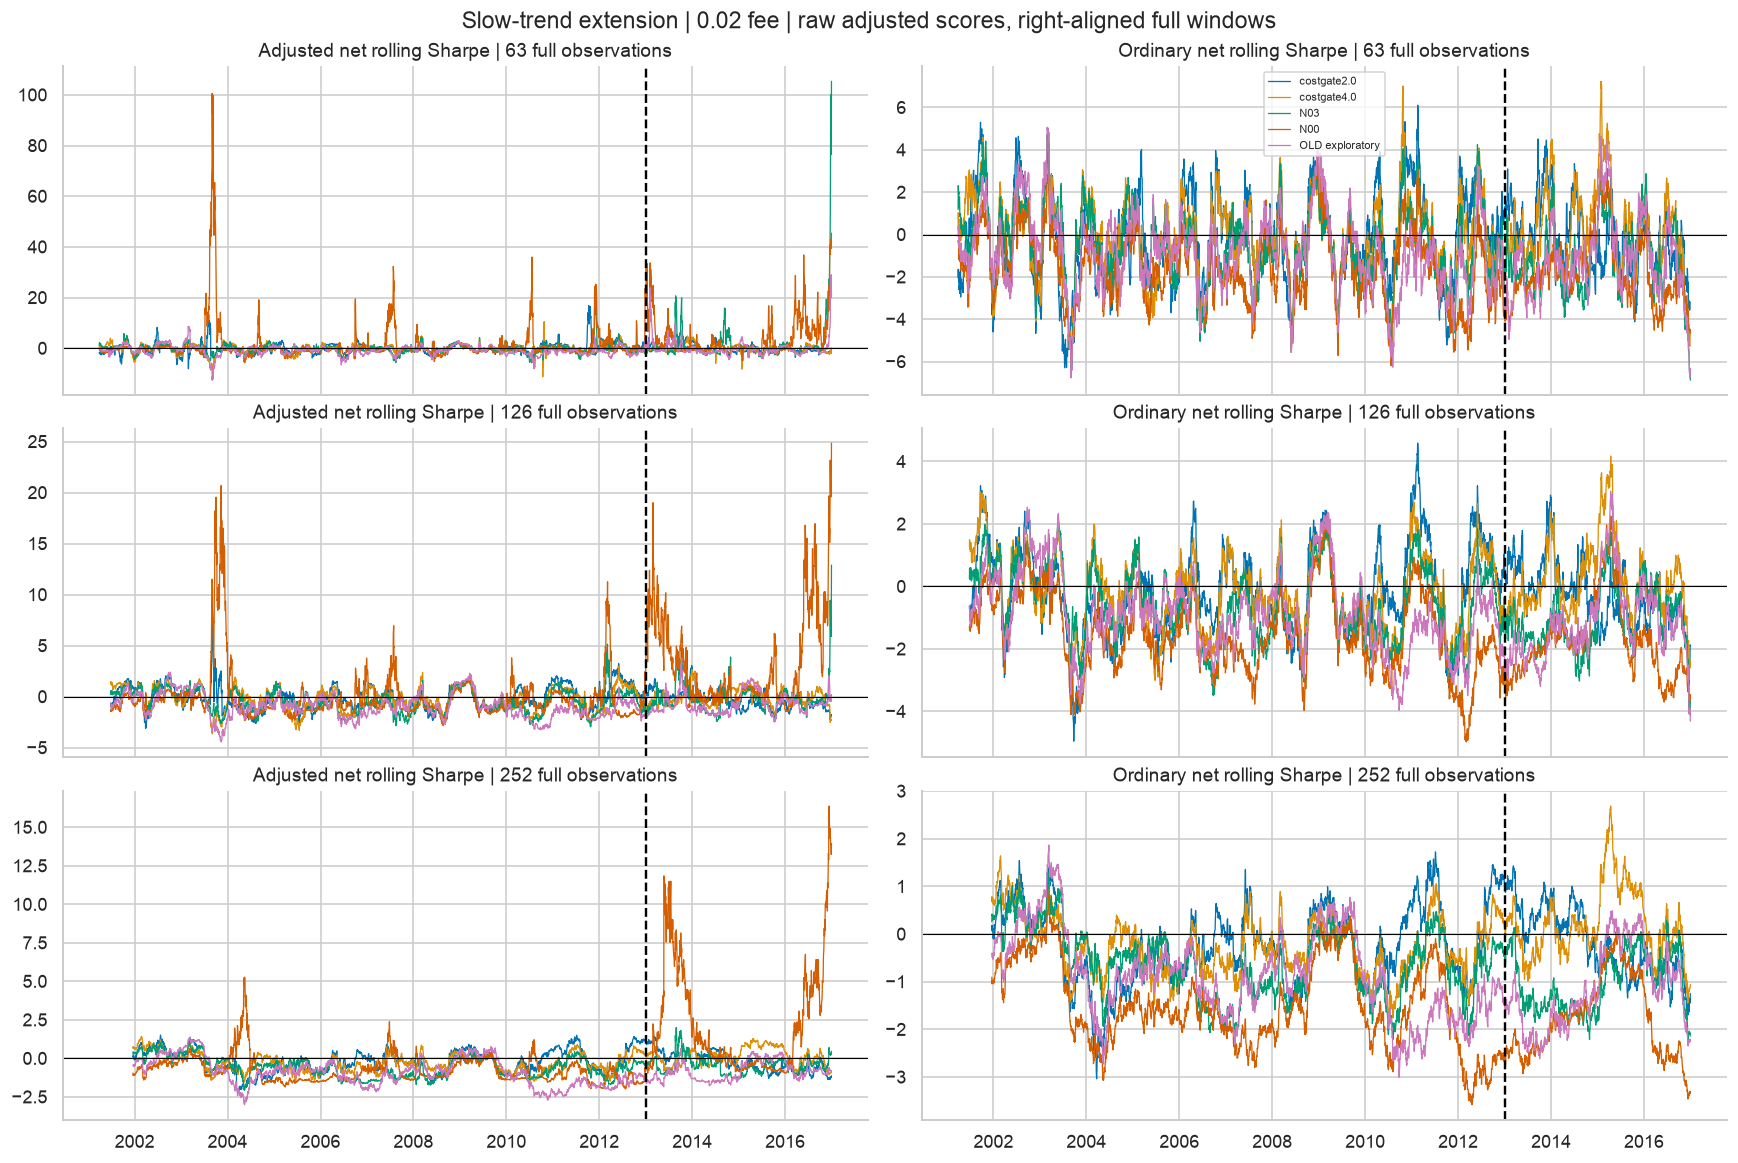

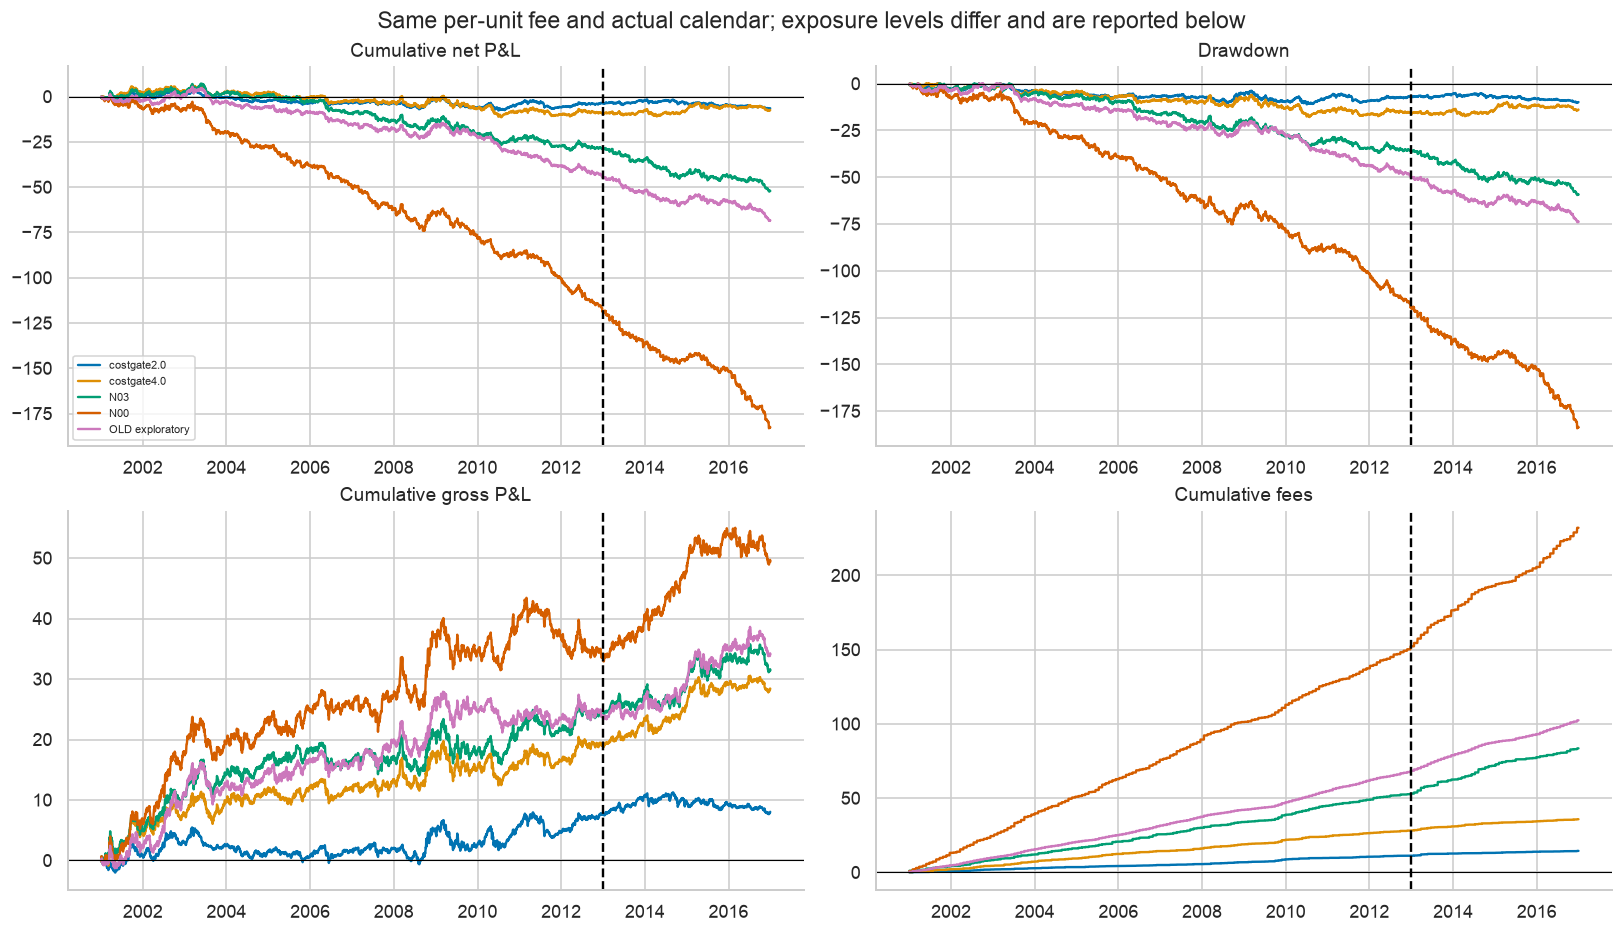

In [25]:
plot_runs={**slow_full,'OLD exploratory':holdout_results[primary]}
fig,axes=plt.subplots(3,2,figsize=(15,10),sharex=True,layout='constrained')
for row,w in enumerate(SET['rolling_windows']):
    for n,r in plot_runs.items():
        y=r['daily'].net.loc[ALL_DATES]; roll=y.rolling(w,min_periods=w)
        ordinary=np.sqrt(252)*roll.mean()/roll.std(ddof=1)
        adjusted=ordinary*(1+ordinary*roll.skew()/6-ordinary**2*roll.kurt()/24)
        # Pandas rolling skew/kurt use the same bias-corrected conventions.
        endpoint=y.iloc[:w]
        np.testing.assert_allclose(adjusted.iloc[w-1],score(endpoint)['adjusted'],rtol=1e-7,atol=1e-7)
        axes[row,0].plot(y.index,adjusted,label=n,lw=.8)
        axes[row,1].plot(y.index,ordinary,label=n,lw=.8)
    for ax,label in zip(axes[row],['Adjusted','Ordinary']):
        ax.axhline(0,color='black',lw=.7);ax.axvline(pd.Timestamp('2013-01-01'),color='black',ls='--')
        ax.set_title(f'{label} net rolling Sharpe | {w} full observations')
axes[0,1].legend(fontsize=7)
fig.suptitle('Slow-trend extension | 0.02 fee | raw adjusted scores, right-aligned full windows')
fig.savefig(SLOW_OUT/'rolling_scores.png',bbox_inches='tight');plt.show()

fig,axes=plt.subplots(2,2,figsize=(14,8),layout='constrained')
for n,r in plot_runs.items():
    d=r['daily'].loc[ALL_DATES]
    for ax,y in zip(axes.flat,[d.net.cumsum(),drawdown(d.net),d.gross.cumsum(),d.fees.cumsum()]): ax.plot(d.index,y,label=n)
for ax,label in zip(axes.flat,['Cumulative net P&L','Drawdown','Cumulative gross P&L','Cumulative fees']):
    ax.set_title(label);ax.axvline(pd.Timestamp('2013-01-01'),color='black',ls='--');ax.axhline(0,color='black',lw=.7)
axes[0,0].legend(fontsize=7)
fig.suptitle('Same per-unit fee and actual calendar; exposure levels differ and are reported below')
fig.savefig(SLOW_OUT/'pnl_costs.png',bbox_inches='tight');plt.show()

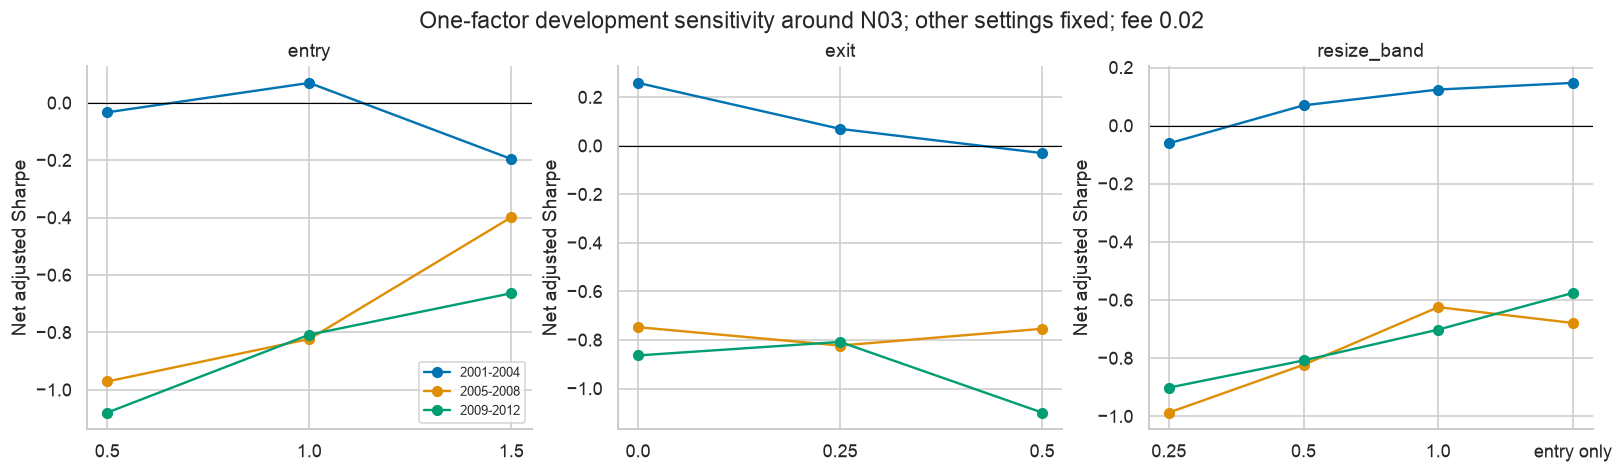

,name,period,fee,adjusted,sharpe,mean_net,net_pnl
0,costgate2.0,DEVELOPMENT,0.0000,0.2396,0.2423,0.0024,7.5823
1,costgate2.0,DEVELOPMENT,0.0100,0.0624,0.0624,0.0006,1.9612
2,costgate2.0,DEVELOPMENT,0.0200,-0.1154,-0.1155,-0.0012,-3.6599
3,costgate2.0,DEVELOPMENT,0.0400,-0.4485,-0.4554,-0.0048,-14.9022
4,costgate2.0,2013-2016 REUSED,0.0000,0.0590,0.0593,0.0004,0.4635
5,costgate2.0,2013-2016 REUSED,0.0100,-0.1480,-0.1467,-0.0011,-1.1565
6,costgate2.0,2013-2016 REUSED,0.0200,-0.3504,-0.3452,-0.0027,-2.7766
7,costgate2.0,2013-2016 REUSED,0.0400,-0.6652,-0.6995,-0.0058,-6.0167
8,costgate4.0,DEVELOPMENT,0.0000,0.4275,0.4393,0.0061,18.9402
9,costgate4.0,DEVELOPMENT,0.0100,0.1102,0.1106,0.0015,4.8174


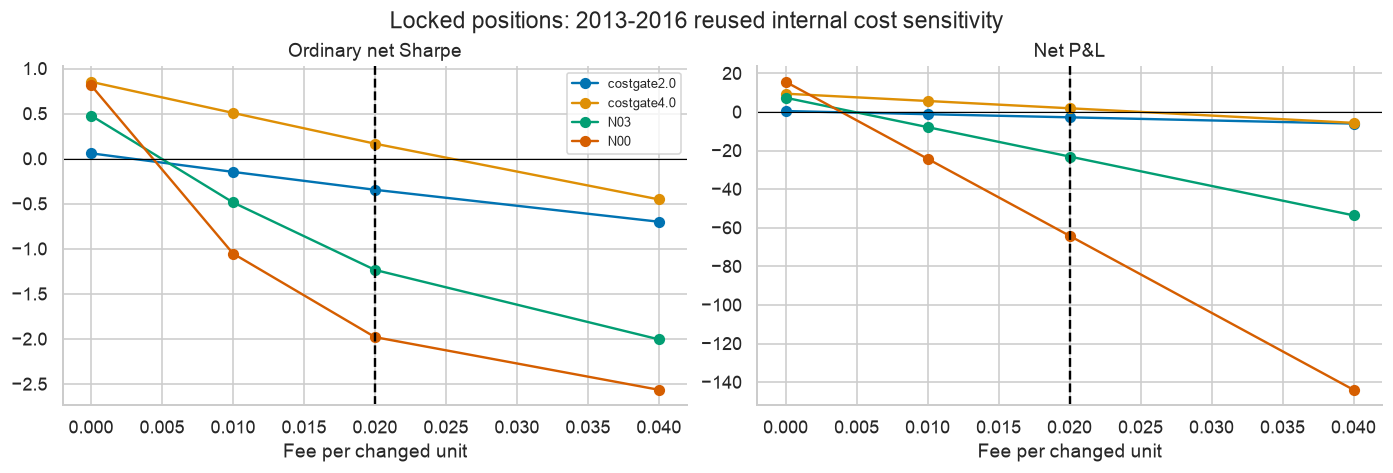

In [26]:
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,field,values in zip(axes,['entry','exit','resize_band'],
                         [SLOWSET['entry_levels'],SLOWSET['exit_levels'],SLOWSET['resize_bands']]):
    names=[next(n for n,c in slow_configs.items() if c==replace(slow_base,**{field:v})) for v in values]
    for period in BLOCKS:
        ys=[slow_blocks[(slow_blocks.name==n)&(slow_blocks.period==period)].adjusted.iloc[0] for n in names]
        ax.plot(range(len(values)),ys,marker='o',label=period)
    ax.set_xticks(range(len(values)),['entry only' if v==1e9 else str(v) for v in values])
    ax.set_title(field);ax.axhline(0,color='black',lw=.7);ax.set_ylabel('Net adjusted Sharpe')
axes[0].legend(fontsize=8)
fig.suptitle('One-factor development sensitivity around N03; other settings fixed; fee 0.02')
fig.savefig(SLOW_OUT/'parameter_sensitivity.png',bbox_inches='tight');plt.show()
cost_rows=[]
for n,r in slow_full.items():
    for period,dates in [('DEVELOPMENT',DEV_DATES),('2013-2016 REUSED',HOLD_DATES)]:
        d=r['daily'].loc[dates]
        for fee in SET['cost_sensitivity']:
            y=d.gross-fee*d.traded_units
            cost_rows.append(dict(name=n,period=period,fee=fee,mean_net=y.mean(),net_pnl=y.sum(),**score(y)))
cost_rows=pd.DataFrame(cost_rows);cost_rows.to_csv(SLOW_OUT/'cost_sensitivity.csv',index=False)
display(cost_rows[['name','period','fee','adjusted','sharpe','mean_net','net_pnl']])
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for n in slow_main:
    f=cost_rows[(cost_rows.name==n)&cost_rows.period.str.contains('REUSED')]
    axes[0].plot(f.fee,f.sharpe,marker='o',label=n);axes[1].plot(f.fee,f.net_pnl,marker='o',label=n)
for ax,title in zip(axes,['Ordinary net Sharpe','Net P&L']):
    ax.axvline(.02,color='black',ls='--');ax.axhline(0,color='black',lw=.7);ax.set_title(title);ax.set_xlabel('Fee per changed unit')
axes[0].legend(fontsize=8);fig.suptitle('Locked positions: 2013-2016 reused internal cost sensitivity')
fig.savefig(SLOW_OUT/'cost_sensitivity.png',bbox_inches='tight');plt.show()

## Exposure, legs, uncertainty and concentration

The new fixed-per-name risk budget deliberately leaves unused allocations in cash and permits directional
exposure. A higher score could therefore reflect long exposure rather than stronger winner-minus-loser
prediction. Actual executed long and short risk units, net notional and leg contributions are reported.
Bootstrap intervals remain descriptive after both rounds of searching and reused internal evaluation.

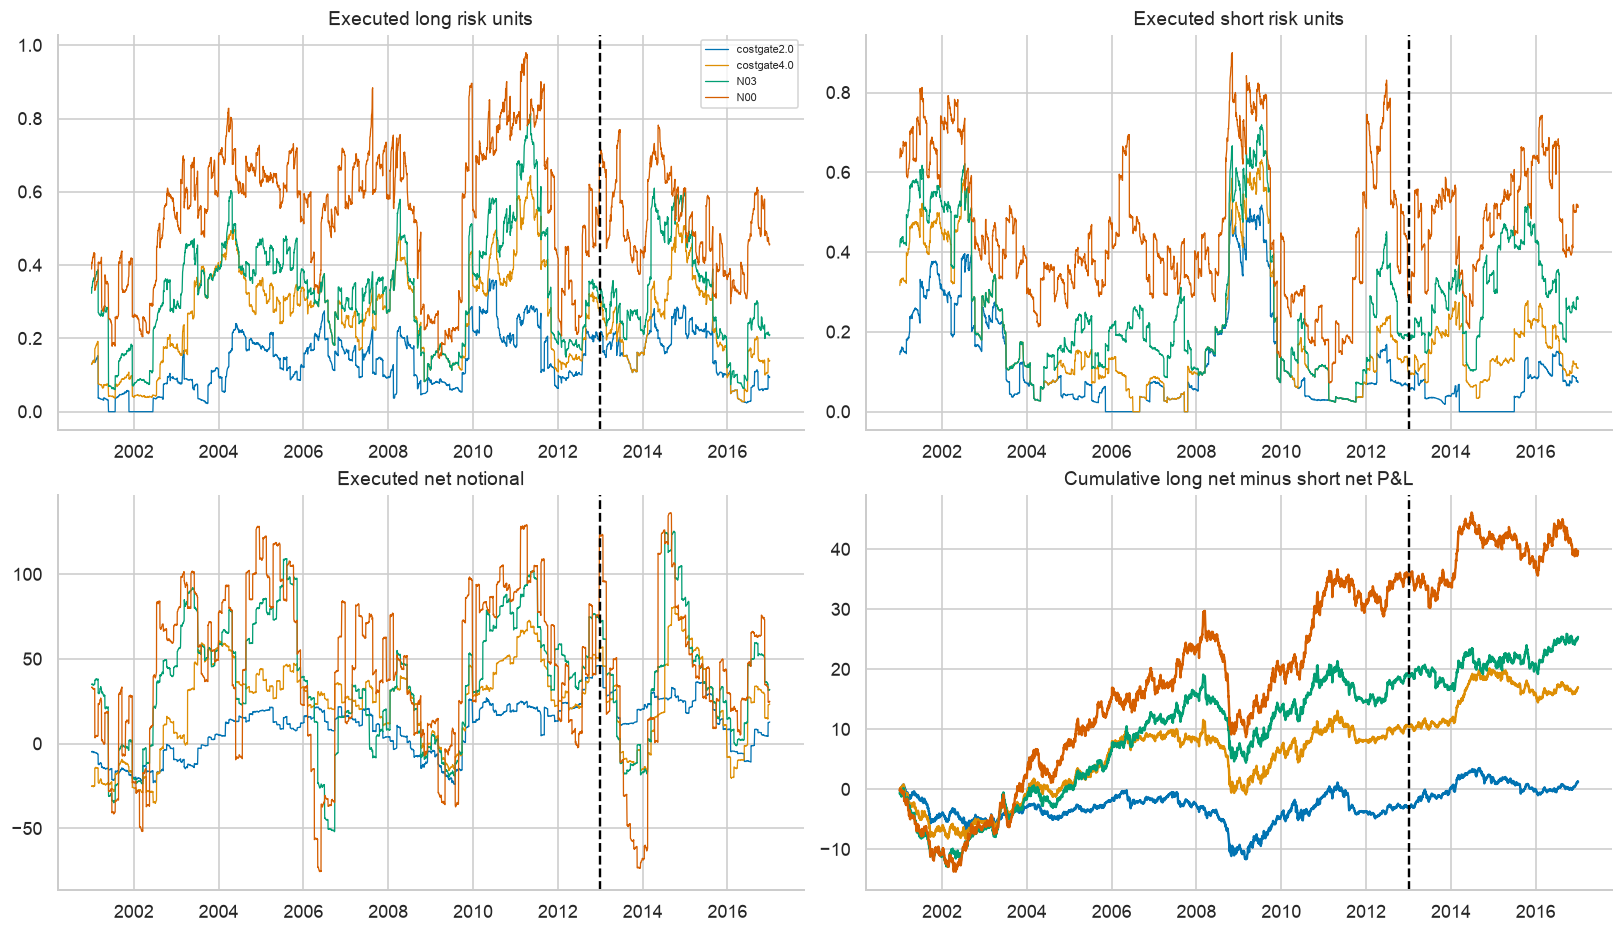

,name,period,long_gross,short_gross,long_fees,short_fees,long_net,short_net
0,costgate2.0,DEVELOPMENT,1.7736,5.8087,5.1064,6.1359,-3.3328,-0.3272
1,costgate2.0,2013-2016 REUSED,2.5568,-2.0933,1.8535,1.3866,0.7033,-3.4799
2,costgate4.0,DEVELOPMENT,15.2197,3.7205,14.5932,13.6525,0.6265,-9.9320
3,costgate4.0,2013-2016 REUSED,7.8270,1.6402,3.7053,3.8532,4.1217,-2.2130
4,N03,DEVELOPMENT,22.5748,1.4630,27.5864,25.4718,-5.0116,-24.0088
5,N03,2013-2016 REUSED,4.4536,2.9133,12.8014,17.6672,-8.3478,-14.7539
6,N00,DEVELOPMENT,36.6477,-2.9012,78.2019,74.0534,-41.5542,-76.9546
7,N00,2013-2016 REUSED,8.7462,6.8710,38.6774,41.1190,-29.9311,-34.2480


,name,period,long_risk,short_risk,net_notional
0,costgate2.0,DEVELOPMENT,0.1339,0.1362,6.7512
1,costgate2.0,2013-2016 REUSED,0.1570,0.0492,17.8278
2,costgate4.0,DEVELOPMENT,0.2674,0.1972,24.0443
3,costgate4.0,2013-2016 REUSED,0.2347,0.1525,23.4094
4,N03,DEVELOPMENT,0.3351,0.2548,37.6471
5,N03,2013-2016 REUSED,0.3170,0.3042,36.0974
6,N00,DEVELOPMENT,0.5493,0.4537,46.9695
7,N00,2013-2016 REUSED,0.5110,0.4934,35.3551


,pair,score_difference,low,high,fraction_above_zero,ordinary_difference,ordinary_low,ordinary_high,valid
0,costgate2.0 minus OLD exploratory,0.8770,-0.0591,1.6798,0.9673,0.9319,-0.1018,1.8116,1500
1,costgate2.0 minus costgate4.0,-0.5138,-1.2718,0.2592,0.1167,-0.5115,-1.4072,0.2631,1500
2,costgate2.0 minus N03,0.6093,-1.3000,1.3319,0.8167,0.8887,-0.0330,1.7697,1500
3,costgate2.0 minus N00,-2.1643,-6.7100,0.7173,0.1060,1.6342,0.7009,2.4224,1500


,deletion,net_pnl,adjusted,sharpe,mean,sd,skew,excess,factor
0,all,-2.7766,-0.3504,-0.3452,-0.0027,0.1235,-0.6295,4.2794,1.0150
1,drop best year,-4.5766,-0.7304,-0.7578,-0.0059,0.1237,-0.3974,3.6058,0.9639
2,drop best quarter,-4.1297,-0.5455,-0.5434,-0.0043,0.1245,-0.6378,4.3916,1.0037
3,drop best 5 days,-4.9978,-0.6632,-0.6445,-0.0049,0.1196,-0.9237,4.0548,1.0290
4,drop best asset titan_stocks,-4.7184,-0.6533,-0.6618,-0.0046,0.1095,-0.6318,4.5187,0.9872


,internal_net_pnl
water,-1.7125
callisto_stocks,-0.9663
ultrapure_silicon,-0.8214
titan_bonds,-0.6475
nanocapacitors,-0.6002
ganymede_bonds,-0.2141
ganymede_stocks,-0.1715
helium3,-0.1515
io_bonds,-0.0671
europa_stocks,-0.0185


,annual_net_pnl
AsOfDate,
2013,1.8000
2014,-1.5704
2015,-1.2488
2016,-1.7574


In [27]:
slow_leg_rows=[];slow_exposure=[]
fig,axes=plt.subplots(2,2,figsize=(14,8),layout='constrained')
for n,r in slow_full.items():
    l=leg_pnl(r)
    e=r['x'].shift(1).fillna(0)*r['vol']
    er=pd.DataFrame({'long_risk':e.clip(lower=0).sum(axis=1),
                     'short_risk':-e.clip(upper=0).sum(axis=1),
                     'net_notional':(r['x'].shift(1).fillna(0)*P).sum(axis=1)})
    for period,dates in [('DEVELOPMENT',DEV_DATES),('2013-2016 REUSED',HOLD_DATES)]:
        slow_leg_rows.append(dict(name=n,period=period,**l.loc[dates].sum().to_dict()))
        slow_exposure.append(dict(name=n,period=period,**er.loc[dates].mean().to_dict()))
    axes[0,0].plot(ALL_DATES,er.long_risk.loc[ALL_DATES],label=n,lw=.8)
    axes[0,1].plot(ALL_DATES,er.short_risk.loc[ALL_DATES],label=n,lw=.8)
    axes[1,0].plot(ALL_DATES,er.net_notional.loc[ALL_DATES],label=n,lw=.8)
    axes[1,1].plot(ALL_DATES,(l.long_net-l.short_net).loc[ALL_DATES].cumsum(),label=n)
for ax,title in zip(axes.flat,['Executed long risk units','Executed short risk units','Executed net notional','Cumulative long net minus short net P&L']):
    ax.set_title(title);ax.axvline(pd.Timestamp('2013-01-01'),color='black',ls='--')
axes[0,0].legend(fontsize=7);fig.savefig(SLOW_OUT/'exposures.png',bbox_inches='tight');plt.show()
display(pd.DataFrame(slow_leg_rows));display(pd.DataFrame(slow_exposure))
pd.DataFrame(slow_leg_rows).to_csv(SLOW_OUT/'leg_pnl.csv',index=False)
pd.DataFrame(slow_exposure).to_csv(SLOW_OUT/'exposures.csv',index=False)
rng=np.random.default_rng(SLOWSET['seed'])
slow_boot=[]
for other in ['OLD exploratory']+[n for n in slow_main if n!=slow_primary]:
    a=slow_full[slow_primary]['daily'].net.loc[HOLD_DATES]
    b=plot_runs[other]['daily'].net.loc[HOLD_DATES]
    slow_boot.append(dict(pair=f'{slow_primary} minus {other}',**paired_bootstrap(a,b,20,SLOWSET['bootstrap_repetitions'])))
slow_boot=pd.DataFrame(slow_boot);display(slow_boot);slow_boot.to_csv(SLOW_OUT/'paired_bootstrap.csv',index=False)
slow_frag=[]
r=slow_full[slow_primary]; y=r['daily'].net.loc[HOLD_DATES]
asset=r['asset_net'].loc[HOLD_DATES].sum();best_asset=asset.idxmax()
annual=y.groupby(y.index.year).sum();quarter=y.groupby(y.index.to_period('Q')).sum()
for label,ids in [('all',y.index),('drop best year',y.index[y.index.year!=annual.idxmax()]),
                  ('drop best quarter',y.index[y.index.to_period('Q')!=quarter.idxmax()]),
                  ('drop best 5 days',y.index.difference(y.nlargest(5).index))]:
    slow_frag.append(dict(deletion=label,net_pnl=y.loc[ids].sum(),**score(y.loc[ids])))
deleted=y-r['asset_net'].loc[HOLD_DATES,best_asset]
slow_frag.append(dict(deletion='drop best asset '+best_asset,net_pnl=deleted.sum(),**score(deleted)))
display(pd.DataFrame(slow_frag));pd.DataFrame(slow_frag).to_csv(SLOW_OUT/'fragility.csv',index=False)
display(asset.sort_values().rename('internal_net_pnl').to_frame())
display(annual.rename('annual_net_pnl').to_frame())

## Stateful prefix, threshold and accounting validation

Regenerate every desired position through each cutoff independently. These checks cover entry/exit state,
the volatility anchor used for sizing and the anchored rebalance schedule. No terminal liquidation or future
normalization is allowed. Original hand-worked fee tests still apply to this same backtest engine.

In [28]:
slow_checks=[]
for n,r in slow_full.items():
    c=slow_configs[n]
    for cutoff in SLOWSET['prefix_cutoffs']:
        sub=P.loc[:cutoff]; reg=slow_positions(sub,c,0.02)['x']
        actual=r['x'].loc[sub.index]
        np.testing.assert_allclose(actual,reg,rtol=1e-10,atol=1e-10)
        slow_checks.append(dict(name=n,cutoff=cutoff,rows=len(sub),max_error=np.max(np.abs(actual.to_numpy()-reg.to_numpy()))))
    delta=r['x'].diff();delta.iloc[0]=r['x'].iloc[0]
    np.testing.assert_allclose(r['daily'].fees,.02*delta.shift(2).fillna(0).abs().sum(axis=1))
    assert np.isfinite(r['x'].to_numpy()).all()
    # Fixed per-name risk allocation holds relative to its own last sizing volatility.
    active=r['x'].abs()>0
    sizing_risk=(r['x'].abs()*r['anchor_vol']).where(active).stack().dropna()
    np.testing.assert_allclose(sizing_risk,c.total_risk_budget/len(P.columns),atol=1e-10)
    ev=r['events']
    for event in ev.itertuples(index=False):
        s=r['signal'].loc[event.date,event.asset]
        if event.reason in ['entry','reversal']: assert abs(s)>c.entry
    if len(ev):
        assert (P.index.get_indexer(ev.date)%c.frequency==0).all()
display(pd.DataFrame(slow_checks));pd.DataFrame(slow_checks).to_csv(SLOW_OUT/'prefix_tests.csv',index=False)
# Flat input targets and a reversal retain the original engine's exact fee treatment.
assert backtest(P,P*0,.02)['daily'][['net','fees']].to_numpy().sum()==0
print('PASS: prefix invariance, fee identities, fixed sizing anchors, entry thresholds and rebalance schedules.')

,name,cutoff,rows,max_error
0,costgate2.0,2004-12-31,2594,0.0000
1,costgate2.0,2008-12-31,3631,0.0000
2,costgate2.0,2012-12-31,4668,0.0000
3,costgate2.0,2015-06-30,5314,0.0000
4,costgate4.0,2004-12-31,2594,0.0000
5,costgate4.0,2008-12-31,3631,0.0000
6,costgate4.0,2012-12-31,4668,0.0000
7,costgate4.0,2015-06-30,5314,0.0000
8,N03,2004-12-31,2594,0.0000
9,N03,2008-12-31,3631,0.0000


PASS: prefix invariance, fee identities, fixed sizing anchors, entry thresholds and rebalance schedules.


### What the extension changed

The matched controls support the trading-cost mechanism, but not a Sharpe of 1-2. In the reused
2013-2016 period, N00 (no hysteresis, frequent resizing) paid 79.80 in fees and had net Sharpe -1.979.
N03 (entry 1, exit 0.25, a 50% volatility sizing band) paid 30.47 and had net Sharpe -1.234.
The development-selected cost gate reduced fees to 3.24 and improved net Sharpe to -0.345,
but also reduced gross P&L to just 0.46. This filter removed much of the trading along with the costs.
The wider cost-gate fallback earned 1.91 net with net Sharpe +0.166 in the reused period, but its
development median ordinary net Sharpe was -0.278; choosing it now because of that internal result
would be another round of selection on already-inspected data.

The primary-minus-original exploratory ordinary-Sharpe improvement was +0.932, with descriptive
paired 20-observation-block 95% interval [-0.102, 1.812]. The primary-minus-fallback difference was
-0.511, interval [-1.407, 0.263]. These intervals do not establish a robust improvement. The new
primary's long leg contributed +0.70 net, its short leg -3.48; it remained unprofitable after removing
its best year, quarter, five days or best asset. There is no broad positive edge hidden by one bad day.

The result is a useful negative finding: hysteresis and infrequent sizing reduce the cost damage,
but this small, explicit study has not found a sufficiently strong momentum signal at fee 0.02.
No untested parameter change or holdout-selected winner is recommended as profitable.


In [29]:
new_eligible=bool(slow_selection.loc[slow_primary,'eligible'])
h=comparison.loc[slow_primary]
decision=(f'Submit {slow_primary}, the frozen development choice.' if new_eligible else
          'Keep the flat-book submission recommendation: the extension also failed the development eligibility rule.')
slow_report=f"""## Slow-trend extension: executed decision

**{decision}** The trading candidate is **{slow_primary}**, with **{slow_fallback}** as its one-factor fallback.
These names were frozen before their new internal-period scores were computed. Both development
and the already-inspected 2013-2016 period must be considered when interpreting the evidence.

Of {len(slow_configs)} new configurations, {int(slow_selection.eligible.sum())} passed the development rule.
Primary development median ordinary net Sharpe: {slow_selection.loc[slow_primary,'median_ordinary']:.3f};
median adjusted: {slow_selection.loc[slow_primary,'median_adjusted']:.3f}.
The primary's 2013-2016 net Sharpe is **{h.net_sharpe:.3f}**, adjusted score **{h.adjusted:.3f}**,
net P&L **{h.net_pnl:.2f}**, gross P&L **{h.gross_pnl:.2f}**, fees **{h.fees:.2f}**,
holding period **{h.holding_days:.1f}** observations, and break-even fee **{h.break_even_cost:.5f}**.
The actual fee remains **0.02**. The original exploratory candidate's net Sharpe was -1.277 and
net P&L -23.87 on those dates. Different exposure budgets mean absolute P&L differences alone
are not a like-for-like measure of alpha; the risk and leg diagnostics show the actual positions.

**Exact primary settings:** `{json.dumps(asdict(slow_configs[slow_primary]),sort_keys=True)}`

**Exact fallback settings:** `{json.dumps(asdict(slow_configs[slow_fallback]),sort_keys=True)}`

The grid did not target a desired Sharpe. A result below 1 or a loss is reported as computed.
All raw scores, including score-sign reversals, remain visible. The bootstrap and deletion diagnostics
describe sensitivity; they do not repair reused validation or establish competition-holdout performance.
"""
display(Markdown(slow_report));(SLOW_OUT/'recommendation.md').write_text(slow_report)
slow_export={**slow_lock,'primary_config':asdict(slow_configs[slow_primary]),
             'fallback_config':asdict(slow_configs[slow_fallback]),'lock_sha256':slow_lock_sha}
(SLOW_OUT/'strategy_config.json').write_text(json.dumps(slow_export,indent=2,sort_keys=True))
targets=generate_slow_targets(PRICE_FILE,slow_configs[slow_primary],flat=not new_eligible)
targets.to_csv(SLOW_OUT/'daily_target_positions.csv',index_label='AsOfDate')
generate_slow_targets(PRICE_FILE,slow_configs[slow_fallback],SLOW_OUT/'fallback_target_positions.csv')
for n,r in slow_full.items(): r['daily'].to_csv(SLOW_OUT/f'daily_pnl_{n.replace(":","_")}.csv')
assert hashlib.sha256((SLOW_OUT/'finalists_lock.json').read_bytes()).hexdigest()==slow_lock_sha
print('Saved extension results, locked configurations and reusable positions.')

## Slow-trend extension: executed decision

**Keep the flat-book submission recommendation: the extension also failed the development eligibility rule.** The trading candidate is **costgate2.0**, with **costgate4.0** as its one-factor fallback.
These names were frozen before their new internal-period scores were computed. Both development
and the already-inspected 2013-2016 period must be considered when interpreting the evidence.

Of 17 new configurations, 0 passed the development rule.
Primary development median ordinary net Sharpe: -0.155;
median adjusted: -0.156.
The primary's 2013-2016 net Sharpe is **-0.345**, adjusted score **-0.350**,
net P&L **-2.78**, gross P&L **0.46**, fees **3.24**,
holding period **195.3** observations, and break-even fee **0.00286**.
The actual fee remains **0.02**. The original exploratory candidate's net Sharpe was -1.277 and
net P&L -23.87 on those dates. Different exposure budgets mean absolute P&L differences alone
are not a like-for-like measure of alpha; the risk and leg diagnostics show the actual positions.

**Exact primary settings:** `{"agreement": false, "cost_gate": 2.0, "entry": 1.0, "exit": 0.25, "frequency": 21, "lookbacks": [252], "rank_vol": 63, "resize_band": 0.5, "size_vol": 63, "total_risk_budget": 1.0, "warmup": 1008}`

**Exact fallback settings:** `{"agreement": false, "cost_gate": 4.0, "entry": 1.0, "exit": 0.25, "frequency": 21, "lookbacks": [252], "rank_vol": 63, "resize_band": 0.5, "size_vol": 63, "total_risk_budget": 1.0, "warmup": 1008}`

The grid did not target a desired Sharpe. A result below 1 or a loss is reported as computed.
All raw scores, including score-sign reversals, remain visible. The bootstrap and deletion diagnostics
describe sensitivity; they do not repair reused validation or establish competition-holdout performance.


Saved extension results, locked configurations and reusable positions.
